In [ ]:
# 1. Install required libraries
!pip install -q kaggle mediapipe opencv-python-headless numpy pandas tqdm

# 2. Upload your kaggle.json file when prompted
from google.colab import files
files.upload()

# 3. Configure Kaggle API & download ISL-CSLTR (~1.2 GB)
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d drblack00/isl-csltr-indian-sign-language-dataset
!unzip -q isl-csltr-indian-sign-language-dataset.zip -d ./isl_data
print("Dataset downloaded and extracted successfully!")


Saving kaggle (1).json to kaggle (1).json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/drblack00/isl-csltr-indian-sign-language-dataset
License(s): CC-BY-SA-4.0
100% 8.29G/8.29G [01:55<00:00, 77.2MB/s]

Dataset downloaded and extracted successfully!


In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

!cp "/content/kaggle (1).json" /root/.kaggle/kaggle.json

!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!unzip -q /content/isl-csltr-indian-sign-language-dataset.zip -d /content/ISL-CSLTR

In [ ]:
import os

dataset_path = "/content/ISL-CSLTR"

for root, dirs, files in os.walk(dataset_path):
    print(root, " | Folders:", len(dirs), "| Files:", len(files))
    if root.count(os.sep) - dataset_path.count(os.sep) >= 2:
        dirs[:] = []

/content/ISL-CSLTR  | Folders: 1 | Files: 0
/content/ISL-CSLTR/ISL_CSLRT_Corpus  | Folders: 1 | Files: 0
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus  | Folders: 4 | Files: 1


In [ ]:
import os

DATASET_PATH = "/content/ISL-CSLTR"

print("DATASET STRUCTURE\n")

for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

DATASET STRUCTURE

ISL-CSLTR/
    ISL_CSLRT_Corpus/
        ISL_CSLRT_Corpus/
            ISL_CSLRT.txt
            corpus_csv_files/
                ISL_CSLRT_Corpus details.xlsx
                ISL_CSLRT_Corpus_word_details.xlsx
                ISL_CSLRT_Corpus_frame_details.xlsx
                ISL Corpus sign glosses.csv
            Videos_Sentence_Level/
                i do not mean it/
                    mean (2).MP4
                    mean (4).MP4
                    mean.MP4
                    mean (3).MP4
                    mean (5).MP4
                    i do not mean it (3).mp4
                    i do not mean it.mp4
                He is going into the room/
                    room.MP4
                    he is going into the room (2).mp4
                    MVI_6503.MP4
                    room (3).MP4
                    room (4).MP4
                    room (2).MP4
                    he is going into the room.mp4
                which collegeschool are you from/

In [ ]:
from collections import Counter

extensions = Counter()

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        extensions[ext] += 1

print("File types found:")
for ext, count in extensions.items():
    print(ext, ":", count)

File types found:
.txt : 1
.xlsx : 3
.csv : 1
.mp4 : 687
.jpg : 19899
.db : 483


In [ ]:
import os

DATASET_PATH = "/content/ISL-CSLTR"

# Display video filenames
print("========== VIDEOS ==========")

video_count = 0

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(".mp4"):
            print(os.path.join(root, file))
            video_count += 1

            if video_count >= 15:
                break

    if video_count >= 15:
        break

# Display metadata files
print("\n========== METADATA FILES ==========")

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".txt")):
            print(os.path.join(root, file))

========== VIDEOS ==========
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/mean (2).MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/mean (4).MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/mean.MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/mean (3).MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/mean (5).MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/i do not mean it (3).mp4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i do not mean it/i do not mean it.mp4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/room.MP4
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/he is goi

In [ ]:
import pandas as pd
import os

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        path = os.path.join(root, file)

        if file.endswith(".csv"):
            print("\nCSV:", file)
            df = pd.read_csv(path)
            print(df.head())
            print("Columns:", df.columns.tolist())

        elif file.endswith(".xlsx"):
            print("\nEXCEL:", file)

            excel = pd.ExcelFile(path)

            for sheet in excel.sheet_names:
                print("\nSheet:", sheet)
                df = pd.read_excel(path, sheet_name=sheet)
                print(df.head())
                print("Columns:", df.columns.tolist())


EXCEL: ISL_CSLRT_Corpus details.xlsx

Sheet: Sheet1
            Sentences                                      File location
0  are you free today  ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
1  are you free today  ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
2  are you free today  ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
3  are you free today  ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
4  are you free today  ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
Columns: ['Sentences', 'File location']

Sheet: Sheet2
Empty DataFrame
Columns: []
Index: []
Columns: []

Sheet: Sheet3
Empty DataFrame
Columns: []
Index: []
Columns: []

EXCEL: ISL_CSLRT_Corpus_word_details.xlsx

Sheet: export_dataframe
    Word                                        Frames path
0  A LOT  ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...
1  A LOT  ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...
2  A LOT  ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...
3  A LOT  ISL_CSLRT_Corpus\Fram

In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR"

# Locate annotation files
for root, dirs, files in os.walk(BASE):
    for file in files:
        if file == "ISL_CSLRT_Corpus_details.xlsx":
            details_path = os.path.join(root, file)

        if file == "ISL Corpus sign glosses.csv":
            gloss_path = os.path.join(root, file)

print("Details:", details_path)
print("Glosses:", gloss_path)

# Read annotations
details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("\nVIDEO ANNOTATIONS")
print(details.head(10))

print("\nGLOSS ANNOTATIONS")
print(glosses.head(10))

print("\nTOTAL VIDEO ANNOTATION ROWS:", len(details))
print("UNIQUE SENTENCES:", details["Sentences"].nunique())
print("TOTAL GLOSS ROWS:", len(glosses))
print("UNIQUE GLOSS SENTENCES:", glosses["Sentence"].nunique())

NameError: name 'details_path' is not defined

In [ ]:
import os

BASE = "/content/ISL-CSLTR"

details_path = None
gloss_path = None

for root, dirs, files in os.walk(BASE):

    for file in files:

        if file == "ISL_CSLRT_Corpus_details.xlsx":
            details_path = os.path.join(root, file)

        elif file == "ISL Corpus sign glosses.csv":
            gloss_path = os.path.join(root, file)

print("Details file:", details_path)
print("Gloss file:", gloss_path)

assert details_path is not None, "Excel annotation file not found!"
assert gloss_path is not None, "Gloss CSV file not found!"

Details file: None
Gloss file: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv


AssertionError: Excel annotation file not found!

In [ ]:
import os

BASE = "/content/ISL-CSLTR"

excel_files = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith(".xlsx"):
            full_path = os.path.join(root, file)
            excel_files.append(full_path)
            print("FOUND:", full_path)

print("\nTotal Excel files:", len(excel_files))

FOUND: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
FOUND: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_word_details.xlsx
FOUND: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_frame_details.xlsx

Total Excel files: 3


In [ ]:
import pandas as pd

for path in excel_files:
    print("\n" + "="*60)
    print("FILE:", os.path.basename(path))

    xl = pd.ExcelFile(path)

    for sheet in xl.sheet_names:
        df = pd.read_excel(path, sheet_name=sheet)

        print("\nSheet:", sheet)
        print("Columns:", df.columns.tolist())
        print("Rows:", len(df))
        display(df.head(3))


FILE: ISL_CSLRT_Corpus details.xlsx

Sheet: Sheet1
Columns: ['Sentences', 'File location']
Rows: 493


,Sentences,File location
0,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
1,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
2,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...



Sheet: Sheet2
Columns: []
Rows: 0


""



Sheet: Sheet3
Columns: []
Rows: 0


""



FILE: ISL_CSLRT_Corpus_word_details.xlsx

Sheet: export_dataframe
Columns: ['Word', 'Frames path']
Rows: 1036


,Word,Frames path
0,A LOT,ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...
1,A LOT,ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...
2,A LOT,ISL_CSLRT_Corpus\Frames_Word_Level\A LOT\A LOT...



FILE: ISL_CSLRT_Corpus_frame_details.xlsx

Sheet: export_dataframe
Columns: ['Sentence', 'Frames path']
Rows: 18863


,Sentence,Frames path
0,are you free today,ISL_CSLRT_Corpus\Frames_Sentence_Level\are you...
1,are you free today,ISL_CSLRT_Corpus\Frames_Sentence_Level\are you...
2,are you free today,ISL_CSLRT_Corpus\Frames_Sentence_Level\are you...


In [ ]:
import pandas as pd
import os

BASE = "/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"

# Load sentence annotations
details_path = os.path.join(
    BASE, "corpus_csv_files",
    "ISL_CSLRT_Corpus_details.xlsx"
)

gloss_path = os.path.join(
    BASE, "corpus_csv_files",
    "ISL Corpus sign glosses.csv"
)

details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("VIDEO ANNOTATIONS")
display(details.head())

print("\nGLOSS ANNOTATIONS")
display(glosses.head())

print("\nTotal annotated videos:", len(details))
print("Unique sentences:", details["Sentences"].nunique())
print("Total gloss entries:", len(glosses))
print("Unique gloss sentences:", glosses["Sentence"].nunique())

FileNotFoundError: [Errno 2] No such file or directory: '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_details.xlsx'

In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR"

details_path = None
gloss_path = None

for root, dirs, files in os.walk(BASE):
    for file in files:

        if file.lower() == "isl_cslrt_corpus details.xlsx":
            details_path = os.path.join(root, file)

        if file.lower() == "isl corpus sign glosses.csv":
            gloss_path = os.path.join(root, file)

print("Details:", details_path)
print("Glosses:", gloss_path)

# Load files
details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("\nVIDEO ANNOTATIONS")
display(details.head())

print("\nGLOSS ANNOTATIONS")
display(glosses.head())

print("\nTotal videos:", len(details))
print("Unique sentences:", details["Sentences"].nunique())
print("Total gloss entries:", len(glosses))

Details: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
Glosses: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv

VIDEO ANNOTATIONS


,Sentences,File location
0,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
1,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
2,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
3,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
4,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...



GLOSS ANNOTATIONS


,Sentence,SIGN GLOSSES
0,are you free today,YOU FREE TODAY
1,are you hiding something,YOU HIDE SOMETHING
2,bring water for me,BRING WATER ME
3,can i help you,I HELP YOU
4,can you repeat that please,YOU REPEAT PLEASE



Total videos: 493
Unique sentences: 101
Total gloss entries: 101


In [ ]:
import os

for i in range(10):

    relative_path = str(details.iloc[i]["File location"])
    relative_path = relative_path.replace("\\", "/")

    full_path = os.path.join(
        BASE,
        relative_path
    )

    print("\nSentence:", details.iloc[i]["Sentences"])
    print("Video:", full_path)
    print("Exists:", os.path.exists(full_path))


Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (2).MP4
Exists: False

Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (3).MP4
Exists: False

Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (4).MP4
Exists: False

Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (5).MP4
Exists: False

Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free.MP4
Exists: False

Sentence: are you hiding something
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you hiding something/MVI_6209.MP4
Exists: False

Sentence: are you hiding something
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you hiding something/MVI_6507.MP4
Exists:

In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR"

details_path = None
gloss_path = None

for root, dirs, files in os.walk(BASE):
    for file in files:

        normalized = file.lower().replace("_", "").replace(" ", "")

        if normalized == "islcslrtcorpusdetails.xlsx":
            details_path = os.path.join(root, file)

        if normalized == "islcorpussignglosses.csv":
            gloss_path = os.path.join(root, file)

print("Details:", details_path)
print("Glosses:", gloss_path)

assert details_path, "Details Excel file not found"
assert gloss_path, "Gloss CSV file not found"

details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("\nVideo annotations:", len(details))
print("Gloss annotations:", len(glosses))

display(details.head())
display(glosses.head())

Details: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
Glosses: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv

Video annotations: 493
Gloss annotations: 101


,Sentences,File location
0,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
1,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
2,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
3,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
4,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...


,Sentence,SIGN GLOSSES
0,are you free today,YOU FREE TODAY
1,are you hiding something,YOU HIDE SOMETHING
2,bring water for me,BRING WATER ME
3,can i help you,I HELP YOU
4,can you repeat that please,YOU REPEAT PLEASE


In [ ]:
!pip install -q mediapipe opencv-python-headless tqdm

In [ ]:
import cv2
import mediapipe as mp

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("MediaPipe installation successful!")

OpenCV: 4.14.0
MediaPipe: 1.2.3
MediaPipe installation successful!


In [ ]:
import os

print("Checking first 10 video paths:\n")

for i in range(min(10, len(details))):

    relative_path = str(details.iloc[i]["File location"])
    relative_path = relative_path.replace("\\", "/")

    # Search for the actual video using its filename
    filename = os.path.basename(relative_path)

    matches = []

    for root, dirs, files in os.walk(BASE):
        if filename in files:
            matches.append(os.path.join(root, filename))

    print("Sentence:", details.iloc[i]["Sentences"])
    print("Video:", matches[0] if matches else "NOT FOUND")
    print("Exists:", bool(matches))
    print("-" * 50)

Checking first 10 video paths:

Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (2).MP4
Exists: True
--------------------------------------------------
Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (3).MP4
Exists: True
--------------------------------------------------
Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (4).MP4
Exists: True
--------------------------------------------------
Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (5).MP4
Exists: True
--------------------------------------------------
Sentence: are you free today
Video: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free.MP4
E

In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import os

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

print("\nEnvironment ready!")

ModuleNotFoundError: No module named 'mediapipe'

In [ ]:
!pip install -q mediapipe opencv-python-headless numpy pandas tqdm openpyxl

In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import os

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

print("\nEnvironment ready!")

OpenCV: 4.14.0
MediaPipe: 1.2.3
NumPy: 2.4.6

Environment ready!


In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR"

# Automatically locate annotation files
details_path = None
gloss_path = None

for root, dirs, files in os.walk(BASE):
    for file in files:

        name = file.lower().replace("_", "").replace(" ", "")

        if name.endswith(".xlsx") and "corpusdetails" in name:
            details_path = os.path.join(root, file)

        if name == "islcorpussignglosses.csv":
            gloss_path = os.path.join(root, file)

assert details_path, "Sentence annotation file not found"
assert gloss_path, "Gloss annotation file not found"

details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("Sentence annotations:", len(details))
print("Gloss annotations:", len(glosses))

# Index video files
video_index = {}

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith(".mp4"):
            video_index.setdefault(file.lower(), []).append(
                os.path.join(root, file)
            )

# Match annotations to actual videos
valid_samples = []

for _, row in details.iterrows():

    relative_path = str(row["File location"]).replace("\\", "/")
    filename = os.path.basename(relative_path)

    matches = video_index.get(filename.lower(), [])

    if matches:
        valid_samples.append({
            "video_path": matches[0],
            "sentence": str(row["Sentences"]).strip()
        })

print("\nMatched videos:", len(valid_samples))
print("Unmatched annotations:", len(details) - len(valid_samples))

for sample in valid_samples[:5]:
    print(sample)

AssertionError: Sentence annotation file not found

In [ ]:
import os

BASE = "/content/ISL-CSLTR"

print("Dataset exists:", os.path.exists(BASE))

if os.path.exists(BASE):
    print("\nExcel files found:")

    for root, dirs, files in os.walk(BASE):
        for file in files:
            if file.endswith(".xlsx"):
                print(os.path.join(root, file))
else:
    print("Dataset is missing from Colab storage.")

Dataset exists: False
Dataset is missing from Colab storage.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("EchoGesture folder created!")

EchoGesture folder created!


In [ ]:
!pip install -q kaggle mediapipe opencv-python-headless numpy pandas tqdm openpyxl

In [ ]:
import mediapipe as mp
import cv2

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Installation successful!")

MediaPipe: 1.2.3
OpenCV: 4.14.0
Installation successful!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle (1).json to kaggle (1).json


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

uploaded_file = list(uploaded.keys())[0]

shutil.copy(
    uploaded_file,
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle authentication configured!")

Kaggle authentication configured!


In [ ]:
!kaggle datasets download \
-d drblack00/isl-csltr-indian-sign-language-dataset \
-p /content/drive/MyDrive/EchoGesture

Dataset URL: https://www.kaggle.com/datasets/drblack00/isl-csltr-indian-sign-language-dataset
License(s): CC-BY-SA-4.0
100% 8.29G/8.29G [01:30<00:00, 98.0MB/s]



In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/EchoGesture/isl-csltr-indian-sign-language-dataset.zip"

EXTRACT_PATH = "/content/ISL-CSLTR"

os.makedirs(EXTRACT_PATH, exist_ok=True)

!unzip -q "$ZIP_PATH" -d "$EXTRACT_PATH"

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

BASE = "/content/ISL-CSLTR"

print("Dataset exists:", os.path.exists(BASE))

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith((".xlsx", ".csv")):
            print(os.path.join(root, file))

Dataset exists: True
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_word_details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_frame_details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv


In [ ]:
import os

BASE = "/content/ISL-CSLTR"

print("Dataset exists:", os.path.exists(BASE))

Dataset exists: True


In [ ]:
for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.endswith((".xlsx", ".csv")):
            print(os.path.join(root, file))

/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_word_details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_frame_details.xlsx
/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv


In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"

details_path = os.path.join(
    BASE, "corpus_csv_files",
    "ISL_CSLRT_Corpus_details.xlsx"
)

gloss_path = os.path.join(
    BASE, "corpus_csv_files",
    "ISL Corpus sign glosses.csv"
)

details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("Video annotations:", len(details))
print("Unique sentences:", details["Sentences"].nunique())
print("Gloss entries:", len(glosses))

display(details.head())
display(glosses.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus_details.xlsx'

In [ ]:
import os
import pandas as pd

BASE = "/content/ISL-CSLTR"

details_path = None
gloss_path = None

for root, dirs, files in os.walk(BASE):
    for file in files:

        if file.lower().endswith(".xlsx") and "corpus details" in file.lower():
            details_path = os.path.join(root, file)

        if file.lower() == "isl corpus sign glosses.csv":
            gloss_path = os.path.join(root, file)

print("Excel:", details_path)
print("CSV:", gloss_path)

assert details_path and os.path.exists(details_path), "Excel not found"
assert gloss_path and os.path.exists(gloss_path), "CSV not found"

details = pd.read_excel(details_path)
glosses = pd.read_csv(gloss_path)

print("\nAnnotations loaded successfully!")

print("Total video annotations:", len(details))
print("Unique sentences:", details["Sentences"].nunique())
print("Gloss entries:", len(glosses))

display(details.head())
display(glosses.head())

Excel: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL_CSLRT_Corpus details.xlsx
CSV: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv

Annotations loaded successfully!
Total video annotations: 493
Unique sentences: 101
Gloss entries: 101


,Sentences,File location
0,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
1,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
2,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
3,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...
4,are you free today,ISL_CSLRT_Corpus\Videos_Sentence_Level\are you...


,Sentence,SIGN GLOSSES
0,are you free today,YOU FREE TODAY
1,are you hiding something,YOU HIDE SOMETHING
2,bring water for me,BRING WATER ME
3,can i help you,I HELP YOU
4,can you repeat that please,YOU REPEAT PLEASE


In [ ]:
import os

BASE = "/content/ISL-CSLTR"

# Index all MP4 videos
video_index = {}

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith(".mp4"):
            video_index.setdefault(file.lower(), []).append(
                os.path.join(root, file)
            )

valid_samples = []
unmatched = []

for _, row in details.iterrows():

    relative_path = str(row["File location"]).replace("\\", "/")
    filename = os.path.basename(relative_path)

    matches = video_index.get(filename.lower(), [])

    if matches:
        valid_samples.append({
            "video_path": matches[0],
            "sentence": str(row["Sentences"]).strip()
        })
    else:
        unmatched.append(filename)

print("Total annotations:", len(details))
print("Matched videos:", len(valid_samples))
print("Unmatched videos:", len(unmatched))

print("\nFirst 5 matched samples:")

for sample in valid_samples[:5]:
    print(sample)

Total annotations: 493
Matched videos: 492
Unmatched videos: 1

First 5 matched samples:
{'video_path': '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (2).MP4', 'sentence': 'are you free today'}
{'video_path': '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (3).MP4', 'sentence': 'are you free today'}
{'video_path': '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (4).MP4', 'sentence': 'are you free today'}
{'video_path': '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (5).MP4', 'sentence': 'are you free today'}
{'video_path': '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free.MP4', 'sentence': 'are you free today'}


In [ ]:
!pip install -q mediapipe opencv-python-headless tqdm

In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import os
from tqdm import tqdm

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)

MediaPipe: 1.2.3
OpenCV: 4.14.0


In [ ]:
mp_holistic = mp.solutions.holistic

def normalize_landmarks(pose, lh, rh):

    left_shoulder = pose[11, :3]
    right_shoulder = pose[12, :3]

    center = (left_shoulder + right_shoulder) / 2

    scale = np.linalg.norm(left_shoulder - right_shoulder)

    if scale < 1e-5:
        scale = 1.0

    pose_norm = pose.copy()

    pose_norm[:, :3] = (
        pose[:, :3] - center
    ) / scale

    lh_norm = (lh - center) / scale if np.any(lh) else lh
    rh_norm = (rh - center) / scale if np.any(rh) else rh

    return np.concatenate([
        pose_norm.flatten(),
        lh_norm.flatten(),
        rh_norm.flatten()
    ]).astype(np.float32)


def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0, total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    with mp_holistic.Holistic(
        static_image_mode=False,
        model_complexity=1,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    ) as holistic:

        for idx in indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

            ret, frame = cap.read()

            if not ret:
                continue

            image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            results = holistic.process(image)

            if not results.pose_landmarks:
                frames_data.append(
                    np.zeros(258, dtype=np.float32)
                )
                continue

            pose = np.array([
                [lm.x, lm.y, lm.z, lm.visibility]
                for lm in results.pose_landmarks.landmark
            ], dtype=np.float32)

            lh = np.zeros((21, 3), dtype=np.float32)
            rh = np.zeros((21, 3), dtype=np.float32)

            if results.left_hand_landmarks:
                lh = np.array([
                    [lm.x, lm.y, lm.z]
                    for lm in results.left_hand_landmarks.landmark
                ])

            if results.right_hand_landmarks:
                rh = np.array([
                    [lm.x, lm.y, lm.z]
                    for lm in results.right_hand_landmarks.landmark
                ])

            keypoints = normalize_landmarks(pose, lh, rh)

            frames_data.append(keypoints)

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(frames_data, dtype=np.float32)

    # Pad to 60 frames
    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [ ]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("Package location:", mp.__file__)
print("Available modules:", dir(mp))

MediaPipe version: 1.2.3
Package location: /usr/local/lib/python3.13/dist-packages/mediapipe/__init__.py
Available modules: ['Image', 'ImageFormat', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', 'tasks']


In [ ]:
try:
    from mediapipe.python.solutions import holistic

    print("Legacy Holistic API is available!")

except Exception as e:
    print("Legacy Holistic API unavailable:", e)

Legacy Holistic API unavailable: No module named 'mediapipe.python'


In [ ]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe Tasks API available!")
print("PoseLandmarker:", vision.PoseLandmarker)
print("HandLandmarker:", vision.HandLandmarker)

MediaPipe Tasks API available!
PoseLandmarker: <class 'mediapipe.tasks.python.vision.pose_landmarker.PoseLandmarker'>
HandLandmarker: <class 'mediapipe.tasks.python.vision.hand_landmarker.HandLandmarker'>


In [ ]:
import os

MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

!wget -q https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task -O /content/echogesture_models/pose_landmarker.task

!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task -O /content/echogesture_models/hand_landmarker.task

print("Pose model:", os.path.getsize(MODEL_DIR + "/pose_landmarker.task"))
print("Hand model:", os.path.getsize(MODEL_DIR + "/hand_landmarker.task"))

Pose model: 5777746
Hand model: 7819105


In [ ]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BaseOptions = python.BaseOptions

pose_options = vision.PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="/content/echogesture_models/pose_landmarker.task"
    ),
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1
)

hand_options = vision.HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="/content/echogesture_models/hand_landmarker.task"
    ),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2
)

pose_detector = vision.PoseLandmarker.create_from_options(
    pose_options
)

hand_detector = vision.HandLandmarker.create_from_options(
    hand_options
)

print("Both models initialized successfully!")

Both models initialized successfully!


In [ ]:
import cv2
import numpy as np
import mediapipe as mp
import os

def normalize_landmarks(pose, left_hand, right_hand):

    left_shoulder = pose[11, :3]
    right_shoulder = pose[12, :3]

    center = (left_shoulder + right_shoulder) / 2

    scale = np.linalg.norm(
        left_shoulder - right_shoulder
    )

    if scale < 1e-5:
        return np.zeros(258, dtype=np.float32)

    pose_norm = pose.copy()

    pose_norm[:, :3] = (
        pose[:, :3] - center
    ) / scale

    if np.any(left_hand):
        left_hand = (left_hand - center) / scale

    if np.any(right_hand):
        right_hand = (right_hand - center) / scale

    features = np.concatenate([
        pose_norm.flatten(),
        left_hand.flatten(),
        right_hand.flatten()
    ])

    return features.astype(np.float32)


def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = cap.get(cv2.CAP_PROP_FPS)

    if not cap.isOpened() or total_frames <= 0:
        cap.release()
        return None

    if fps <= 0:
        fps = 30.0

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    for frame_idx in indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        ret, frame = cap.read()

        if not ret:
            continue

        image = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image
        )

        timestamp_ms = int(frame_idx * 1000 / fps)

        # Pose detection
        pose_result = pose_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        # Hand detection
        hand_result = hand_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        # Initialize empty landmarks
        pose = np.zeros((33, 4), dtype=np.float32)
        left_hand = np.zeros((21, 3), dtype=np.float32)
        right_hand = np.zeros((21, 3), dtype=np.float32)

        # Extract pose
        if pose_result.pose_landmarks:

            landmarks = pose_result.pose_landmarks[0]

            pose = np.array([
                [
                    lm.x,
                    lm.y,
                    lm.z,
                    getattr(lm, "visibility", 0.0) or 0.0
                ]
                for lm in landmarks
            ], dtype=np.float32)

        # Extract hands
        if hand_result.hand_landmarks:

            for i, hand_landmarks in enumerate(
                hand_result.hand_landmarks
            ):

                hand = np.array([
                    [lm.x, lm.y, lm.z]
                    for lm in hand_landmarks
                ], dtype=np.float32)

                handedness = hand_result.handedness[i][0].category_name

                if handedness == "Left":
                    left_hand = hand

                elif handedness == "Right":
                    right_hand = hand

        # Require valid shoulder landmarks for normalization
        if not pose_result.pose_landmarks:
            features = np.zeros(258, dtype=np.float32)

        else:
            features = normalize_landmarks(
                pose,
                left_hand,
                right_hand
            )

        frames_data.append(features)

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(
        frames_data,
        dtype=np.float32
    )

    # Pad shorter videos
    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data

In [ ]:
unique_samples = []
seen_sentences = set()

for sample in valid_samples:

    sentence = sample["sentence"].lower().strip()

    if sentence not in seen_sentences:

        unique_samples.append(sample)
        seen_sentences.add(sentence)

    if len(unique_samples) == 5:
        break

print("Selected videos:", len(unique_samples))

for sample in unique_samples:
    print(sample["sentence"])

Selected videos: 5
are you free today
are you hiding something
bring water for me
can i help you
can you repeat that please


In [ ]:
from tqdm import tqdm

OUTPUT_DIR = "/content/EchoGesture/processed_keypoints"

os.makedirs(OUTPUT_DIR, exist_ok=True)

extraction_results = []

for i, sample in enumerate(tqdm(unique_samples)):

    keypoints = extract_video_keypoints(
        sample["video_path"],
        max_frames=60
    )

    if keypoints is None:
        print("Failed:", sample["sentence"])
        continue

    filename = f"sample_{i:04d}.npy"

    np.save(
        os.path.join(OUTPUT_DIR, filename),
        keypoints
    )

    extraction_results.append({
        "filename": filename,
        "sentence": sample["sentence"],
        "video_path": sample["video_path"]
    })

    print(
        filename,
        "| Shape:", keypoints.shape,
        "| Sentence:", sample["sentence"]
    )

print("\nPilot extraction completed!")

 20%|██        | 1/5 [00:26<01:45, 26.29s/it]

sample_0000.npy | Shape: (60, 258) | Sentence: are you free today


ValueError: Input timestamp must be monotonically increasing.

In [ ]:
def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    if not cap.isOpened() or total_frames <= 0:
        cap.release()
        return None

    if fps <= 0:
        fps = 30.0

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    # Create fresh detectors for every video
    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path="/content/echogesture_models/pose_landmarker.task"
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path="/content/echogesture_models/hand_landmarker.task"
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

            ret, frame = cap.read()

            if not ret:
                continue

            image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=image
            )

            # Strictly increasing timestamps
            timestamp_ms = frame_number * 1000

            pose_result = pose_detector.detect_for_video(
                mp_image,
                timestamp_ms
            )

            hand_result = hand_detector.detect_for_video(
                mp_image,
                timestamp_ms
            )

            pose = np.zeros((33, 4), dtype=np.float32)
            left_hand = np.zeros((21, 3), dtype=np.float32)
            right_hand = np.zeros((21, 3), dtype=np.float32)

            if pose_result.pose_landmarks:

                pose = np.array([
                    [
                        lm.x,
                        lm.y,
                        lm.z,
                        getattr(lm, "visibility", 0.0) or 0.0
                    ]
                    for lm in pose_result.pose_landmarks[0]
                ], dtype=np.float32)

            if hand_result.hand_landmarks:

                for i, landmarks in enumerate(hand_result.hand_landmarks):

                    hand = np.array([
                        [lm.x, lm.y, lm.z]
                        for lm in landmarks
                    ], dtype=np.float32)

                    side = hand_result.handedness[i][0].category_name

                    if side == "Left":
                        left_hand = hand
                    else:
                        right_hand = hand

            if pose_result.pose_landmarks:

                features = normalize_landmarks(
                    pose,
                    left_hand,
                    right_hand
                )

            else:
                features = np.zeros(258, dtype=np.float32)

            frames_data.append(features)

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(frames_data, dtype=np.float32)

    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data

In [ ]:
from tqdm import tqdm
import os
import numpy as np

OUTPUT_DIR = "/content/EchoGesture/processed_keypoints"

os.makedirs(OUTPUT_DIR, exist_ok=True)

extraction_results = []

for i, sample in enumerate(tqdm(unique_samples)):

    keypoints = extract_video_keypoints(
        sample["video_path"],
        max_frames=60
    )

    if keypoints is None:
        print("Failed:", sample["sentence"])
        continue

    filename = f"sample_{i:04d}.npy"

    np.save(
        os.path.join(OUTPUT_DIR, filename),
        keypoints
    )

    extraction_results.append({
        "filename": filename,
        "sentence": sample["sentence"],
        "video_path": sample["video_path"]
    })

    print(filename, keypoints.shape, sample["sentence"])

print("Pilot extraction completed!")

 20%|██        | 1/5 [00:28<01:53, 28.28s/it]

sample_0000.npy (60, 258) are you free today


 40%|████      | 2/5 [00:57<01:26, 28.91s/it]

sample_0001.npy (60, 258) are you hiding something


 60%|██████    | 3/5 [01:27<00:58, 29.13s/it]

sample_0002.npy (60, 258) bring water for me


 80%|████████  | 4/5 [01:56<00:29, 29.26s/it]

sample_0003.npy (60, 258) can i help you


100%|██████████| 5/5 [02:27<00:00, 29.49s/it]

sample_0004.npy (60, 258) can you repeat that please
Pilot extraction completed!


In [ ]:
for file in sorted(os.listdir(OUTPUT_DIR)):

    if file.endswith(".npy"):

        data = np.load(os.path.join(OUTPUT_DIR, file))

        print(
            file,
            "| Shape:", data.shape,
            "| NaN:", np.isnan(data).any(),
            "| Non-zero:", np.count_nonzero(data)
        )

sample_0000.npy | Shape: (60, 258) | NaN: False | Non-zero: 11259
sample_0001.npy | Shape: (60, 258) | NaN: False | Non-zero: 12645
sample_0002.npy | Shape: (60, 258) | NaN: False | Non-zero: 9558
sample_0003.npy | Shape: (60, 258) | NaN: False | Non-zero: 13401
sample_0004.npy | Shape: (60, 258) | NaN: False | Non-zero: 11574


In [ ]:
import pandas as pd

# Normalize sentence text
details["sentence_clean"] = (
    details["Sentences"]
    .astype(str)
    .str.lower()
    .str.strip()
)

glosses["sentence_clean"] = (
    glosses["Sentence"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Create mapping
gloss_map = dict(
    zip(
        glosses["sentence_clean"],
        glosses["SIGN GLOSSES"]
    )
)

# Check mapping coverage
details["gloss"] = details["sentence_clean"].map(gloss_map)

print("Total annotations:", len(details))
print("Gloss matched:", details["gloss"].notna().sum())
print("Gloss missing:", details["gloss"].isna().sum())

display(details[["Sentences", "gloss"]].head(10))

Total annotations: 493
Gloss matched: 487
Gloss missing: 6


,Sentences,gloss
0,are you free today,YOU FREE TODAY
1,are you free today,YOU FREE TODAY
2,are you free today,YOU FREE TODAY
3,are you free today,YOU FREE TODAY
4,are you free today,YOU FREE TODAY
5,are you hiding something,YOU HIDE SOMETHING
6,are you hiding something,YOU HIDE SOMETHING
7,are you hiding something,YOU HIDE SOMETHING
8,are you hiding something,YOU HIDE SOMETHING
9,are you hiding something,YOU HIDE SOMETHING


In [ ]:
pilot_labels = pd.DataFrame(extraction_results)

pilot_labels["gloss"] = pilot_labels["sentence"].str.lower().str.strip().map(
    gloss_map
)

pilot_labels.to_csv(
    "/content/EchoGesture/pilot_labels.csv",
    index=False
)

print(pilot_labels)

          filename                    sentence  \
0  sample_0000.npy          are you free today   
1  sample_0001.npy    are you hiding something   
2  sample_0002.npy          bring water for me   
3  sample_0003.npy              can i help you   
4  sample_0004.npy  can you repeat that please   

                                          video_path               gloss  
0  /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...      YOU FREE TODAY  
1  /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...  YOU HIDE SOMETHING  
2  /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...      BRING WATER ME  
3  /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...          I HELP YOU  
4  /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...   YOU REPEAT PLEASE  


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

FULL_OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "full_keypoints"
)

os.makedirs(FULL_OUTPUT_DIR, exist_ok=True)

print("Storage ready!")
print(FULL_OUTPUT_DIR)

Storage ready!
/content/drive/MyDrive/EchoGesture/full_keypoints


In [ ]:
import pandas as pd

full_samples = []

for sample in valid_samples:

    sentence = sample["sentence"].strip()
    sentence_clean = sentence.lower().strip()

    gloss = gloss_map.get(sentence_clean)

    full_samples.append({
        "video_path": sample["video_path"],
        "sentence": sentence,
        "gloss": gloss
    })

print("Total videos:", len(full_samples))
print("Gloss available:", sum(s["gloss"] is not None for s in full_samples))
print("Gloss missing:", sum(s["gloss"] is None for s in full_samples))

Total videos: 492
Gloss available: 487
Gloss missing: 5


In [ ]:
import numpy as np
import pandas as pd
import os
from tqdm import tqdm

manifest = []

for i, sample in enumerate(tqdm(full_samples)):

    filename = f"sample_{i:05d}.npy"

    save_path = os.path.join(
        FULL_OUTPUT_DIR,
        filename
    )

    # Resume support
    if os.path.exists(save_path):

        try:
            existing = np.load(save_path)

            if existing.shape == (60, 258):
                status = "existing"
            else:
                status = "reprocess"

        except Exception:
            status = "reprocess"

        if status == "existing":

            manifest.append({
                "filename": filename,
                "sentence": sample["sentence"],
                "gloss": sample["gloss"],
                "video_path": sample["video_path"],
                "status": "success"
            })

            continue

    # Extract landmarks
    try:

        keypoints = extract_video_keypoints(
            sample["video_path"],
            max_frames=60
        )

        if keypoints is None or keypoints.shape != (60, 258):
            raise ValueError("Invalid keypoint array")

        np.save(save_path, keypoints)

        status = "success"

    except Exception as e:

        print(f"\nFailed sample {i}: {e}")
        status = "failed"

    manifest.append({
        "filename": filename,
        "sentence": sample["sentence"],
        "gloss": sample["gloss"],
        "video_path": sample["video_path"],
        "status": status
    })

    # Save progress every 10 videos
    if (i + 1) % 10 == 0:

        pd.DataFrame(manifest).to_csv(
            os.path.join(PROJECT_DIR, "labels.csv"),
            index=False
        )

# Final save
labels_df = pd.DataFrame(manifest)

labels_df.to_csv(
    os.path.join(PROJECT_DIR, "labels.csv"),
    index=False
)

print("\nFULL DATASET EXTRACTION FINISHED!")
print(labels_df["status"].value_counts())

100%|██████████| 492/492 [00:00<00:00, 558.80it/s]


FULL DATASET EXTRACTION FINISHED!
status
success    492
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/EchoGesture")
KEYPOINT_DIR = PROJECT_DIR / "full_keypoints"
LABELS_PATH = PROJECT_DIR / "labels.csv"

print("Project folder exists:", PROJECT_DIR.exists())
print("Keypoints folder exists:", KEYPOINT_DIR.exists())
print("Labels file exists:", LABELS_PATH.exists())

print("\nProject files:")
for item in PROJECT_DIR.iterdir():
    print(item.name)

Project folder exists: True
Keypoints folder exists: True
Labels file exists: True

Project files:
isl-csltr-indian-sign-language-dataset.zip
full_keypoints
labels.csv


In [ ]:
npy_files = sorted(KEYPOINT_DIR.glob("*.npy"))

print("Total keypoint files:", len(npy_files))

shape_errors = []
nan_errors = []
inf_errors = []
zero_files = []

for file in npy_files:
    data = np.load(file)

    if data.shape != (60, 258):
        shape_errors.append((file.name, data.shape))

    if np.isnan(data).any():
        nan_errors.append(file.name)

    if np.isinf(data).any():
        inf_errors.append(file.name)

    if np.count_nonzero(data) == 0:
        zero_files.append(file.name)

print("\nVALIDATION RESULTS")
print("------------------")
print("Total files:", len(npy_files))
print("Incorrect shapes:", len(shape_errors))
print("Files with NaN:", len(nan_errors))
print("Files with infinity:", len(inf_errors))
print("Completely zero files:", len(zero_files))

print("\nShape errors:", shape_errors[:10])
print("NaN errors:", nan_errors[:10])
print("Zero files:", zero_files[:10])

NameError: name 'KEYPOINT_DIR' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/EchoGesture")
KEYPOINT_DIR = PROJECT_DIR / "full_keypoints"
LABELS_PATH = PROJECT_DIR / "labels.csv"

print("Project folder exists:", PROJECT_DIR.exists())
print("Keypoints folder exists:", KEYPOINT_DIR.exists())
print("Labels file exists:", LABELS_PATH.exists())

Mounted at /content/drive
Project folder exists: True
Keypoints folder exists: True
Labels file exists: True


In [ ]:
npy_files = sorted(KEYPOINT_DIR.glob("*.npy"))

print("Total keypoint files:", len(npy_files))

shape_errors = []
nan_errors = []
inf_errors = []
zero_files = []

for file in npy_files:
    data = np.load(file)

    if data.shape != (60, 258):
        shape_errors.append((file.name, data.shape))

    if np.isnan(data).any():
        nan_errors.append(file.name)

    if np.isinf(data).any():
        inf_errors.append(file.name)

    if np.count_nonzero(data) == 0:
        zero_files.append(file.name)

print("\nVALIDATION RESULTS")
print("------------------")
print("Total files:", len(npy_files))
print("Incorrect shapes:", len(shape_errors))
print("Files with NaN:", len(nan_errors))
print("Files with infinity:", len(inf_errors))
print("Completely zero files:", len(zero_files))

Total keypoint files: 492

VALIDATION RESULTS
------------------
Total files: 492
Incorrect shapes: 0
Files with NaN: 0
Files with infinity: 0
Completely zero files: 0


In [ ]:
import pandas as pd

LABELS_PATH = "/content/drive/MyDrive/EchoGesture/labels.csv"

labels_df = pd.read_csv(LABELS_PATH)

print("Total label records:", len(labels_df))

print("\nColumn names:")
print(labels_df.columns.tolist())

print("\nFirst 10 records:")
display(labels_df.head(10))

print("\nMissing values:")
print(labels_df.isnull().sum())

print("\nStatus distribution:")
if "status" in labels_df.columns:
    print(labels_df["status"].value_counts())

Total label records: 492

Column names:
['filename', 'sentence', 'gloss', 'video_path', 'status']

First 10 records:


,filename,sentence,gloss,video_path,status
0,sample_00000.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
1,sample_00001.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
2,sample_00002.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
3,sample_00003.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
4,sample_00004.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
5,sample_00005.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
6,sample_00006.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
7,sample_00007.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
8,sample_00008.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
9,sample_00009.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success



Missing values:
filename      0
sentence      0
gloss         5
video_path    0
status        0
dtype: int64

Status distribution:
status
success    492
Name: count, dtype: int64


In [ ]:
print(labels_df.columns.tolist())

['filename', 'sentence', 'gloss', 'video_path', 'status']


In [ ]:
print("Unique labels:", labels_df["label"].nunique())

print("\nMost frequent labels:")
display(labels_df["label"].value_counts().head(20))

print("\nLeast frequent labels:")
display(labels_df["label"].value_counts().tail(20))

KeyError: 'label'

In [ ]:
print("CSV columns:")
print(labels_df.columns.tolist())

print("\nFirst 15 rows:")
display(labels_df.head(15))

print("\nDataset information:")
print(labels_df.info())

CSV columns:
['filename', 'sentence', 'gloss', 'video_path', 'status']

First 15 rows:


,filename,sentence,gloss,video_path,status
0,sample_00000.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
1,sample_00001.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
2,sample_00002.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
3,sample_00003.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
4,sample_00004.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
5,sample_00005.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
6,sample_00006.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
7,sample_00007.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
8,sample_00008.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
9,sample_00009.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 492 entries, 0 to 491
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   filename    492 non-null    object
 1   sentence    492 non-null    object
 2   gloss       487 non-null    object
 3   video_path  492 non-null    object
 4   status      492 non-null    object
dtypes: object(5)
memory usage: 19.3+ KB
None


In [ ]:
for col in labels_df.columns:
    print(f"\nColumn: {col}")
    print("Unique values:", labels_df[col].nunique())
    print("Sample values:", labels_df[col].dropna().unique()[:10])


Column: filename
Unique values: 492
Sample values: ['sample_00000.npy' 'sample_00001.npy' 'sample_00002.npy'
 'sample_00003.npy' 'sample_00004.npy' 'sample_00005.npy'
 'sample_00006.npy' 'sample_00007.npy' 'sample_00008.npy'
 'sample_00009.npy']

Column: sentence
Unique values: 101
Sample values: ['are you free today' 'are you hiding something' 'bring water for me'
 'can i help you' 'can you repeat that please' 'comb your hair'
 'congratulations' 'could you please talk slower' 'do me a favour'
 'do not abuse him']

Column: gloss
Unique values: 99
Sample values: ['YOU FREE TODAY' 'YOU HIDE SOMETHING' 'BRING WATER ME' 'I HELP YOU'
 'YOU REPEAT PLEASE' 'COMB YOU HAIR' 'CONGRATULATIIONS'
 'YOU PLEASE TALK SLOWER' 'DO ME FAVOUR' 'DONOT ABUSE HIM']

Column: video_path
Unique values: 492
Sample values: ['/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are you free today/free (2).MP4'
 '/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/are y

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

KEYPOINT_DIR = Path("/content/drive/MyDrive/EchoGesture/full_keypoints")

# Get all extracted files
actual_files = {f.name for f in KEYPOINT_DIR.glob("*.npy")}

# Get filenames from CSV
csv_files = set(labels_df["filename"].astype(str))

print("Files in folder:", len(actual_files))
print("Files in CSV:", len(csv_files))

# Compare
missing_files = csv_files - actual_files
extra_files = actual_files - csv_files

print("\nMATCHING RESULTS")
print("----------------")
print("Missing files:", len(missing_files))
print("Extra files:", len(extra_files))

if not missing_files and not extra_files:
    print("\nSUCCESS: Every CSV record matches an extracted file!")

Files in folder: 492
Files in CSV: 492

MATCHING RESULTS
----------------
Missing files: 0
Extra files: 0

SUCCESS: Every CSV record matches an extracted file!


In [ ]:
print("Total recordings:", len(labels_df))
print("Unique sentences:", labels_df["sentence"].nunique())
print("Unique glosses:", labels_df["gloss"].nunique())

print("\nMost common glosses:")
display(labels_df["gloss"].value_counts().head(20))

print("\nLeast common glosses:")
display(labels_df["gloss"].value_counts().tail(20))

Total recordings: 492
Unique sentences: 101
Unique glosses: 99

Most common glosses:


,count
gloss,
WHAT YOU DO,9
SERVE FOOD,7
I HELP YOU,6
I LIKE YOU I LOVE YOU,6
I ENJOYED A LOT,6
SPEAK SOFTLY,6
YOU BAD,6
GO SLEEP,6
YOU HIDE SOMETHING,5



Least common glosses:


,count
gloss,
WHAT DO YOU THINK,5
WHAT YOU TELL HIM,5
WHAT DO YOU WANT BECOME,5
TAKE CARE OF YOURSELF,5
YOU GOOD,5
WHO YOU,5
WHY YOU CRY,5
WHEN TRAIN LEAVE,5
WHY YOU ANGRY,5


In [ ]:
mapping_check = (
    labels_df.groupby("sentence")["gloss"]
    .nunique()
    .reset_index(name="gloss_count")
)

inconsistent = mapping_check[mapping_check["gloss_count"] > 1]

print("Sentences with multiple gloss mappings:", len(inconsistent))

display(inconsistent)

Sentences with multiple gloss mappings: 0


,sentence,gloss_count


In [ ]:
gloss_counts = labels_df["gloss"].value_counts()

print("Gloss vocabulary:")
for gloss in sorted(gloss_counts.index):
    print(f"{gloss}: {gloss_counts[gloss]}")

Gloss vocabulary:
BRING WATER ME: 5
COMB YOU HAIR: 5
CONGRATULATIIONS: 5
DO ME FAVOUR: 5
DO NOT MAKE ME ANGRY: 5
DO NOT TAKE IT HEART: 5
DO NOT WORRY: 5
DO YOU NEED SOMETHING: 5
DONOT ABUSE HIM: 4
DONOT BE STUBBORN: 4
DONOT HURT ME: 5
GO SLEEP: 6
HE CAME TRAIN: 5
HE COMING TODAY: 5
HE GO  INTO  ROOM: 5
HE ON WAY: 4
HE SHE MY FRIEND: 5
HELP ME: 5
HI HOW YOU: 5
HOW DARE YOU: 5
HOW I HELP YOU: 5
HOW I TRUST YOU: 5
HOW OLD YOU: 5
HOW THINGS: 4
I (AGE): 5
I AFRAID THAT: 5
I AM SO SORRY TO HEAR THAT: 5
I CRY: 5
I DO NOT LIKE IT: 5
I DO NOT MEAN IT: 5
I DONOT AGREE: 5
I DONT AGREE: 1
I ENJOYED A LOT: 6
I FEELING BORED: 5
I FEELING COLD: 5
I FINE. THANK YOU SIR: 5
I GOT HURT: 5
I HELP YOU: 6
I HUNGRY: 5
I IN DILEMMA WHAT TO DO: 5
I LIKE YOU I LOVE YOU: 6
I NEED WATER: 5
I NOT HELP YOU THERE: 5
I NOT REALLY SURE: 5
I PROMISE: 5
I REALLY APPRECIATE IT: 5
I REALLY GRATEFUL: 5
I SITTING IN THE CLASS: 5
I SOMEHOW GOT KNOW ABOUT IT: 5
I STOPPED BY SOMEONE: 5
I SUFFERING FROM FEVER: 5
I TIRED: 5
I VE

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/EchoGesture")
KEYPOINT_DIR = PROJECT_DIR / "full_keypoints"

labels_df = pd.read_csv(PROJECT_DIR / "labels.csv")

X = []
gloss_sequences = []
metadata = []

for _, row in labels_df.iterrows():

    filename = row["filename"]
    file_path = KEYPOINT_DIR / filename

    if not file_path.exists():
        print("Missing:", filename)
        continue

    landmarks = np.load(file_path)

    if landmarks.shape != (60, 258):
        print("Invalid shape:", filename, landmarks.shape)
        continue

    X.append(landmarks)
    gloss_sequences.append(str(row["gloss"]).strip().upper().split())

    metadata.append({
        "filename": filename,
        "sentence": row["sentence"],
        "gloss": row["gloss"]
    })

X = np.array(X, dtype=np.float32)

print("Training data shape:", X.shape)
print("Number of gloss sequences:", len(gloss_sequences))
print("Number of metadata records:", len(metadata))

Training data shape: (492, 60, 258)
Number of gloss sequences: 492
Number of metadata records: 492


In [ ]:
# Create vocabulary
all_tokens = sorted({
    token
    for sequence in gloss_sequences
    for token in sequence
})

# Reserve 0 for CTC blank
vocab = {
    token: index + 1
    for index, token in enumerate(all_tokens)
}

# Reverse vocabulary
idx_to_gloss = {
    index: token
    for token, index in vocab.items()
}

print("Total unique gloss tokens:", len(vocab))
print("\nVocabulary:")
print(vocab)

Total unique gloss tokens: 168

Vocabulary:
{'(AGE)': 1, 'A': 2, 'ABOUT': 3, 'ABUSE': 4, 'AFRAID': 5, 'AGREE': 6, 'ALL': 7, 'AM': 8, 'ANGRY': 9, 'ANY': 10, 'ANYTHING,': 11, 'APPRECIATE': 12, 'BAD': 13, 'BE': 14, 'BEAUTIFUL': 15, 'BECOME': 16, 'BED': 17, 'BORED': 18, 'BRING': 19, 'BY': 20, 'CAME': 21, 'CARE': 22, 'CAREER': 23, 'CHAT': 24, 'CLASS': 25, 'COLD': 26, 'COMB': 27, 'COMING': 28, 'CONGRATULATIIONS': 29, 'CRY': 30, 'DARE': 31, 'DIFFERENCE': 32, 'DILEMMA': 33, 'DISAPPOINTED': 34, 'DO': 35, 'DONOT': 36, 'DONT': 37, 'ENJOYED': 38, 'FAVOUR': 39, 'FEELING': 40, 'FEVER': 41, 'FINE.': 42, 'FOOD': 43, 'FREE': 44, 'FRIEND': 45, 'FROM': 46, 'GLASS': 47, 'GO': 48, 'GOOD': 49, 'GOT': 50, 'GRATEFUL': 51, 'HAIR': 52, 'HAPPENED': 53, 'HAPPY': 54, 'HAVE': 55, 'HE': 56, 'HEAR': 57, 'HEART': 58, 'HELP': 59, 'HI': 60, 'HIDE': 61, 'HIM': 62, 'HOW': 63, 'HUNGRY': 64, 'HURT': 65, 'I': 66, 'IN': 67, 'INTO': 68, 'IT': 69, 'KIND': 70, 'KNOW': 71, 'LEAVE': 72, 'LET': 73, 'LIGHT': 74, 'LIKE': 75, 'LOT': 7

In [ ]:
# Create vocabulary
all_tokens = sorted({
    token
    for sequence in gloss_sequences
    for token in sequence
})

# Reserve 0 for CTC blank
vocab = {
    token: index + 1
    for index, token in enumerate(all_tokens)
}

# Reverse vocabulary
idx_to_gloss = {
    index: token
    for token, index in vocab.items()
}

print("Total unique gloss tokens:", len(vocab))
print("\nVocabulary:")
print(vocab)

Total unique gloss tokens: 168

Vocabulary:
{'(AGE)': 1, 'A': 2, 'ABOUT': 3, 'ABUSE': 4, 'AFRAID': 5, 'AGREE': 6, 'ALL': 7, 'AM': 8, 'ANGRY': 9, 'ANY': 10, 'ANYTHING,': 11, 'APPRECIATE': 12, 'BAD': 13, 'BE': 14, 'BEAUTIFUL': 15, 'BECOME': 16, 'BED': 17, 'BORED': 18, 'BRING': 19, 'BY': 20, 'CAME': 21, 'CARE': 22, 'CAREER': 23, 'CHAT': 24, 'CLASS': 25, 'COLD': 26, 'COMB': 27, 'COMING': 28, 'CONGRATULATIIONS': 29, 'CRY': 30, 'DARE': 31, 'DIFFERENCE': 32, 'DILEMMA': 33, 'DISAPPOINTED': 34, 'DO': 35, 'DONOT': 36, 'DONT': 37, 'ENJOYED': 38, 'FAVOUR': 39, 'FEELING': 40, 'FEVER': 41, 'FINE.': 42, 'FOOD': 43, 'FREE': 44, 'FRIEND': 45, 'FROM': 46, 'GLASS': 47, 'GO': 48, 'GOOD': 49, 'GOT': 50, 'GRATEFUL': 51, 'HAIR': 52, 'HAPPENED': 53, 'HAPPY': 54, 'HAVE': 55, 'HE': 56, 'HEAR': 57, 'HEART': 58, 'HELP': 59, 'HI': 60, 'HIDE': 61, 'HIM': 62, 'HOW': 63, 'HUNGRY': 64, 'HURT': 65, 'I': 66, 'IN': 67, 'INTO': 68, 'IT': 69, 'KIND': 70, 'KNOW': 71, 'LEAVE': 72, 'LET': 73, 'LIGHT': 74, 'LIKE': 75, 'LOT': 7

In [ ]:
y = [
    [vocab[token] for token in sequence]
    for sequence in gloss_sequences
]

print("First 10 gloss sequences:")
for i in range(10):
    print(gloss_sequences[i], "->", y[i])

First 10 gloss sequences:
['YOU', 'FREE', 'TODAY'] -> [166, 44, 144]
['YOU', 'FREE', 'TODAY'] -> [166, 44, 144]
['YOU', 'FREE', 'TODAY'] -> [166, 44, 144]
['YOU', 'FREE', 'TODAY'] -> [166, 44, 144]
['YOU', 'FREE', 'TODAY'] -> [166, 44, 144]
['YOU', 'HIDE', 'SOMETHING'] -> [166, 61, 124]
['YOU', 'HIDE', 'SOMETHING'] -> [166, 61, 124]
['YOU', 'HIDE', 'SOMETHING'] -> [166, 61, 124]
['YOU', 'HIDE', 'SOMETHING'] -> [166, 61, 124]
['YOU', 'HIDE', 'SOMETHING'] -> [166, 61, 124]


In [ ]:
target_lengths = [len(sequence) for sequence in y]

print("Minimum gloss sequence length:", min(target_lengths))
print("Maximum gloss sequence length:", max(target_lengths))
print("Average gloss sequence length:", np.mean(target_lengths))

print("\nSequences longer than 60 frames:",
      sum(length > 60 for length in target_lengths))

Minimum gloss sequence length: 1
Maximum gloss sequence length: 8
Average gloss sequence length: 3.5101626016260163

Sequences longer than 60 frames: 0


In [ ]:
import json

np.save(PROJECT_DIR / "X_landmarks.npy", X)

with open(PROJECT_DIR / "gloss_sequences.json", "w") as f:
    json.dump(gloss_sequences, f, indent=2)

with open(PROJECT_DIR / "vocab.json", "w") as f:
    json.dump(vocab, f, indent=2)

pd.DataFrame(metadata).to_csv(
    PROJECT_DIR / "training_metadata.csv",
    index=False
)

print("Dataset preparation files saved successfully!")

Dataset preparation files saved successfully!


In [ ]:
import numpy as np
import pandas as pd
import json
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/EchoGesture")

X = np.load(PROJECT_DIR / "X_landmarks.npy")

with open(PROJECT_DIR / "gloss_sequences.json") as f:
    gloss_sequences = json.load(f)

with open(PROJECT_DIR / "vocab.json") as f:
    vocab = json.load(f)

metadata = pd.read_csv(PROJECT_DIR / "training_metadata.csv")

print("X shape:", X.shape)
print("Gloss sequences:", len(gloss_sequences))
print("Vocabulary size:", len(vocab))
print("Metadata records:", len(metadata))

X shape: (492, 60, 258)
Gloss sequences: 492
Vocabulary size: 168
Metadata records: 492


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Group recordings by their English sentence
groups = metadata["sentence"].astype(str).values

indices = np.arange(len(X))

# First: separate 20% for testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(indices, groups=groups)
)

# Second: separate 18.75% of remaining data for validation
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        train_val_idx,
        groups=groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Training samples: 318
Validation samples: 71
Testing samples: 103


In [ ]:
train_sentences = set(metadata.iloc[train_idx]["sentence"])
val_sentences = set(metadata.iloc[val_idx]["sentence"])
test_sentences = set(metadata.iloc[test_idx]["sentence"])

print("Training-validation overlap:",
      len(train_sentences & val_sentences))

print("Training-testing overlap:",
      len(train_sentences & test_sentences))

print("Validation-testing overlap:",
      len(val_sentences & test_sentences))

Training-validation overlap: 0
Training-testing overlap: 0
Validation-testing overlap: 0


In [ ]:
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

all_tokens = set(vocab.keys())

missing_tokens = all_tokens - train_tokens

print("Total vocabulary:", len(all_tokens))
print("Tokens present in training:", len(train_tokens))
print("Tokens missing from training:", len(missing_tokens))

print("\nMissing tokens:")
print(sorted(missing_tokens))

Total vocabulary: 168
Tokens present in training: 121
Tokens missing from training: 47

Missing tokens:
['ABUSE', 'AFRAID', 'ALL', 'AM', 'BED', 'COMING', 'DARE', 'DILEMMA', 'FEVER', 'FINE.', 'FROM', 'GLASS', 'GRATEFUL', 'HAPPENED', 'HEAR', 'HEART', 'HIDE', 'INTO', 'LET', 'LIGHT', 'MORE', 'NO', 'NUMBER', 'OFF', 'OLD', 'ON', 'PHONE', 'POUR', 'PREPARE', 'ROOM', 'SHIRT', 'SIR', 'SLOWER', 'SOME', 'SOMETHING', 'SORRY', 'SUFFERING', 'SURE', 'TALK', 'THERE', 'TIME', 'TIRED', 'TURN', 'WAY', 'WEAR', 'WELCOME', 'WHERE']


In [ ]:
from collections import defaultdict

gloss_to_sentences = defaultdict(set)

for _, row in metadata.iterrows():
    tokens = str(row["gloss"]).upper().split()

    for token in tokens:
        gloss_to_sentences[token].add(row["sentence"])

single_sentence_glosses = {
    token: list(sentences)
    for token, sentences in gloss_to_sentences.items()
    if len(sentences) == 1
}

print("Glosses appearing in only one sentence:",
      len(single_sentence_glosses))

for token, sentences in sorted(single_sentence_glosses.items()):
    print(token, "->", sentences)

Glosses appearing in only one sentence: 116
(AGE) -> ['i am (age)']
ABOUT -> ['i somehow got to know about it']
ABUSE -> ['do not abuse him']
AFRAID -> ['i am afraid of that']
ALL -> ['we are all with you']
AM -> ['i am so sorry to hear that']
ANY -> ['it does not make any difference to me']
ANYTHING, -> ['you do anything, i do not care']
APPRECIATE -> ['i really appreciate it']
BAD -> ['you are bad']
BE -> ['do not be stubborn']
BEAUTIFUL -> ['This place is beautiful']
BECOME -> ['what do you want to become']
BED -> ['prepare the bed']
BORED -> ['i am feeling bored']
BRING -> ['bring water for me']
BY -> ['i was stopped by some one']
CAME -> ['he came by train']
CAREER -> ['what have you planned for your career']
CHAT -> ['it was nice chatting with you']
CLASS -> ['i am sitting in the class']
COLD -> ['i am feeling cold']
COMB -> ['comb your hair']
COMING -> ['he would be coming today']
CONGRATULATIIONS -> ['congratulations']
DARE -> ['how dare you']
DIFFERENCE -> ['it does not make a

In [ ]:
sentence_counts = metadata["sentence"].value_counts()

print("Total unique sentences:", len(sentence_counts))
print("\nSentences with only one recording:")
display(sentence_counts[sentence_counts == 1])

print("\nSentences with multiple recordings:")
display(sentence_counts[sentence_counts > 1])

Total unique sentences: 101

Sentences with only one recording:


,count
sentence,
i dont agree,1
No need to worry dont worry,1
what have you planned for your career,1



Sentences with multiple recordings:


,count
sentence,
serve the food,7
go and sleep,6
i like you i love you,6
i enjoyed a lot,6
can i help you,6
...,...
what do you do,4
where are you from,4
i am very happy,4


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(X))

# 70% training, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=metadata["sentence"]
)

# Split temporary data into validation and testing
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(X))

# 70% training, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

# Divide temporary data equally
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Training samples: 344
Validation samples: 74
Testing samples: 74


In [ ]:
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

missing_tokens = set(vocab.keys()) - train_tokens

print("Total vocabulary:", len(vocab))
print("Tokens in training:", len(train_tokens))
print("Missing tokens:", len(missing_tokens))
print("Missing tokens:", sorted(missing_tokens))

Total vocabulary: 168
Tokens in training: 165
Missing tokens: 3
Missing tokens: ['CAREER', 'HAVE', 'PLAN']


In [ ]:
for name, idx in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:
    print(f"\n{name}")
    print("Samples:", len(idx))
    print("Unique sentences:",
          metadata.iloc[idx]["sentence"].nunique())


Training
Samples: 344
Unique sentences: 100

Validation
Samples: 74
Unique sentences: 55

Testing
Samples: 74
Unique sentences: 53


In [ ]:
for token in ["CAREER", "HAVE", "PLAN"]:
    print(f"\n{'='*40}")
    print("TOKEN:", token)

    matching = metadata[
        metadata["gloss"].str.upper().str.split().apply(
            lambda words: token in words
        )
    ]

    display(matching[["filename", "sentence", "gloss"]])


TOKEN: CAREER


TypeError: argument of type 'float' is not iterable

In [ ]:
print("Missing gloss values:", metadata["gloss"].isna().sum())

print("Rows with missing gloss:")
display(metadata[metadata["gloss"].isna()])

Missing gloss values: 5
Rows with missing gloss:


,filename,sentence,gloss
437,sample_00437.npy,which collegeschool are you from,NaN
438,sample_00438.npy,which collegeschool are you from,NaN
439,sample_00439.npy,which collegeschool are you from,NaN
440,sample_00440.npy,which collegeschool are you from,NaN
441,sample_00441.npy,which collegeschool are you from,NaN


In [ ]:
for token in ["CAREER", "HAVE", "PLAN"]:

    print(f"\n{'='*40}")
    print("TOKEN:", token)

    matching = metadata[
        metadata["gloss"]
        .fillna("")
        .astype(str)
        .str.upper()
        .str.split()
        .apply(lambda words: token in words)
    ]

    display(matching[["filename", "sentence", "gloss"]])


TOKEN: CAREER


,filename,sentence,gloss
417,sample_00417.npy,what have you planned for your career,WHAT HAVE YOU PLAN YOUR CAREER



TOKEN: HAVE


,filename,sentence,gloss
417,sample_00417.npy,what have you planned for your career,WHAT HAVE YOU PLAN YOUR CAREER



TOKEN: PLAN


,filename,sentence,gloss
417,sample_00417.npy,what have you planned for your career,WHAT HAVE YOU PLAN YOUR CAREER


In [ ]:
for token in ["CAREER", "HAVE", "PLAN"]:

    indices_with_token = [
        i for i, seq in enumerate(gloss_sequences)
        if token in seq
    ]

    print(f"\n{token}")
    print("Total recordings:", len(indices_with_token))
    print("Training:", sum(i in train_idx for i in indices_with_token))
    print("Validation:", sum(i in val_idx for i in indices_with_token))
    print("Testing:", sum(i in test_idx for i in indices_with_token))


CAREER
Total recordings: 1
Training: 0
Validation: 1
Testing: 0

HAVE
Total recordings: 1
Training: 0
Validation: 1
Testing: 0

PLAN
Total recordings: 1
Training: 0
Validation: 1
Testing: 0


In [ ]:
# Tokens that currently have no training examples
rare_tokens = ["CAREER", "HAVE", "PLAN"]

# Find their recording indices
indices_to_move = []

for token in rare_tokens:
    for i, sequence in enumerate(gloss_sequences):
        if token in sequence:
            indices_to_move.append(i)

# Remove duplicates
indices_to_move = sorted(set(indices_to_move))

# Move recordings from validation to training
train_idx = np.concatenate([train_idx, indices_to_move])

val_idx = np.array([
    i for i in val_idx
    if i not in indices_to_move
])

print("Updated training samples:", len(train_idx))
print("Updated validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Updated training samples: 345
Updated validation samples: 73
Testing samples: 74


In [ ]:
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

missing_tokens = set(vocab.keys()) - train_tokens

print("Total vocabulary:", len(vocab))
print("Training vocabulary:", len(train_tokens))
print("Missing tokens:", len(missing_tokens))
print(sorted(missing_tokens))

Total vocabulary: 168
Training vocabulary: 168
Missing tokens: 0
[]


In [ ]:
np.savez(
    PROJECT_DIR / "dataset_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!


In [ ]:
print("Unique recordings to move:", len(indices_to_move))
print("Recording indices:", indices_to_move)

for i in indices_to_move:
    print(metadata.iloc[i][["filename", "sentence", "gloss"]])

Unique recordings to move: 1
Recording indices: [417]
filename                         sample_00417.npy
sentence    what have you planned for your career
gloss              WHAT HAVE YOU PLAN YOUR CAREER
Name: 417, dtype: object


In [ ]:
# Tokens that currently have no training examples
rare_tokens = ["CAREER", "HAVE", "PLAN"]

# Find their recording indices
indices_to_move = []

for token in rare_tokens:
    for i, sequence in enumerate(gloss_sequences):
        if token in sequence:
            indices_to_move.append(i)

# Remove duplicates
indices_to_move = sorted(set(indices_to_move))

# Move recordings from validation to training
train_idx = np.concatenate([train_idx, indices_to_move])

val_idx = np.array([
    i for i in val_idx
    if i not in indices_to_move
])

print("Updated training samples:", len(train_idx))
print("Updated validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Updated training samples: 346
Updated validation samples: 73
Testing samples: 74


In [ ]:
np.savez(
    PROJECT_DIR / "dataset_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!


In [ ]:
import numpy as np
import json
import pandas as pd
import torch

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

X = np.load(f"{PROJECT_DIR}/X_landmarks.npy")

with open(f"{PROJECT_DIR}/gloss_sequences.json") as f:
    gloss_sequences = json.load(f)

with open(f"{PROJECT_DIR}/vocab.json") as f:
    vocab = json.load(f)

splits = np.load(f"{PROJECT_DIR}/dataset_splits.npz")

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

print("X:", X.shape)
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))
print("Vocabulary:", len(vocab))

X: (492, 60, 258)
Training: 346
Validation: 73
Testing: 74
Vocabulary: 168


In [ ]:
# Convert each gloss sequence into integer IDs
y = [
    [vocab[token] for token in sequence]
    for sequence in gloss_sequences
]

print("Example gloss:", gloss_sequences[0])
print("Encoded sequence:", y[0])

Example gloss: ['YOU', 'FREE', 'TODAY']
Encoded sequence: [166, 44, 144]


In [ ]:
def minimum_ctc_frames(sequence):
    repeated_tokens = sum(
        sequence[i] == sequence[i-1]
        for i in range(1, len(sequence))
    )

    return len(sequence) + repeated_tokens


problems = []

for i, sequence in enumerate(y):
    required = minimum_ctc_frames(sequence)
    available = X[i].shape[0]

    if required > available:
        problems.append({
            "sample": i,
            "required_frames": required,
            "available_frames": available,
            "gloss": gloss_sequences[i]
        })

print("CTC incompatible sequences:", len(problems))

if problems:
    display(pd.DataFrame(problems))
else:
    print("All sequences are compatible with CTC!")

CTC incompatible sequences: 0
All sequences are compatible with CTC!


In [ ]:
from torch.utils.data import Dataset, DataLoader

class EchoGestureDataset(Dataset):

    def __init__(self, X, sequences, indices):
        self.X = X
        self.sequences = sequences
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        actual_idx = self.indices[idx]

        landmarks = torch.tensor(
            self.X[actual_idx],
            dtype=torch.float32
        )

        gloss = torch.tensor(
            self.sequences[actual_idx],
            dtype=torch.long
        )

        return landmarks, gloss


train_dataset = EchoGestureDataset(X, y, train_idx)
val_dataset = EchoGestureDataset(X, y, val_idx)
test_dataset = EchoGestureDataset(X, y, test_idx)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 346
Validation dataset: 73
Testing dataset: 74


In [ ]:
def collate_fn(batch):

    inputs = torch.stack([item[0] for item in batch])

    targets = [item[1] for item in batch]

    target_lengths = torch.tensor(
        [len(t) for t in targets],
        dtype=torch.long
    )

    targets = torch.cat(targets)

    input_lengths = torch.full(
        (len(batch),),
        60,
        dtype=torch.long
    )

    return inputs, targets, input_lengths, target_lengths

In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 22
Validation batches: 5
Testing batches: 5


In [ ]:
inputs, targets, input_lengths, target_lengths = next(iter(train_loader))

print("Input shape:", inputs.shape)
print("Targets shape:", targets.shape)
print("Input lengths:", input_lengths)
print("Target lengths:", target_lengths)

print("\nInput dtype:", inputs.dtype)
print("Target dtype:", targets.dtype)

Input shape: torch.Size([16, 60, 258])
Targets shape: torch.Size([67])
Input lengths: tensor([60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60])
Target lengths: tensor([5, 6, 3, 7, 3, 6, 7, 2, 3, 3, 3, 2, 2, 5, 4, 6])

Input dtype: torch.float32
Target dtype: torch.int64


In [ ]:
print("Total X samples:", len(X))

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("Total split samples:",
      len(train_idx) + len(val_idx) + len(test_idx))

all_indices = np.concatenate([
    train_idx, val_idx, test_idx
])

print("Unique indices:", len(np.unique(all_indices)))
print("Duplicate indices:", len(all_indices) - len(np.unique(all_indices)))

print("Out-of-range indices:",
      sum(i >= len(X) or i < 0 for i in all_indices))

Total X samples: 492
Training: 346
Validation: 73
Testing: 74
Total split samples: 493
Unique indices: 492
Duplicate indices: 1
Out-of-range indices: 0


In [ ]:
from collections import Counter

all_indices = np.concatenate([
    train_idx, val_idx, test_idx
])

counts = Counter(all_indices)

duplicates = [
    idx for idx, count in counts.items()
    if count > 1
]

print("Duplicate indices:", duplicates)

for idx in duplicates:
    print("\nIndex:", idx)
    print("Filename:", metadata.iloc[idx]["filename"])
    print("Sentence:", metadata.iloc[idx]["sentence"])
    print("Gloss:", metadata.iloc[idx]["gloss"])

Duplicate indices: [np.int64(417)]

Index: 417
Filename: sample_00417.npy
Sentence: what have you planned for your career
Gloss: WHAT HAVE YOU PLAN YOUR CAREER


In [ ]:
# Keep training samples unchanged.
# Remove duplicate indices from validation and testing.

seen = set(train_idx)

val_idx = np.array([
    i for i in val_idx
    if i not in seen
])

seen.update(val_idx)

test_idx = np.array([
    i for i in test_idx
    if i not in seen
])

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

all_indices = np.concatenate([
    train_idx, val_idx, test_idx
])

print("\nTotal:", len(all_indices))
print("Unique:", len(np.unique(all_indices)))
print("Duplicates:", len(all_indices) - len(np.unique(all_indices)))

Training: 346
Validation: 73
Testing: 74

Total: 493
Unique: 492
Duplicates: 1


In [ ]:
print("In training:", 417 in train_idx)
print("In validation:", 417 in val_idx)
print("In testing:", 417 in test_idx)

In training: True
In validation: False
In testing: False


In [ ]:
# Remove duplicates within each split
train_idx = np.unique(train_idx)
val_idx = np.unique(val_idx)
test_idx = np.unique(test_idx)

# Verify that splits do not overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

all_indices = np.concatenate([train_idx, val_idx, test_idx])

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))
print("Total:", len(all_indices))
print("Unique:", len(np.unique(all_indices)))

Training: 345
Validation: 73
Testing: 74
Total: 492
Unique: 492


In [ ]:
np.savez(
    PROJECT_DIR + "/dataset_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Corrected splits saved!")

Corrected splits saved!


In [ ]:
# Verify no overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

# Verify all 492 samples are included
all_indices = np.concatenate([train_idx, val_idx, test_idx])

assert len(all_indices) == 492
assert len(np.unique(all_indices)) == 492

# Verify rare tokens are in training
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

print("CAREER:", "CAREER" in train_tokens)
print("HAVE:", "HAVE" in train_tokens)
print("PLAN:", "PLAN" in train_tokens)

print("\nDataset verification PASSED!")

CAREER: True
HAVE: True
PLAN: True

Dataset verification PASSED!


In [ ]:
train_dataset = EchoGestureDataset(X, y, train_idx)
val_dataset = EchoGestureDataset(X, y, val_idx)
test_dataset = EchoGestureDataset(X, y, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 22
Validation batches: 5
Testing batches: 5


In [ ]:
np.savez(
    PROJECT_DIR + "/dataset_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Final dataset splits saved!")

Final dataset splits saved!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import json
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable GPU in Colab Runtime settings.")

Device: cpu


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import json
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable GPU in Colab Runtime settings.")

Device: cpu


In [ ]:
import torch

device = torch.device("cpu")

print("Training device:", device)

Training device: cpu


In [ ]:
def minimum_ctc_frames(sequence):
    repeated = sum(
        sequence[i] == sequence[i-1]
        for i in range(1, len(sequence))
    )
    return len(sequence) + repeated

problems = []

for i, sequence in enumerate(y):
    required = minimum_ctc_frames(sequence)

    if required > 60:
        problems.append((i, required, sequence))

print("CTC incompatible samples:", len(problems))

if problems:
    print(problems)
else:
    print("All sequences are CTC compatible!")

CTC incompatible samples: 0
All sequences are CTC compatible!


In [ ]:
class EchoGestureBiGRU(nn.Module):

    def __init__(
        self,
        input_size=258,
        projection_size=128,
        hidden_size=128,
        num_layers=2,
        num_classes=169,
        dropout=0.3
    ):
        super().__init__()

        self.projection = nn.Linear(
            input_size,
            projection_size
        )

        self.gru = nn.GRU(
            input_size=projection_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        x = self.projection(x)

        x, _ = self.gru(x)

        x = self.dropout(x)

        x = self.classifier(x)

        return x.log_softmax(dim=-1)

In [ ]:
model = EchoGestureBiGRU(
    input_size=258,
    projection_size=128,
    hidden_size=128,
    num_layers=2,
    num_classes=len(vocab) + 1
).to(device)

print(model)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal parameters:", total_parameters)

EchoGestureBiGRU(
  (projection): Linear(in_features=258, out_features=128, bias=True)
  (gru): GRU(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=169, bias=True)
)

Total parameters: 571177


In [ ]:
criterion = nn.CTCLoss(
    blank=0,
    reduction="mean",
    zero_infinity=True
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("CTC Loss initialized")
print("AdamW optimizer initialized")

CTC Loss initialized
AdamW optimizer initialized


In [ ]:
inputs, targets, input_lengths, target_lengths = next(iter(train_loader))

inputs = inputs.to(device)

with torch.no_grad():
    output = model(inputs)

print("Input shape:", inputs.shape)
print("Output shape:", output.shape)
print("Expected output:", (16, 60, 169))

Input shape: torch.Size([16, 60, 258])
Output shape: torch.Size([16, 60, 169])
Expected output: (16, 60, 169)


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np

device = torch.device("cpu")

EPOCHS = 30
PATIENCE = 6
LEARNING_RATE = 0.001

MODEL_DIR = "/content/drive/MyDrive/EchoGesture/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "echogesture_bigru_best.pth"
)

criterion = nn.CTCLoss(
    blank=0,
    reduction="mean",
    zero_infinity=False
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("Training configuration ready!")
print("Device:", device)
print("Epochs:", EPOCHS)

Training configuration ready!
Device: cpu
Epochs: 30


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0
    total_samples = 0

    for inputs, targets, input_lengths, target_lengths in loader:

        inputs = inputs.to(device)

        optimizer.zero_grad()

        log_probs = model(inputs)

        # Convert (B, T, C) into (T, B, C)
        log_probs = log_probs.transpose(0, 1)

        loss = criterion(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            raise ValueError(
                "Non-finite CTC loss. Check target sequences and input lengths."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        batch_size = inputs.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

In [ ]:
def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.no_grad():

        for inputs, targets, input_lengths, target_lengths in loader:

            inputs = inputs.to(device)

            log_probs = model(inputs)

            log_probs = log_probs.transpose(0, 1)

            loss = criterion(
                log_probs,
                targets,
                input_lengths,
                target_lengths
            )

            if not torch.isfinite(loss):
                raise ValueError("Non-finite validation CTC loss.")

            batch_size = inputs.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

    return total_loss / total_samples

In [ ]:
best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "vocab": vocab
        }, BEST_MODEL_PATH)

        print("  Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nTRAINING FINISHED!")
print("Best validation loss:", best_val_loss)
print("Saved model:", BEST_MODEL_PATH)

Epoch [1/30] | Train Loss: 15.3619 | Val Loss: 5.0321
  Best model saved!
Epoch [2/30] | Train Loss: 5.0696 | Val Loss: 4.8964
  Best model saved!
Epoch [3/30] | Train Loss: 4.9210 | Val Loss: 4.8255
  Best model saved!
Epoch [4/30] | Train Loss: 4.8566 | Val Loss: 4.7635
  Best model saved!
Epoch [5/30] | Train Loss: 4.7865 | Val Loss: 4.7462
  Best model saved!
Epoch [6/30] | Train Loss: 4.7364 | Val Loss: 4.6859
  Best model saved!
Epoch [7/30] | Train Loss: 4.6887 | Val Loss: 4.6381
  Best model saved!
Epoch [8/30] | Train Loss: 4.6401 | Val Loss: 4.6188
  Best model saved!
Epoch [9/30] | Train Loss: 4.6192 | Val Loss: 4.6125
  Best model saved!
Epoch [10/30] | Train Loss: 4.5895 | Val Loss: 4.5748
  Best model saved!
Epoch [11/30] | Train Loss: 4.5406 | Val Loss: 4.5020
  Best model saved!
Epoch [12/30] | Train Loss: 4.4898 | Val Loss: 4.5036
Epoch [13/30] | Train Loss: 4.4462 | Val Loss: 4.4849
  Best model saved!
Epoch [14/30] | Train Loss: 4.3955 | Val Loss: 4.4513
  Best model

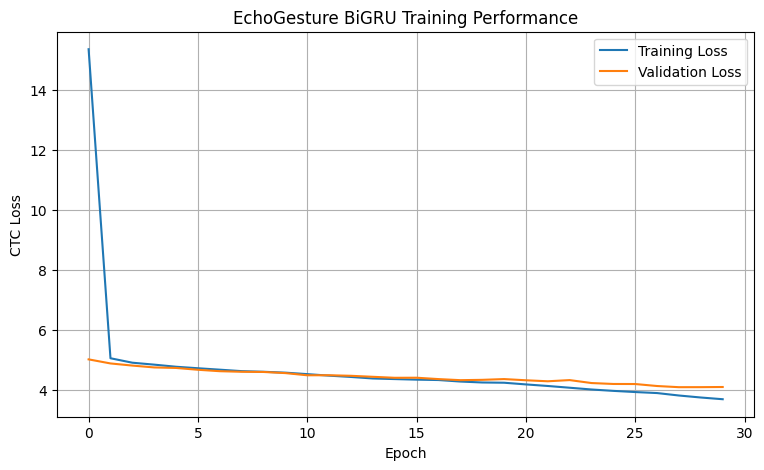

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.title("EchoGesture BiGRU Training Performance")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best checkpoint loaded!
Best epoch: 28
Best validation loss: 4.105615922849473


In [ ]:
idx_to_gloss = {
    int(index): token
    for token, index in vocab.items()
}

def ctc_decode(log_probs):

    predictions = torch.argmax(
        log_probs,
        dim=-1
    )

    decoded_sequences = []

    for sequence in predictions:

        sequence = sequence.tolist()

        collapsed = []

        previous = None

        for token in sequence:

            if token != previous and token != 0:
                collapsed.append(token)

            previous = token

        decoded_sequences.append([
            idx_to_gloss[token]
            for token in collapsed
        ])

    return decoded_sequences

In [ ]:
for i in range(min(15, len(predictions))):

    print(f"\nExample {i+1}")

    print("Actual:   ", " ".join(actual_sequences[i]))

    print("Predicted:", " ".join(predictions[i]))

NameError: name 'predictions' is not defined

In [ ]:
model.eval()

predictions = []
actual_sequences = []

with torch.no_grad():

    for inputs, targets, input_lengths, target_lengths in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        decoded = ctc_decode(outputs)

        predictions.extend(decoded)

        offset = 0

        for length in target_lengths.tolist():

            target = targets[offset:offset + length].tolist()

            actual_sequences.append([
                idx_to_gloss[token]
                for token in target
            ])

            offset += length

print("Total test predictions:", len(predictions))
print("Total reference sequences:", len(actual_sequences))

Total test predictions: 74
Total reference sequences: 74


In [ ]:
for i in range(min(15, len(predictions))):

    print(f"\nExample {i+1}")
    print("Actual:   ", " ".join(actual_sequences[i]))
    print("Predicted:", " ".join(predictions[i]))


Example 1
Actual:    YOU FREE TODAY
Predicted: YOU

Example 2
Actual:    YOU HIDE SOMETHING
Predicted: YOU

Example 3
Actual:    YOU HIDE SOMETHING
Predicted: NAN

Example 4
Actual:    I HELP YOU
Predicted: I YOU

Example 5
Actual:    I HELP YOU
Predicted: I IT

Example 6
Actual:    I HELP YOU
Predicted: YOU

Example 7
Actual:    YOU REPEAT PLEASE
Predicted: I YOU

Example 8
Actual:    YOU REPEAT PLEASE
Predicted: YOU

Example 9
Actual:    YOU REPEAT PLEASE
Predicted: YOU

Example 10
Actual:    DONOT HURT ME
Predicted: IT

Example 11
Actual:    DO NOT MAKE ME ANGRY
Predicted: I YOU

Example 12
Actual:    DO NOT TAKE IT HEART
Predicted: I YOU

Example 13
Actual:    DO NOT WORRY
Predicted: I YOU

Example 14
Actual:    DO YOU NEED SOMETHING
Predicted: YOU

Example 15
Actual:    DO YOU NEED SOMETHING
Predicted: NAN


In [ ]:
print("NAN in vocabulary:", "NAN" in vocab)

print("\nVocabulary size:", len(vocab))

print("\nSpecial or suspicious tokens:")
print([token for token in vocab if token in ["NAN", "NONE", "NULL", ""]])

NAN in vocabulary: True

Vocabulary size: 168

Special or suspicious tokens:
['NAN']


In [ ]:
metadata = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/training_metadata.csv"
)

print("Missing glosses:", metadata["gloss"].isna().sum())

display(
    metadata[metadata["gloss"].isna()]
)

Missing glosses: 5


,filename,sentence,gloss
437,sample_00437.npy,which collegeschool are you from,NaN
438,sample_00438.npy,which collegeschool are you from,NaN
439,sample_00439.npy,which collegeschool are you from,NaN
440,sample_00440.npy,which collegeschool are you from,NaN
441,sample_00441.npy,which collegeschool are you from,NaN


In [ ]:
for i, sequence in enumerate(gloss_sequences):

    if "NAN" in sequence:
        print("\nIndex:", i)
        print("Filename:", metadata.iloc[i]["filename"])
        print("Sentence:", metadata.iloc[i]["sentence"])
        print("Gloss:", metadata.iloc[i]["gloss"])


Index: 437
Filename: sample_00437.npy
Sentence: which collegeschool are you from
Gloss: nan

Index: 438
Filename: sample_00438.npy
Sentence: which collegeschool are you from
Gloss: nan

Index: 439
Filename: sample_00439.npy
Sentence: which collegeschool are you from
Gloss: nan

Index: 440
Filename: sample_00440.npy
Sentence: which collegeschool are you from
Gloss: nan

Index: 441
Filename: sample_00441.npy
Sentence: which collegeschool are you from
Gloss: nan


In [ ]:
from collections import Counter

prediction_counts = Counter(
    token
    for sequence in predictions
    for token in sequence
)

print("Most predicted glosses:")
for token, count in prediction_counts.most_common(20):
    print(token, count)

print("\nNumber of empty predictions:",
      sum(len(p) == 0 for p in predictions))

Most predicted glosses:
YOU 58
I 30
NAN 9
IT 7
XXXXXXXX 1
ME 1

Number of empty predictions: 0


In [ ]:
total_errors = 0
total_words = 0

for actual, predicted in zip(actual_sequences, predictions):
    total_errors += edit_distance(actual, predicted)
    total_words += len(actual)

wer = total_errors / total_words

print("Word Error Rate:", round(wer, 4))
print("WER percentage:", round(wer * 100, 2), "%")

NameError: name 'edit_distance' is not defined

In [ ]:
import os

search_dir = "/content/ISL-CSLTR"

for root, dirs, files in os.walk(search_dir):
    for file in files:
        if file.endswith((".xlsx", ".csv")):
            print(os.path.join(root, file))

In [ ]:
import pandas as pd
import glob

files = glob.glob(
    "/content/ISL-CSLTR/**/*.xlsx",
    recursive=True
)

for file in files:
    print("\nFILE:", file)

    try:
        excel = pd.ExcelFile(file)
        print("Sheets:", excel.sheet_names)

        for sheet in excel.sheet_names:
            df = pd.read_excel(file, sheet_name=sheet)

            print("\nSheet:", sheet)
            print("Columns:", df.columns.tolist())

            display(df.head(3))

    except Exception as e:
        print("Error:", e)

In [ ]:
def edit_distance(reference, hypothesis):

    dp = [
        [0] * (len(hypothesis) + 1)
        for _ in range(len(reference) + 1)
    ]

    for i in range(len(reference) + 1):
        dp[i][0] = i

    for j in range(len(hypothesis) + 1):
        dp[0][j] = j

    for i in range(1, len(reference) + 1):
        for j in range(1, len(hypothesis) + 1):

            cost = 0 if reference[i-1] == hypothesis[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]

In [ ]:
total_errors = 0
total_words = 0

for actual, predicted in zip(actual_sequences, predictions):

    total_errors += edit_distance(actual, predicted)
    total_words += len(actual)

wer = total_errors / total_words if total_words else 0

print("Total reference words:", total_words)
print("Total word errors:", total_errors)
print("WER:", round(wer, 4))
print("WER percentage:", round(wer * 100, 2), "%")

Total reference words: 267
Total word errors: 231
WER: 0.8652
WER percentage: 86.52 %


In [ ]:
import pandas as pd
import numpy as np

metadata = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/training_metadata.csv"
)

print("Total recordings:", len(metadata))
print("Missing glosses:", metadata["gloss"].isna().sum())

print("\nSuspicious gloss annotations:")

invalid = metadata[
    metadata["gloss"].isna() |
    metadata["gloss"].astype(str).str.upper().isin(
        ["NAN", "NONE", "NULL", "XXXXXXXX"]
    )
]

display(invalid)

Total recordings: 492
Missing glosses: 5

Suspicious gloss annotations:


,filename,sentence,gloss
437,sample_00437.npy,which collegeschool are you from,NaN
438,sample_00438.npy,which collegeschool are you from,NaN
439,sample_00439.npy,which collegeschool are you from,NaN
440,sample_00440.npy,which collegeschool are you from,NaN
441,sample_00441.npy,which collegeschool are you from,NaN


In [ ]:
from collections import Counter

token_counts = Counter(
    token
    for sequence in gloss_sequences
    for token in sequence
)

print("Total vocabulary:", len(token_counts))

print("\nLeast frequent tokens:")

for token, count in sorted(
    token_counts.items(),
    key=lambda x: x[1]
)[:30]:
    print(token, ":", count)

Total vocabulary: 168

Least frequent tokens:
NO : 1
HAVE : 1
PLAN : 1
CAREER : 1
DONT : 2
ABUSE : 4
BE : 4
STUBBORN : 4
WAY : 4
THINGS : 4
VERY : 4
HAPPY : 4
TRUTH : 4
WHERE : 4
ANYTHING, : 4
FREE : 5
HIDE : 5
BRING : 5
REPEAT : 5
COMB : 5
HAIR : 5
CONGRATULATIIONS : 5
TALK : 5
SLOWER : 5
FAVOUR : 5
HEART : 5
CAME : 5
ROOM : 5
SHE : 5
FRIEND : 5


In [ ]:
for name, indices in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:

    missing_count = metadata.iloc[indices]["gloss"].isna().sum()

    print(name, "missing annotations:", missing_count)

Training missing annotations: 4
Validation missing annotations: 1
Testing missing annotations: 0


In [ ]:
import os

search_dir = "/content/ISL-CSLTR"

for root, dirs, files in os.walk(search_dir):
    for file in files:
        if file.endswith((".xlsx", ".csv")):
            print(os.path.join(root, file))

In [ ]:
import pandas as pd
import glob

files = glob.glob(
    "/content/ISL-CSLTR/**/*.xlsx",
    recursive=True
)

for file in files:
    print("\nFILE:", file)

    excel = pd.ExcelFile(file)

    for sheet in excel.sheet_names:
        df = pd.read_excel(file, sheet_name=sheet)

        print("\nSHEET:", sheet)
        print("Columns:", df.columns.tolist())

        display(df.head())

In [ ]:
suspicious = metadata[
    metadata["gloss"].fillna("").astype(str)
    .str.contains("XXXXXXXX", case=False)
]

display(suspicious)

,filename,sentence,gloss
300,sample_00300.npy,my name is xxxxxxxx,MY NAME XXXXXXXX
301,sample_00301.npy,my name is xxxxxxxx,MY NAME XXXXXXXX
302,sample_00302.npy,my name is xxxxxxxx,MY NAME XXXXXXXX
303,sample_00303.npy,my name is xxxxxxxx,MY NAME XXXXXXXX
304,sample_00304.npy,my name is xxxxxxxx,MY NAME XXXXXXXX


In [ ]:
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

metadata = pd.read_csv(
    f"{PROJECT_DIR}/training_metadata.csv"
)

# Identify missing annotations
missing_mask = metadata["gloss"].isna()

# Identify anonymised name placeholders
placeholder_mask = (
    metadata["gloss"]
    .fillna("")
    .str.upper()
    .str.contains("XXXXXXXX")
)

# Keep only valid annotations
valid_mask = ~(missing_mask | placeholder_mask)

print("Original recordings:", len(metadata))
print("Missing annotations:", missing_mask.sum())
print("Anonymised recordings:", placeholder_mask.sum())
print("Usable recordings:", valid_mask.sum())

Original recordings: 492
Missing annotations: 5
Anonymised recordings: 5
Usable recordings: 482


In [ ]:
# Load original landmark sequences
X_original = np.load(f"{PROJECT_DIR}/X_landmarks.npy")

# Keep matching landmark sequences
X_clean = X_original[valid_mask.values]

# Keep matching metadata
metadata_clean = metadata.loc[valid_mask].reset_index(drop=True)

# Rebuild gloss sequences
gloss_sequences_clean = [
    str(gloss).strip().upper().split()
    for gloss in metadata_clean["gloss"]
]

print("Clean X shape:", X_clean.shape)
print("Clean metadata:", len(metadata_clean))
print("Clean gloss sequences:", len(gloss_sequences_clean))

Clean X shape: (482, 60, 258)
Clean metadata: 482
Clean gloss sequences: 482


In [ ]:
all_tokens = sorted({
    token
    for sequence in gloss_sequences_clean
    for token in sequence
})

vocab_clean = {
    token: index + 1
    for index, token in enumerate(all_tokens)
}

idx_to_gloss_clean = {
    index: token
    for token, index in vocab_clean.items()
}

print("Clean vocabulary size:", len(vocab_clean))
print(vocab_clean)

Clean vocabulary size: 165
{'(AGE)': 1, 'A': 2, 'ABOUT': 3, 'ABUSE': 4, 'AFRAID': 5, 'AGREE': 6, 'ALL': 7, 'AM': 8, 'ANGRY': 9, 'ANY': 10, 'ANYTHING,': 11, 'APPRECIATE': 12, 'BAD': 13, 'BE': 14, 'BEAUTIFUL': 15, 'BECOME': 16, 'BED': 17, 'BORED': 18, 'BRING': 19, 'BY': 20, 'CAME': 21, 'CARE': 22, 'CAREER': 23, 'CHAT': 24, 'CLASS': 25, 'COLD': 26, 'COMB': 27, 'COMING': 28, 'CONGRATULATIIONS': 29, 'CRY': 30, 'DARE': 31, 'DIFFERENCE': 32, 'DILEMMA': 33, 'DISAPPOINTED': 34, 'DO': 35, 'DONOT': 36, 'DONT': 37, 'ENJOYED': 38, 'FAVOUR': 39, 'FEELING': 40, 'FEVER': 41, 'FINE.': 42, 'FOOD': 43, 'FREE': 44, 'FRIEND': 45, 'FROM': 46, 'GLASS': 47, 'GO': 48, 'GOOD': 49, 'GOT': 50, 'GRATEFUL': 51, 'HAIR': 52, 'HAPPENED': 53, 'HAPPY': 54, 'HAVE': 55, 'HE': 56, 'HEAR': 57, 'HEART': 58, 'HELP': 59, 'HI': 60, 'HIDE': 61, 'HIM': 62, 'HOW': 63, 'HUNGRY': 64, 'HURT': 65, 'I': 66, 'IN': 67, 'INTO': 68, 'IT': 69, 'KIND': 70, 'KNOW': 71, 'LEAVE': 72, 'LET': 73, 'LIGHT': 74, 'LIKE': 75, 'LOT': 76, 'LOVE': 77, 'M

In [ ]:
import json

np.save(
    f"{PROJECT_DIR}/X_landmarks_clean.npy",
    X_clean
)

with open(f"{PROJECT_DIR}/gloss_sequences_clean.json", "w") as f:
    json.dump(gloss_sequences_clean, f, indent=2)

with open(f"{PROJECT_DIR}/vocab_clean.json", "w") as f:
    json.dump(vocab_clean, f, indent=2)

metadata_clean.to_csv(
    f"{PROJECT_DIR}/training_metadata_clean.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [ ]:
import numpy as np
import pandas as pd
import json
import os

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

X = np.load(f"{PROJECT_DIR}/X_landmarks_clean.npy")

with open(f"{PROJECT_DIR}/gloss_sequences_clean.json") as f:
    gloss_sequences = json.load(f)

with open(f"{PROJECT_DIR}/vocab_clean.json") as f:
    vocab = json.load(f)

metadata = pd.read_csv(
    f"{PROJECT_DIR}/training_metadata_clean.csv"
)

print("Landmark data:", X.shape)
print("Gloss sequences:", len(gloss_sequences))
print("Vocabulary size:", len(vocab))
print("Metadata:", metadata.shape)

Landmark data: (482, 60, 258)
Gloss sequences: 482
Vocabulary size: 165
Metadata: (482, 3)


In [ ]:
y = [
    [vocab[token] for token in sequence]
    for sequence in gloss_sequences
]

idx_to_gloss = {
    int(index): token
    for token, index in vocab.items()
}

print("Vocabulary size:", len(vocab))
print("Number of encoded sequences:", len(y))

print("\nExample:")
print("Gloss:", gloss_sequences[0])
print("Encoded:", y[0])

Vocabulary size: 165
Number of encoded sequences: 482

Example:
Gloss: ['YOU', 'FREE', 'TODAY']
Encoded: [163, 44, 142]


In [ ]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(X))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Training: 337
Validation: 72
Testing: 73


In [ ]:
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

missing_tokens = set(vocab.keys()) - train_tokens

print("Total vocabulary:", len(vocab))
print("Tokens in training:", len(train_tokens))
print("Missing tokens:", len(missing_tokens))
print(sorted(missing_tokens))

Total vocabulary: 165
Tokens in training: 162
Missing tokens: 3
['CAREER', 'HAVE', 'PLAN']


In [ ]:
move_indices = set()

for token in missing_tokens:
    candidates = [
        i for i, sequence in enumerate(gloss_sequences)
        if token in sequence
    ]

    # Prefer validation/test recordings
    candidates = [
        i for i in candidates
        if i in val_idx or i in test_idx
    ]

    if candidates:
        move_indices.add(candidates[0])

move_indices = sorted(move_indices)

train_idx = np.array(sorted(set(train_idx) | set(move_indices)))

val_idx = np.array([
    i for i in val_idx if i not in move_indices
])

test_idx = np.array([
    i for i in test_idx if i not in move_indices
])

print("Updated training:", len(train_idx))
print("Updated validation:", len(val_idx))
print("Updated testing:", len(test_idx))

Updated training: 338
Updated validation: 71
Updated testing: 73


In [ ]:
train_tokens = {
    token
    for i in train_idx
    for token in gloss_sequences[i]
}

print("Missing vocabulary tokens:",
      sorted(set(vocab.keys()) - train_tokens))

all_indices = np.concatenate([train_idx, val_idx, test_idx])

print("Total samples:", len(all_indices))
print("Unique samples:", len(np.unique(all_indices)))

assert len(all_indices) == 482
assert len(np.unique(all_indices)) == 482
assert set(vocab.keys()).issubset(train_tokens)

print("Dataset split verification passed!")

Missing vocabulary tokens: []
Total samples: 482
Unique samples: 482
Dataset split verification passed!


In [ ]:
np.savez(
    f"{PROJECT_DIR}/dataset_splits_clean.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Clean dataset splits saved!")

Clean dataset splits saved!


In [ ]:
def minimum_ctc_frames(sequence):
    repeated = sum(
        sequence[i] == sequence[i-1]
        for i in range(1, len(sequence))
    )
    return len(sequence) + repeated

problems = []

for i, sequence in enumerate(y):
    required = minimum_ctc_frames(sequence)

    if required > 60:
        problems.append((i, required, gloss_sequences[i]))

print("CTC incompatible sequences:", len(problems))

if problems:
    print(problems)
else:
    print("All sequences are CTC compatible!")

CTC incompatible sequences: 0
All sequences are CTC compatible!


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class EchoGestureDataset(Dataset):

    def __init__(self, X, sequences, indices):
        self.X = X
        self.sequences = sequences
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        actual_idx = self.indices[idx]

        landmarks = torch.tensor(
            self.X[actual_idx],
            dtype=torch.float32
        )

        gloss = torch.tensor(
            self.sequences[actual_idx],
            dtype=torch.long
        )

        return landmarks, gloss


def collate_fn(batch):

    inputs = torch.stack([item[0] for item in batch])
    targets_list = [item[1] for item in batch]

    target_lengths = torch.tensor(
        [len(t) for t in targets_list],
        dtype=torch.long
    )

    targets = torch.cat(targets_list)

    input_lengths = torch.full(
        (len(batch),),
        60,
        dtype=torch.long
    )

    return inputs, targets, input_lengths, target_lengths


train_dataset = EchoGestureDataset(X, y, train_idx)
val_dataset = EchoGestureDataset(X, y, val_idx)
test_dataset = EchoGestureDataset(X, y, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 22
Validation batches: 5
Testing batches: 5


In [ ]:
import torch.nn as nn

class EchoGestureBiGRU(nn.Module):

    def __init__(
        self,
        input_size=258,
        projection_size=128,
        hidden_size=128,
        num_layers=2,
        num_classes=166,
        dropout=0.3
    ):
        super().__init__()

        self.projection = nn.Linear(
            input_size,
            projection_size
        )

        self.gru = nn.GRU(
            input_size=projection_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        x = self.projection(x)
        x, _ = self.gru(x)
        x = self.dropout(x)
        x = self.classifier(x)

        return x.log_softmax(dim=-1)

In [ ]:
device = torch.device("cpu")

model = EchoGestureBiGRU(
    input_size=258,
    projection_size=128,
    hidden_size=128,
    num_layers=2,
    num_classes=len(vocab) + 1
).to(device)

print("Model initialized!")
print("Device:", device)
print("Output classes:", len(vocab) + 1)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

Model initialized!
Device: cpu
Output classes: 166
Parameters: 570406


In [ ]:
import os

criterion = nn.CTCLoss(
    blank=0,
    reduction="mean",
    zero_infinity=False
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

MODEL_DIR = "/content/drive/MyDrive/EchoGesture/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "echogesture_bigru_clean_best.pth"
)

print("Training configuration ready!")

Training configuration ready!


In [ ]:
EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader
    )

    val_loss = validate_one_epoch(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train: {train_loss:.4f} "
        f"| Validation: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "vocab": vocab,
            "input_size": 258,
            "num_classes": len(vocab) + 1
        }, BEST_MODEL_PATH)

        print("  Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nCLEAN MODEL TRAINING FINISHED!")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_MODEL_PATH)

TypeError: train_one_epoch() missing 2 required positional arguments: 'optimizer' and 'criterion'

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0
    total_samples = 0

    for inputs, targets, input_lengths, target_lengths in loader:

        inputs = inputs.to(device)
        optimizer.zero_grad()

        outputs = model(inputs).transpose(0, 1)

        loss = criterion(
            outputs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            raise ValueError("Invalid training loss!")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        total_samples += inputs.size(0)

    return total_loss / total_samples

In [ ]:
def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.no_grad():

        for inputs, targets, input_lengths, target_lengths in loader:

            inputs = inputs.to(device)

            outputs = model(inputs).transpose(0, 1)

            loss = criterion(
                outputs,
                targets,
                input_lengths,
                target_lengths
            )

            if not torch.isfinite(loss):
                raise ValueError("Invalid validation loss!")

            total_loss += loss.item() * inputs.size(0)
            total_samples += inputs.size(0)

    return total_loss / total_samples

In [ ]:
EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_loss = validate_one_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train: {train_loss:.4f} "
        f"| Validation: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "vocab": vocab
        }, BEST_MODEL_PATH)

        print("Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nTraining finished!")
print("Best validation loss:", best_val_loss)

Epoch [1/30] | Train: 3.0927 | Validation: 4.0232
Best model saved!
Epoch [2/30] | Train: 3.0707 | Validation: 4.0151
Best model saved!
Epoch [3/30] | Train: 3.0679 | Validation: 4.0172
Epoch [4/30] | Train: 3.0588 | Validation: 4.0130
Best model saved!
Epoch [5/30] | Train: 3.0364 | Validation: 4.0015
Best model saved!
Epoch [6/30] | Train: 3.0213 | Validation: 3.9946
Best model saved!
Epoch [7/30] | Train: 3.0004 | Validation: 4.0031
Epoch [8/30] | Train: 2.9879 | Validation: 4.0084
Epoch [9/30] | Train: 2.9779 | Validation: 3.9895
Best model saved!
Epoch [10/30] | Train: 2.9699 | Validation: 3.9900
Epoch [11/30] | Train: 2.9427 | Validation: 3.9969
Epoch [12/30] | Train: 2.9425 | Validation: 3.9898
Epoch [13/30] | Train: 2.9238 | Validation: 3.9893
Best model saved!
Epoch [14/30] | Train: 2.8964 | Validation: 3.9862
Best model saved!
Epoch [15/30] | Train: 2.8905 | Validation: 4.0012
Epoch [16/30] | Train: 2.8825 | Validation: 3.9803
Best model saved!
Epoch [17/30] | Train: 2.8744 |

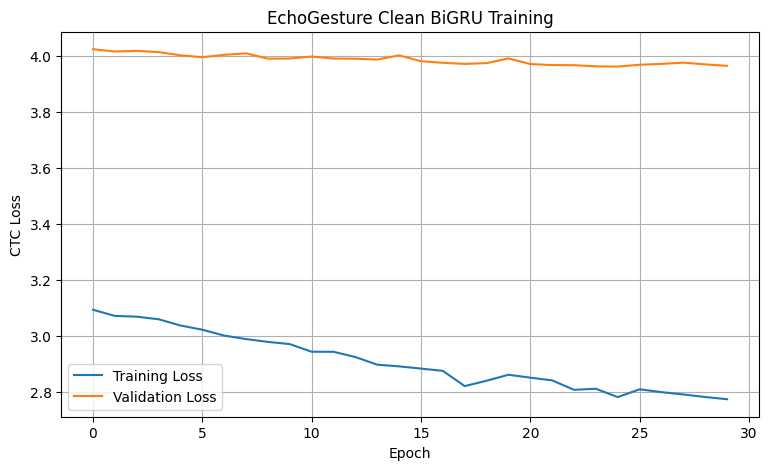

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.title("EchoGesture Clean BiGRU Training")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Best epoch: 25
Best validation loss: 3.961135743369519


In [ ]:
idx_to_gloss = {
    int(index): token
    for token, index in vocab.items()
}

def ctc_decode(log_probs):

    predictions = torch.argmax(log_probs, dim=-1)

    decoded_sequences = []

    for sequence in predictions:

        sequence = sequence.tolist()

        collapsed = []
        previous = None

        for token in sequence:

            if token != previous and token != 0:
                collapsed.append(token)

            previous = token

        decoded_sequences.append([
            idx_to_gloss[token]
            for token in collapsed
        ])

    return decoded_sequences

In [ ]:
predictions = []
actual_sequences = []

model.eval()

with torch.no_grad():

    for inputs, targets, input_lengths, target_lengths in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        decoded = ctc_decode(outputs)

        predictions.extend(decoded)

        offset = 0

        for length in target_lengths.tolist():

            target = targets[offset:offset + length].tolist()

            actual_sequences.append([
                idx_to_gloss[token]
                for token in target
            ])

            offset += length

print("Predictions:", len(predictions))
print("References:", len(actual_sequences))

Predictions: 73
References: 73


In [ ]:
for i in range(min(20, len(predictions))):

    print(f"\nExample {i+1}")
    print("Actual:   ", " ".join(actual_sequences[i]))
    print("Predicted:", " ".join(predictions[i]))


Example 1
Actual:    YOU DO IT
Predicted: I YOU

Example 2
Actual:    HELP ME
Predicted: I YOU

Example 3
Actual:    YOU WELCOME
Predicted: I YOU

Example 4
Actual:    HE CAME TRAIN
Predicted: YOU

Example 5
Actual:    DONOT HURT ME
Predicted: YOU

Example 6
Actual:    HE COMING TODAY
Predicted: I TO ANGRY

Example 7
Actual:    YOU REPEAT PLEASE
Predicted: I YOU

Example 8
Actual:    I REALLY APPRECIATE IT
Predicted: I ABOUT IT

Example 9
Actual:    WHEN TRAIN LEAVE
Predicted: I TO YOURSELF

Example 10
Actual:    I DO NOT MEAN IT
Predicted: I OF IT

Example 11
Actual:    YOU DO ANYTHING, I DO NOT CARE
Predicted: I BE STUBBORN

Example 12
Actual:    WHERE YOU FROM
Predicted: I YOU

Example 13
Actual:    WHAT DO YOU THINK
Predicted: I BAD

Example 14
Actual:    I FINE. THANK YOU SIR
Predicted: I FREE AGREE

Example 15
Actual:    WHAT DO YOU THINK
Predicted: YOU CRY

Example 16
Actual:    HE SHE MY FRIEND
Predicted: I YOU

Example 17
Actual:    WHEN TRAIN LEAVE
Predicted: YOU YOU

Exampl

In [ ]:
def edit_distance(reference, hypothesis):

    dp = [
        [0] * (len(hypothesis) + 1)
        for _ in range(len(reference) + 1)
    ]

    for i in range(len(reference) + 1):
        dp[i][0] = i

    for j in range(len(hypothesis) + 1):
        dp[0][j] = j

    for i in range(1, len(reference) + 1):
        for j in range(1, len(hypothesis) + 1):

            cost = (
                0 if reference[i-1] == hypothesis[j-1]
                else 1
            )

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]


total_errors = 0
total_words = 0

for actual, predicted in zip(actual_sequences, predictions):

    total_errors += edit_distance(actual, predicted)
    total_words += len(actual)

wer = total_errors / total_words

print("Total reference words:", total_words)
print("Total word errors:", total_errors)
print("WER:", round(wer, 4))
print("WER percentage:", round(wer * 100, 2), "%")

Total reference words: 245
Total word errors: 209
WER: 0.8531
WER percentage: 85.31 %


In [ ]:
from collections import Counter

prediction_counts = Counter(
    token
    for sequence in predictions
    for token in sequence
)

print("PREDICTED TOKEN DISTRIBUTION")
print("============================")

for token, count in prediction_counts.most_common(25):
    print(f"{token:20s} {count}")

print("\nUnique predicted tokens:", len(prediction_counts))

print("Empty predictions:",
      sum(len(p) == 0 for p in predictions))

PREDICTED TOKEN DISTRIBUTION
I                    60
YOU                  51
IT                   8
TO                   6
ANGRY                5
ME                   5
BAD                  4
TAKE                 3
BORED                3
THE                  3
YOURSELF             2
OF                   2
BE                   2
CRY                  2
PROMISE              2
ABOUT                1
STUBBORN             1
FREE                 1
AGREE                1
MEET                 1
TODAY                1
TIRED                1
REALLY               1
KIND                 1
A                    1

Unique predicted tokens: 27
Empty predictions: 0


In [ ]:
blank_frames = 0
total_frames = 0

model.eval()

with torch.no_grad():

    for inputs, targets, input_lengths, target_lengths in test_loader:

        outputs = model(inputs.to(device))

        frame_predictions = outputs.argmax(dim=-1)

        blank_frames += (frame_predictions == 0).sum().item()
        total_frames += frame_predictions.numel()

print("Total frames:", total_frames)
print("Blank frames:", blank_frames)

print(
    "Blank prediction percentage:",
    round(blank_frames / total_frames * 100, 2),
    "%"
)

Total frames: 4380
Blank frames: 4207
Blank prediction percentage: 96.05 %


In [ ]:
print("DATASET QUALITY AUDIT")
print("=====================")

print("Shape:", X.shape)
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("Overall zero percentage:",
      round(np.mean(X == 0) * 100, 2), "%")

print("Mean:", np.mean(X))
print("Standard deviation:", np.std(X))

# Check individual recordings
zero_percentages = np.mean(X == 0, axis=(1, 2)) * 100

print("\nHighest zero percentages:")
print(np.sort(zero_percentages)[-10:])

DATASET QUALITY AUDIT
Shape: (482, 60, 258)
NaN values: 0
Infinite values: 0
Overall zero percentage: 27.53 %
Mean: 0.26616144
Standard deviation: 1.3840383

Highest zero percentages:
[40.29069767 40.69767442 40.69767442 41.51162791 41.91860465 41.91860465
 42.55813953 43.54651163 43.95348837 47.20930233]


In [ ]:
import numpy as np
import pandas as pd

# Load cleaned dataset
X = np.load(
    "/content/drive/MyDrive/EchoGesture/X_landmarks_clean.npy"
)

print("Dataset shape:", X.shape)

# Check completely zero frames
zero_frames = np.all(X == 0, axis=2)

# Count zero frames in every recording
zero_frame_counts = zero_frames.sum(axis=1)

# Calculate trailing zero frames
trailing_zeros = []

for sample in zero_frames:
    count = 0

    for value in sample[::-1]:
        if value:
            break
        count += 1

    trailing_zeros.append(count)

print("\nLANDMARK QUALITY REPORT")
print("-----------------------")

print("Total recordings:", len(X))

print(
    "Completely zero frames:",
    zero_frames.sum()
)

print(
    "Percentage of completely zero frames:",
    round(zero_frames.mean() * 100, 2),
    "%"
)

print(
    "Recordings containing zero frames:",
    np.sum(zero_frame_counts > 0)
)

print(
    "Recordings with trailing zero frames:",
    np.sum(np.array(trailing_zeros) > 0)
)

print(
    "Average trailing zero frames:",
    round(np.mean(trailing_zeros), 2)
)

print(
    "Maximum trailing zero frames:",
    max(trailing_zeros)
)

Dataset shape: (482, 60, 258)

LANDMARK QUALITY REPORT
-----------------------
Total recordings: 482
Completely zero frames: 17
Percentage of completely zero frames: 0.06 %
Recordings containing zero frames: 3
Recordings with trailing zero frames: 479
Average trailing zero frames: 59.63
Maximum trailing zero frames: 60


In [ ]:
report = pd.DataFrame({
    "sample": np.arange(len(X)),
    "zero_frames": zero_frame_counts,
    "trailing_zero_frames": trailing_zeros
})

display(
    report.sort_values(
        "zero_frames",
        ascending=False
    ).head(20)
)

,sample,zero_frames,trailing_zero_frames
463,463,9,0
35,35,6,0
455,455,2,0
318,318,0,60
319,319,0,60
320,320,0,60
321,321,0,60
322,322,0,60
323,323,0,60
317,317,0,60


In [ ]:
import numpy as np
import pandas as pd

X_clean = np.load(
    "/content/drive/MyDrive/EchoGesture/X_landmarks_clean.npy"
)

# Identify completely zero frames
frame_is_zero = np.all(X_clean == 0, axis=2)

# Number of zero frames per recording
zero_count_per_video = frame_is_zero.sum(axis=1)

# Calculate trailing zero frames
trailing_count_per_video = []

for video_frames in frame_is_zero:

    count = 0

    for frame_is_empty in video_frames[::-1]:

        if frame_is_empty:
            count += 1
        else:
            break

    trailing_count_per_video.append(count)

trailing_count_per_video = np.array(trailing_count_per_video)

print("DATASET SHAPE:", X_clean.shape)

print("\nZERO FRAME STATISTICS")
print("Total zero frames:", frame_is_zero.sum())
print("Videos containing zero frames:",
      np.sum(zero_count_per_video > 0))
print("Videos containing no zero frames:",
      np.sum(zero_count_per_video == 0))

print("\nTRAILING ZERO STATISTICS")
print("Videos with trailing zeros:",
      np.sum(trailing_count_per_video > 0))
print("Average trailing zeros:",
      trailing_count_per_video.mean())
print("Maximum trailing zeros:",
      trailing_count_per_video.max())

print("\nSANITY CHECK")
print(
    "Total zero frames matches sum:",
    frame_is_zero.sum() == zero_count_per_video.sum()
)

DATASET SHAPE: (482, 60, 258)

ZERO FRAME STATISTICS
Total zero frames: 17
Videos containing zero frames: 3
Videos containing no zero frames: 479

TRAILING ZERO STATISTICS
Videos with trailing zeros: 3
Average trailing zeros: 0.035269709543568464
Maximum trailing zeros: 9

SANITY CHECK
Total zero frames matches sum: True


In [ ]:
report = pd.DataFrame({
    "sample_index": np.arange(len(X_clean)),
    "zero_frames": zero_count_per_video,
    "trailing_zero_frames": trailing_count_per_video
})

display(
    report[
        (report["zero_frames"] > 0) |
        (report["trailing_zero_frames"] > 0)
    ].sort_values(
        "zero_frames",
        ascending=False
    ).head(30)
)

,sample_index,zero_frames,trailing_zero_frames
463,463,9,9
35,35,6,6
455,455,2,2


In [ ]:
pose_features = X_clean[:, :, :132]
left_features = X_clean[:, :, 132:195]
right_features = X_clean[:, :, 195:258]

print("POSE zero percentage:",
      np.mean(pose_features == 0) * 100)

print("LEFT HAND zero percentage:",
      np.mean(left_features == 0) * 100)

print("RIGHT HAND zero percentage:",
      np.mean(right_features == 0) * 100)

POSE zero percentage: 0.058782849239280774
LEFT HAND zero percentage: 68.85546334716459
RIGHT HAND zero percentage: 43.77593360995851


In [ ]:
import numpy as np
import pandas as pd

X = np.load(
    "/content/drive/MyDrive/EchoGesture/X_landmarks_clean.npy"
)

# Extract landmark groups
pose = X[:, :, :132]
left_hand = X[:, :, 132:195]
right_hand = X[:, :, 195:258]

# A hand is considered missing in a frame
# only when ALL its coordinates are zero.
left_missing = np.all(left_hand == 0, axis=2)
right_missing = np.all(right_hand == 0, axis=2)

# Count missing frames per recording
left_missing_count = left_missing.sum(axis=1)
right_missing_count = right_missing.sum(axis=1)

report = pd.DataFrame({
    "sample_index": np.arange(len(X)),
    "left_missing_frames": left_missing_count,
    "right_missing_frames": right_missing_count,
    "both_missing_frames": (left_missing & right_missing).sum(axis=1)
})

print("LEFT HAND")
print("Average missing frames:", left_missing_count.mean())
print("Videos with left hand always missing:",
      np.sum(left_missing_count == 60))

print("\nRIGHT HAND")
print("Average missing frames:", right_missing_count.mean())
print("Videos with right hand always missing:",
      np.sum(right_missing_count == 60))

print("\nBOTH HANDS")
print("Frames where both hands are missing:",
      np.sum(left_missing & right_missing))

print("\nRECORDINGS WITH MOST MISSING HAND FRAMES")

display(
    report.sort_values(
        "both_missing_frames",
        ascending=False
    ).head(20)
)

LEFT HAND
Average missing frames: 41.31327800829875
Videos with left hand always missing: 57

RIGHT HAND
Average missing frames: 26.265560165975103
Videos with right hand always missing: 0

BOTH HANDS
Frames where both hands are missing: 9308

RECORDINGS WITH MOST MISSING HAND FRAMES


,sample_index,left_missing_frames,right_missing_frames,both_missing_frames
432,432,60,56,56
93,93,55,52,49
31,31,60,48,48
420,420,58,45,43
418,418,59,44,43
87,87,60,42,42
34,34,57,43,40
115,115,55,43,40
264,264,60,40,40
349,349,49,42,39


In [ ]:
import os
import pandas as pd

metadata_path = (
    "/content/drive/MyDrive/EchoGesture/"
    "training_metadata_clean.csv"
)

metadata = pd.read_csv(metadata_path)

print("COLUMNS:")
print(metadata.columns.tolist())

print("\nSAMPLE RECORDINGS:")

display(metadata.iloc[[432, 93, 31, 420, 418, 87, 34, 115, 264, 349]])

COLUMNS:
['filename', 'sentence', 'gloss']

SAMPLE RECORDINGS:


,filename,sentence,gloss
432,sample_00442.npy,who are you,WHO YOU
93,sample_00093.npy,he came by train,HE CAME TRAIN
31,sample_00031.npy,congratulations,CONGRATULATIIONS
420,sample_00425.npy,what you want,WHAT YOU WANT
418,sample_00423.npy,what you want,WHAT YOU WANT
87,sample_00087.npy,had your food,YOUR FOOD
34,sample_00034.npy,congratulations,CONGRATULATIIONS
115,sample_00115.npy,help me,HELP ME
264,sample_00264.npy,i need water,I NEED WATER
349,sample_00354.npy,thank you so much,THANK YOU SO MUCH


In [ ]:
import os

search_stems = [
    "sample_00442",
    "sample_00093",
    "sample_00031",
    "sample_00425",
    "sample_00423",
    "sample_00087",
    "sample_00034",
    "sample_00115",
    "sample_00264",
    "sample_00354"
]

video_extensions = (".mp4", ".avi", ".mov", ".mkv")

search_root = "/content/ISL-CSLTR"

for stem in search_stems:
    matches = []

    for root, dirs, files in os.walk(search_root):
        for filename in files:
            if filename.startswith(stem) and filename.lower().endswith(video_extensions):
                matches.append(os.path.join(root, filename))

    print(f"\n{stem}:")
    if matches:
        for path in matches:
            print(path)
    else:
        print("No matching video found")


sample_00442:
No matching video found

sample_00093:
No matching video found

sample_00031:
No matching video found

sample_00425:
No matching video found

sample_00423:
No matching video found

sample_00087:
No matching video found

sample_00034:
No matching video found

sample_00115:
No matching video found

sample_00264:
No matching video found

sample_00354:
No matching video found


In [ ]:
import os
from collections import Counter

search_locations = [
    "/content/ISL-CSLTR",
    "/content/drive/MyDrive/EchoGesture",
    "/content"
]

video_extensions = (".mp4", ".avi", ".mov", ".mkv", ".webm")

for location in search_locations:

    print(f"\n{'='*60}")
    print("SEARCHING:", location)

    if not os.path.exists(location):
        print("Directory does not exist")
        continue

    video_files = []

    for root, dirs, files in os.walk(location):

        for filename in files:

            if filename.lower().endswith(video_extensions):

                video_files.append(
                    os.path.join(root, filename)
                )

    print("Total videos found:", len(video_files))

    print("\nFirst 15 videos:")

    for path in video_files[:15]:
        print(path)

    print("\nTop folders containing videos:")

    folder_counts = Counter(
        os.path.dirname(path)
        for path in video_files
    )

    for folder, count in folder_counts.most_common(10):
        print(count, "videos ->", folder)


SEARCHING: /content/ISL-CSLTR
Directory does not exist

SEARCHING: /content/drive/MyDrive/EchoGesture
Total videos found: 0

First 15 videos:

Top folders containing videos:

SEARCHING: /content
Total videos found: 2

First 15 videos:
/content/drive/MyDrive/WIN_20251113_21_17_50_Pro.mp4
/content/drive/MyDrive/WIN_20260330_23_17_16_Pro.mp4

Top folders containing videos:
2 videos -> /content/drive/MyDrive


In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

print("Dataset downloaded to:", dataset_path)

KeyboardInterrupt: 

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'isl-csltr-indian-sign-language-dataset' dataset.
Dataset downloaded to: /kaggle/input/isl-csltr-indian-sign-language-dataset


In [ ]:
import os

dataset_path = "/kaggle/input/isl-csltr-indian-sign-language-dataset"

print("Dataset exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 3:
        print(
            "  " * level,
            os.path.basename(root),
            "| Files:", len(files)
        )

    if level >= 3:
        dirs[:] = []

Dataset exists: True
 isl-csltr-indian-sign-language-dataset | Files: 0
   ISL_CSLRT_Corpus | Files: 0
     ISL_CSLRT_Corpus | Files: 1
       Videos_Sentence_Level | Files: 0
       corpus_csv_files | Files: 4
       Frames_Word_Level | Files: 0
       Frames_Sentence_Level | Files: 0


In [ ]:
video_extensions = (".mp4", ".avi", ".mov", ".mkv", ".webm")

video_files = []

for root, dirs, files in os.walk(dataset_path):
    for filename in files:
        if filename.lower().endswith(video_extensions):
            video_files.append(os.path.join(root, filename))

print("Total original videos:", len(video_files))

for path in video_files[:20]:
    print(path)

Total original videos: 687
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting (3).MP4
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/i am sitting in the class (2).mp4
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/i am sitting in the class.mp4
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting (5).MP4
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting (2).MP4
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting.MP4
/kaggle/input/isl-csltr-indian-sign-lan

In [ ]:
import os
import pandas as pd

csv_folder = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files"
)

for filename in os.listdir(csv_folder):
    if filename.lower().endswith(".csv"):
        path = os.path.join(csv_folder, filename)

        print("\n" + "=" * 70)
        print("FILE:", filename)

        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(5))


FILE: ISL Corpus sign glosses.csv
Shape: (101, 2)
Columns: ['Sentence', 'SIGN GLOSSES']


,Sentence,SIGN GLOSSES
0,are you free today,YOU FREE TODAY
1,are you hiding something,YOU HIDE SOMETHING
2,bring water for me,BRING WATER ME
3,can i help you,I HELP YOU
4,can you repeat that please,YOU REPEAT PLEASE


In [ ]:
import os

video_root = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/"
    "Videos_Sentence_Level"
)

sentences = [
    "who are you",
    "he came by train",
    "congratulations",
    "what you want",
    "had your food",
    "help me",
    "i need water",
    "thank you so much"
]

for sentence in sentences:
    print("\n" + "=" * 60)
    print("SENTENCE:", sentence)

    matches = [
        folder for folder in os.listdir(video_root)
        if folder.strip().lower() == sentence.lower()
    ]

    if not matches:
        print("Folder not found")
        continue

    folder_path = os.path.join(video_root, matches[0])

    videos = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
    ]

    print("Number of videos:", len(videos))

    for video in videos:
        print(video)


SENTENCE: who are you
Number of videos: 7
who are you (4).MP4
who are you (3).MP4
who are you (5).MP4
who are you (1).MP4
who are you (8).mp4
who are you (6).MP4
who are you (7).mp4

SENTENCE: he came by train
Number of videos: 7
train (5).MP4
he came by train.mp4
train.MP4
train (4).MP4
train (3).MP4
he came by train (2).mp4
train (2).MP4

SENTENCE: congratulations
Number of videos: 7
congratulations (7).MP4
congratulations.mp4
congratulations (4).MP4
congratulations (5).MP4
congratulations (3).MP4
congratulations (2).mp4
congratulations (6).MP4

SENTENCE: what you want
Number of videos: 7
what you want (6).MP4
what you want (4).MP4
what you want (1).MP4
what you want (5).MP4
what you want (3).MP4
what you want (7).mp4
what you want (8).mp4

SENTENCE: had your food
Number of videos: 7
food (4).MP4
food (5).MP4
food (2).MP4
had your food (2).mp4
food.MP4
had your food.mp4
food (3).MP4

SENTENCE: help me
Number of videos: 7
help me (7).mp4
help me (6).mp4
help me (1).MP4
help me (3).MP

In [ ]:
import pandas as pd
import os

drive_path = "/content/drive/MyDrive/EchoGesture"

files_to_check = [
    "labels.csv",
    "training_metadata_clean.csv"
]

for filename in files_to_check:
    path = os.path.join(drive_path, filename)

    print("\n" + "=" * 60)
    print("FILE:", filename)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(15))
        display(df.tail(10))
    else:
        print("File not found")


FILE: labels.csv
Shape: (492, 5)
Columns: ['filename', 'sentence', 'gloss', 'video_path', 'status']


,filename,sentence,gloss,video_path,status
0,sample_00000.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
1,sample_00001.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
2,sample_00002.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
3,sample_00003.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
4,sample_00004.npy,are you free today,YOU FREE TODAY,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
5,sample_00005.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
6,sample_00006.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
7,sample_00007.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
8,sample_00008.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
9,sample_00009.npy,are you hiding something,YOU HIDE SOMETHING,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success


,filename,sentence,gloss,video_path,status
482,sample_00482.npy,you can do it,YOU DO IT,/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
483,sample_00483.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
484,sample_00484.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
485,sample_00485.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
486,sample_00486.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
487,sample_00487.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
488,sample_00488.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
489,sample_00489.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
490,sample_00490.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success
491,sample_00491.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE",/content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_...,success



FILE: training_metadata_clean.csv
Shape: (482, 3)
Columns: ['filename', 'sentence', 'gloss']


,filename,sentence,gloss
0,sample_00000.npy,are you free today,YOU FREE TODAY
1,sample_00001.npy,are you free today,YOU FREE TODAY
2,sample_00002.npy,are you free today,YOU FREE TODAY
3,sample_00003.npy,are you free today,YOU FREE TODAY
4,sample_00004.npy,are you free today,YOU FREE TODAY
5,sample_00005.npy,are you hiding something,YOU HIDE SOMETHING
6,sample_00006.npy,are you hiding something,YOU HIDE SOMETHING
7,sample_00007.npy,are you hiding something,YOU HIDE SOMETHING
8,sample_00008.npy,are you hiding something,YOU HIDE SOMETHING
9,sample_00009.npy,are you hiding something,YOU HIDE SOMETHING


,filename,sentence,gloss
472,sample_00482.npy,you can do it,YOU DO IT
473,sample_00483.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE"
474,sample_00484.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE"
475,sample_00485.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE"
476,sample_00486.npy,"you do anything, i do not care","YOU DO ANYTHING, I DO NOT CARE"
477,sample_00487.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE"
478,sample_00488.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE"
479,sample_00489.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE"
480,sample_00490.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE"
481,sample_00491.npy,"you need a medicine, take this one","YOU NEED A MEDICINE, TAKE THIS ONE"


In [ ]:
import os

keypoint_dir = "/content/drive/MyDrive/EchoGesture/full_keypoints"

print("Directory exists:", os.path.exists(keypoint_dir))

if os.path.exists(keypoint_dir):
    files = sorted(os.listdir(keypoint_dir))

    print("Total files:", len(files))
    print("First 10:", files[:10])
    print("Last 10:", files[-10:])

Directory exists: True
Total files: 492
First 10: ['sample_00000.npy', 'sample_00001.npy', 'sample_00002.npy', 'sample_00003.npy', 'sample_00004.npy', 'sample_00005.npy', 'sample_00006.npy', 'sample_00007.npy', 'sample_00008.npy', 'sample_00009.npy']
Last 10: ['sample_00482.npy', 'sample_00483.npy', 'sample_00484.npy', 'sample_00485.npy', 'sample_00486.npy', 'sample_00487.npy', 'sample_00488.npy', 'sample_00489.npy', 'sample_00490.npy', 'sample_00491.npy']


In [ ]:
import pandas as pd
import os

labels_path = "/content/drive/MyDrive/EchoGesture/labels.csv"

labels = pd.read_csv(labels_path)

# Samples with problematic hand detection
problem_samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00423.npy",
    "sample_00087.npy",
    "sample_00034.npy",
    "sample_00115.npy",
    "sample_00264.npy",
    "sample_00354.npy"
]

# Current Kaggle dataset location
old_prefix = "/content/ISL-CSLTR/"
new_prefix = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/"
)

for sample in problem_samples:

    row = labels[labels["filename"] == sample]

    print("\n" + "=" * 65)

    if row.empty:
        print("Mapping not found:", sample)
        continue

    row = row.iloc[0]

    original_path = str(row["video_path"])
    current_path = original_path.replace(old_prefix, new_prefix)

    print("Landmark:", sample)
    print("Sentence:", row["sentence"])
    print("Gloss:", row["gloss"])
    print("Original path:", original_path)
    print("Current path:", current_path)
    print("VIDEO EXISTS:", os.path.exists(current_path))


Landmark: sample_00442.npy
Sentence: who are you
Gloss: WHO YOU
Original path: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/who are you/who are you (1).MP4
Current path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/who are you/who are you (1).MP4
VIDEO EXISTS: False

Landmark: sample_00093.npy
Sentence: he came by train
Gloss: HE CAME TRAIN
Original path: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/he came by train/train (5).MP4
Current path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/he came by train/train (5).MP4
VIDEO EXISTS: False

Landmark: sample_00031.npy
Sentence: congratulations
Gloss: CONGRATULATIIONS
Original path: /content/ISL-CSLTR/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/congratulations/congratulations (3).MP4
Current path: /kaggle/inp

In [ ]:
import pandas as pd
import os

labels = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/labels.csv"
)

dataset_root = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

old_root = (
    "/content/ISL-CSLTR/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

problem_samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00423.npy",
    "sample_00087.npy",
    "sample_00034.npy",
    "sample_00115.npy",
    "sample_00264.npy",
    "sample_00354.npy"
]

for sample in problem_samples:

    row = labels[labels["filename"] == sample].iloc[0]

    relative_path = os.path.relpath(
        row["video_path"],
        old_root
    )

    video_path = os.path.join(
        dataset_root,
        relative_path
    )

    print("\nSample:", sample)
    print("Sentence:", row["sentence"])
    print("Gloss:", row["gloss"])
    print("Video:", os.path.basename(video_path))
    print("EXISTS:", os.path.exists(video_path))
    print("Path:", video_path)


Sample: sample_00442.npy
Sentence: who are you
Gloss: WHO YOU
Video: who are you (1).MP4
EXISTS: True
Path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/who are you/who are you (1).MP4

Sample: sample_00093.npy
Sentence: he came by train
Gloss: HE CAME TRAIN
Video: train (5).MP4
EXISTS: True
Path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/he came by train/train (5).MP4

Sample: sample_00031.npy
Sentence: congratulations
Gloss: CONGRATULATIIONS
Video: congratulations (3).MP4
EXISTS: True
Path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/congratulations/congratulations (3).MP4

Sample: sample_00425.npy
Sentence: what you want
Gloss: WHAT YOU WANT
Video: what you want (4).MP4
EXISTS: True
Path: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence

In [ ]:
import cv2
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

labels = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/labels.csv"
)

dataset_root = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

old_root = (
    "/content/ISL-CSLTR/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00087.npy"
]

for sample in samples:

    row = labels[labels["filename"] == sample].iloc[0]

    relative_path = os.path.relpath(
        row["video_path"], old_root
    )

    video_path = os.path.join(
        dataset_root, relative_path
    )

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    frame_indices = np.linspace(
        0, total_frames - 1, 8, dtype=int
    )

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    fig.suptitle(
        f"{sample} | {row['sentence']} | {row['gloss']}",
        fontsize=14
    )

    for ax, frame_idx in zip(axes.flat, frame_indices):

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        ret, frame = cap.read()

        if ret:
            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )
            ax.imshow(frame)
            ax.set_title(f"Frame {frame_idx}")
        else:
            ax.set_title("Frame unavailable")

        ax.axis("off")

    cap.release()
    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import cv2
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

labels = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/labels.csv"
)

dataset_root = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

old_root = (
    "/content/ISL-CSLTR/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00087.npy"
]

for sample in samples:

    row = labels[labels["filename"] == sample].iloc[0]

    relative_path = os.path.relpath(
        row["video_path"], old_root
    )

    video_path = os.path.join(
        dataset_root, relative_path
    )

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    frame_indices = np.linspace(
        0, total_frames - 1, 8, dtype=int
    )

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    fig.suptitle(
        f"{sample} | {row['sentence']} | {row['gloss']}",
        fontsize=14
    )

    for ax, frame_idx in zip(axes.flat, frame_indices):

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        ret, frame = cap.read()

        if ret:
            frame = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )
            ax.imshow(frame)
            ax.set_title(f"Frame {frame_idx}")
        else:
            ax.set_title("Frame unavailable")

        ax.axis("off")

    cap.release()
    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

dataset_root = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

old_root = (
    "/content/ISL-CSLTR/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"
)

labels = pd.read_csv(
    "/content/drive/MyDrive/EchoGesture/labels.csv"
)

samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00087.npy"
]

for sample in samples:

    row = labels[labels["filename"] == sample].iloc[0]

    relative_path = os.path.relpath(
        row["video_path"], old_root
    )

    video_path = os.path.join(dataset_root, relative_path)

    keypoint_path = os.path.join(
        "/content/drive/MyDrive/EchoGesture/full_keypoints",
        sample
    )

    X = np.load(keypoint_path)

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Match the 60 evenly sampled frames
    frame_indices = np.linspace(
        0, total_frames - 1, 60, dtype=int
    )

    selected = [15, 25, 35, 45]

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    fig.suptitle(
        f"{sample} | {row['gloss']}",
        fontsize=14
    )

    for ax, idx in zip(axes, selected):

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_indices[idx])
        )

        ret, frame = cap.read()

        if not ret:
            continue

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        h, w = frame.shape[:2]

        ax.imshow(frame)

        # Left hand landmarks: features 132–194
        left = X[idx, 132:195].reshape(21, 3)

        # Right hand landmarks: features 195–257
        right = X[idx, 195:258].reshape(21, 3)

        if not np.all(left == 0):
            ax.scatter(
                left[:, 0] * w,
                left[:, 1] * h,
                s=12,
                label="Left hand"
            )

        if not np.all(right == 0):
            ax.scatter(
                right[:, 0] * w,
                right[:, 1] * h,
                s=12,
                label="Right hand"
            )

        ax.set_title(
            f"Sampled frame {idx}\n"
            f"Left missing: {np.all(left == 0)}\n"
            f"Right missing: {np.all(right == 0)}"
        )

        ax.axis("off")

    cap.release()

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import numpy as np
import os

keypoint_dir = "/content/drive/MyDrive/EchoGesture/full_keypoints"

samples = [
    "sample_00442.npy",
    "sample_00093.npy",
    "sample_00031.npy",
    "sample_00425.npy",
    "sample_00087.npy"
]

for sample in samples:

    X = np.load(os.path.join(keypoint_dir, sample))

    print("\n" + "=" * 65)
    print("SAMPLE:", sample)

    for frame_idx in [15, 25, 35, 45]:

        frame = X[frame_idx]

        left = frame[132:195].reshape(21, 3)
        right = frame[195:258].reshape(21, 3)

        print(f"\nFRAME {frame_idx}")

        for name, hand in [
            ("LEFT", left),
            ("RIGHT", right)
        ]:

            missing = np.all(hand == 0)

            print(f"{name} missing:", missing)

            if not missing:
                print(
                    "X range:",
                    hand[:, 0].min(),
                    "to",
                    hand[:, 0].max()
                )

                print(
                    "Y range:",
                    hand[:, 1].min(),
                    "to",
                    hand[:, 1].max()
                )

                print(
                    "Z range:",
                    hand[:, 2].min(),
                    "to",
                    hand[:, 2].max()
                )


SAMPLE: sample_00442.npy

FRAME 15
LEFT missing: True
RIGHT missing: True

FRAME 25
LEFT missing: True
RIGHT missing: True

FRAME 35
LEFT missing: True
RIGHT missing: True

FRAME 45
LEFT missing: True
RIGHT missing: True

SAMPLE: sample_00093.npy

FRAME 15
LEFT missing: True
RIGHT missing: True

FRAME 25
LEFT missing: True
RIGHT missing: True

FRAME 35
LEFT missing: True
RIGHT missing: True

FRAME 45
LEFT missing: False
X range: 0.7718194 to 1.0552287
Y range: -0.7400568 to 0.081236266
Z range: 0.05528758 to 0.14293781
RIGHT missing: True

SAMPLE: sample_00031.npy

FRAME 15
LEFT missing: True
RIGHT missing: True

FRAME 25
LEFT missing: True
RIGHT missing: False
X range: -0.5573447 to -0.40902376
Y range: -0.5246698 to 0.30130804
Z range: 0.4488692 to 0.74135166

FRAME 35
LEFT missing: True
RIGHT missing: True

FRAME 45
LEFT missing: True
RIGHT missing: True

SAMPLE: sample_00425.npy

FRAME 15
LEFT missing: True
RIGHT missing: True

FRAME 25
LEFT missing: True
RIGHT missing: False
X ra

In [ ]:
import numpy as np

X = np.load(
    "/content/drive/MyDrive/EchoGesture/X_landmarks_clean.npy"
)

print("POSE:", X[:, :, :132].min(), X[:, :, :132].max())
print("LEFT:", X[:, :, 132:195].min(), X[:, :, 132:195].max())
print("RIGHT:", X[:, :, 195:258].min(), X[:, :, 195:258].max())

print("\nSample frame values:")
print(X[93, 45, 132:150])

POSE: -6.4433603 8.4987135
LEFT: -2.2915137 4.0978394
RIGHT: -2.744754 3.6674764

Sample frame values:
[ 0.8142586   0.08123627  0.14293781  0.7718194  -0.07872524  0.12654077
  0.7766029  -0.2781256   0.11930483  0.78655857 -0.4088407   0.10945112
  0.7949964  -0.5058805   0.09922847  0.89844495 -0.38687137  0.13253099]


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
import json
from tqdm.notebook import tqdm

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from google.colab import drive
drive.mount('/content/drive')

# Dataset paths
DATASET_ROOT = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level"
)

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

# Existing metadata
LABELS_PATH = os.path.join(PROJECT_DIR, "labels.csv")

# New output directory - does NOT overwrite old data
NEW_OUTPUT = os.path.join(PROJECT_DIR, "improved_landmarks")

os.makedirs(NEW_OUTPUT, exist_ok=True)
os.makedirs(os.path.join(NEW_OUTPUT, "full_keypoints"), exist_ok=True)

POSE_MODEL = "/content/echogesture_models/pose_landmarker.task"
HAND_MODEL = "/content/echogesture_models/hand_landmarker.task"

print("Dataset exists:", os.path.exists(DATASET_ROOT))
print("Labels exist:", os.path.exists(LABELS_PATH))
print("Pose model exists:", os.path.exists(POSE_MODEL))
print("Hand model exists:", os.path.exists(HAND_MODEL))

ModuleNotFoundError: No module named 'mediapipe'

In [ ]:
!pip install mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 MB 42.8 MB/s  0:00:01
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]


In [ ]:
import mediapipe as mp
import cv2
import numpy as np

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

print("MediaPipe Tasks available:",
      hasattr(mp, "tasks"))

MediaPipe: 1.2.3
OpenCV: 5.0.0
NumPy: 2.4.6
MediaPipe Tasks available: True


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
import json
from tqdm.notebook import tqdm

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from google.colab import drive
drive.mount('/content/drive')

# Dataset paths
DATASET_ROOT = (
    "/kaggle/input/isl-csltr-indian-sign-language-dataset/"
    "ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level"
)

PROJECT_DIR = "/content/drive/MyDrive/EchoGesture"

# Existing metadata
LABELS_PATH = os.path.join(PROJECT_DIR, "labels.csv")

# New output directory - does NOT overwrite old data
NEW_OUTPUT = os.path.join(PROJECT_DIR, "improved_landmarks")

os.makedirs(NEW_OUTPUT, exist_ok=True)
os.makedirs(os.path.join(NEW_OUTPUT, "full_keypoints"), exist_ok=True)

POSE_MODEL = "/content/echogesture_models/pose_landmarker.task"
HAND_MODEL = "/content/echogesture_models/hand_landmarker.task"

print("Dataset exists:", os.path.exists(DATASET_ROOT))
print("Labels exist:", os.path.exists(LABELS_PATH))
print("Pose model exists:", os.path.exists(POSE_MODEL))
print("Hand model exists:", os.path.exists(HAND_MODEL))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True
Labels exist: True
Pose model exists: False
Hand model exists: False


In [ ]:
def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    # Sample up to 60 frames
    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

            ret, frame = cap.read()

            if not ret:
                continue

            image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=image
            )

            timestamp_ms = frame_number * 1000

            # Independent detection
            pose_result = pose_detector.detect_for_video(
                mp_image,
                timestamp_ms
            )

            hand_result = hand_detector.detect_for_video(
                mp_image,
                timestamp_ms
            )

            # Initialize landmarks
            pose = np.zeros((33, 4), dtype=np.float32)
            left_hand = np.zeros((21, 3), dtype=np.float32)
            right_hand = np.zeros((21, 3), dtype=np.float32)

            # Pose detection
            if pose_result.pose_landmarks:

                pose = np.array([
                    [
                        lm.x,
                        lm.y,
                        lm.z,
                        lm.visibility
                    ]
                    for lm in pose_result.pose_landmarks[0]
                ], dtype=np.float32)

            # Hand detection - independent of pose detection
            if hand_result.hand_landmarks:

                for i, landmarks in enumerate(hand_result.hand_landmarks):

                    hand = np.array([
                        [lm.x, lm.y, lm.z]
                        for lm in landmarks
                    ], dtype=np.float32)

                    side = hand_result.handedness[i][0].category_name

                    if side == "Left":
                        left_hand = hand

                    elif side == "Right":
                        right_hand = hand

            # IMPORTANT:
            # Do not discard hand landmarks if pose is missing.
            features = np.concatenate([
                pose.flatten(),
                left_hand.flatten(),
                right_hand.flatten()
            ])

            frames_data.append(features)

    cap.release()

    if len(frames_data) == 0:
        return None

    frames_data = np.array(frames_data, dtype=np.float32)

    # Pad or truncate to exactly 60 frames
    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    elif len(frames_data) > max_frames:
        frames_data = frames_data[:max_frames]

    return frames_data

In [ ]:
video_map = {}

for root, dirs, files in os.walk(DATASET_ROOT):

    for file in files:

        if file.lower().endswith((".mp4", ".avi", ".mov")):

            full_path = os.path.join(root, file)

            sentence_folder = os.path.basename(root).strip().lower()

            key = (sentence_folder, file.lower())

            video_map[key] = full_path

print("Total videos indexed:", len(video_map))

Total videos indexed: 687


In [ ]:
labels = pd.read_csv(LABELS_PATH)

print("Original labels:", labels.shape)
print(labels.columns.tolist())

# Keep only the cleaned 482 samples
clean_metadata_path = os.path.join(
    PROJECT_DIR,
    "training_metadata_clean.csv"
)

clean_labels = pd.read_csv(clean_metadata_path)

print("Clean samples:", len(clean_labels))

matched = []

for _, row in clean_labels.iterrows():

    filename = row["filename"]

    original_row = labels[
        labels["filename"] == filename
    ]

    if len(original_row) == 0:
        continue

    original_path = original_row.iloc[0]["video_path"]

    video_name = os.path.basename(original_path).lower()

    sentence_folder = str(row["sentence"]).strip().lower()

    key = (sentence_folder, video_name)

    video_path = video_map.get(key)

    if video_path and os.path.exists(video_path):

        matched.append({
            "filename": filename,
            "sentence": row["sentence"],
            "gloss": row["gloss"],
            "video_path": video_path
        })

matched_df = pd.DataFrame(matched)

print("Successfully matched:", len(matched_df))
print("Unmatched:", len(clean_labels) - len(matched_df))

display(matched_df.head())

Original labels: (492, 5)
['filename', 'sentence', 'gloss', 'video_path', 'status']
Clean samples: 482
Successfully matched: 482
Unmatched: 0


,filename,sentence,gloss,video_path
0,sample_00000.npy,are you free today,YOU FREE TODAY,/kaggle/input/isl-csltr-indian-sign-language-d...
1,sample_00001.npy,are you free today,YOU FREE TODAY,/kaggle/input/isl-csltr-indian-sign-language-d...
2,sample_00002.npy,are you free today,YOU FREE TODAY,/kaggle/input/isl-csltr-indian-sign-language-d...
3,sample_00003.npy,are you free today,YOU FREE TODAY,/kaggle/input/isl-csltr-indian-sign-language-d...
4,sample_00004.npy,are you free today,YOU FREE TODAY,/kaggle/input/isl-csltr-indian-sign-language-d...


In [ ]:
results = []

failed = []

for _, row in tqdm(
    matched_df.iterrows(),
    total=len(matched_df)
):

    filename = row["filename"]

    video_path = row["video_path"]

    try:

        keypoints = extract_video_keypoints(
            video_path,
            max_frames=60
        )

        if keypoints is None:

            failed.append(filename)
            continue

        output_path = os.path.join(
            NEW_OUTPUT,
            "full_keypoints",
            filename
        )

        np.save(output_path, keypoints)

        results.append({
            "filename": filename,
            "sentence": row["sentence"],
            "gloss": row["gloss"],
            "video_path": video_path,
            "status": "success"
        })

    except Exception as e:

        print("Error:", filename, str(e))
        failed.append(filename)

    # Save progress periodically
    if len(results) % 25 == 0:

        pd.DataFrame(results).to_csv(
            os.path.join(NEW_OUTPUT, "labels_improved.csv"),
            index=False
        )

# Final save
improved_labels = pd.DataFrame(results)

improved_labels.to_csv(
    os.path.join(NEW_OUTPUT, "labels_improved.csv"),
    index=False
)

with open(
    os.path.join(NEW_OUTPUT, "failed_videos.json"),
    "w"
) as f:

    json.dump(failed, f, indent=4)

print("\nEXTRACTION COMPLETE")
print("Successful:", len(results))
print("Failed:", len(failed))

  0%|          | 0/482 [00:00<?, ?it/s]

Error: sample_00000.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00001.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00002.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00003.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00004.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00005.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00006.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00007.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00008.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00009.npy Unable to open file at /content/echogesture_models/pose_landmarker.task
Error: sample_00010.npy Unable to open f

In [ ]:
import os
import urllib.request

MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

models = {
    "pose_landmarker.task":
    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task",

    "hand_landmarker.task":
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
}

for filename, url in models.items():
    path = os.path.join(MODEL_DIR, filename)

    if not os.path.exists(path):
        print("Downloading:", filename)
        urllib.request.urlretrieve(url, path)

    print(filename, "exists:", os.path.exists(path))
    print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Downloading: pose_landmarker.task
pose_landmarker.task exists: True
Size: 8.96 MB
Downloading: hand_landmarker.task
hand_landmarker.task exists: True
Size: 7.46 MB


In [ ]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

pose_options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1
)

hand_options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2
)

pose_detector = vision.PoseLandmarker.create_from_options(pose_options)
hand_detector = vision.HandLandmarker.create_from_options(hand_options)

print("Pose Landmarker loaded successfully!")
print("Hand Landmarker loaded successfully!")

pose_detector.close()
hand_detector.close()

Pose Landmarker loaded successfully!
Hand Landmarker loaded successfully!


In [ ]:
import os
import numpy as np

# Find one video from the dataset
VIDEO_DIR = os.path.join(DATASET_ROOT, "Videos_Sentence_Level")

video_path = None

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_path = os.path.join(root, file)
            break
    if video_path:
        break

print("Test video:", video_path)

assert video_path is not None, "No video found!"

# Run your existing extraction function
test_features = extract_video_keypoints(video_path)

if test_features is not None:
    print("\nExtraction successful!")
    print("Shape:", test_features.shape)
    print("Data type:", test_features.dtype)
    print("All values finite:", np.isfinite(test_features).all())
    print("Minimum:", test_features.min())
    print("Maximum:", test_features.max())
    print("Non-zero values:", np.count_nonzero(test_features))
else:
    print("Extraction failed!")

Test video: None


AssertionError: No video found!

In [ ]:
import os

DATASET_ROOT = "/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus"

print("Dataset root exists:", os.path.exists(DATASET_ROOT))

if os.path.exists(DATASET_ROOT):
    print("\nFolders inside dataset root:")
    print(os.listdir(DATASET_ROOT)[:20])

    print("\nSearching for video folders:")
    for root, dirs, files in os.walk(DATASET_ROOT):
        if any(f.lower().endswith((".mp4", ".avi", ".mov")) for f in files):
            print("Video folder:", root)
            print("Example videos:", [
                f for f in files
                if f.lower().endswith((".mp4", ".avi", ".mov"))
            ][:5])
            break

Dataset root exists: True

Folders inside dataset root:
['Videos_Sentence_Level', 'ISL_CSLRT.txt', 'corpus_csv_files', 'Frames_Word_Level', 'Frames_Sentence_Level']

Searching for video folders:
Video folder: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class
Example videos: ['sitting (3).MP4', 'i am sitting in the class (2).mp4', 'i am sitting in the class.mp4', 'sitting (5).MP4', 'sitting (2).MP4']


In [ ]:
import os

# Search for the dataset directory
SEARCH_ROOT = "/kaggle/input"

for root, dirs, files in os.walk(SEARCH_ROOT):
    if "Videos_Sentence_Level" in dirs:
        VIDEO_DIR = os.path.join(root, "Videos_Sentence_Level")
        print("✅ Video directory found:")
        print(VIDEO_DIR)
        break
else:
    print("❌ Videos_Sentence_Level folder not found.")

✅ Video directory found:
/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level


In [ ]:
video_files = []

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_files.append(os.path.join(root, file))

print("Total videos found:", len(video_files))
print("First video:", video_files[0] if video_files else "None")

Total videos found: 687
First video: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting (3).MP4


In [ ]:
VIDEO_DIR = "/kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level"

In [ ]:
import numpy as np

video_path = video_files[0]

print("Testing:", video_path)

test_features = extract_video_keypoints(video_path)

if test_features is not None:
    print("\n✅ Extraction successful!")
    print("Shape:", test_features.shape)
    print("Data type:", test_features.dtype)
    print("All values finite:", np.isfinite(test_features).all())
    print("Minimum:", test_features.min())
    print("Maximum:", test_features.max())
    print("Non-zero values:", np.count_nonzero(test_features))

    # Check whether hand landmarks were retained
    left_hand = test_features[:, 132:195]
    right_hand = test_features[:, 195:258]

    print("Left-hand non-zero frames:",
          np.sum(np.any(left_hand != 0, axis=1)))
    print("Right-hand non-zero frames:",
          np.sum(np.any(right_hand != 0, axis=1)))
else:
    print("❌ Extraction failed!")

Testing: /kaggle/input/isl-csltr-indian-sign-language-dataset/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/i am sitting in the class/sitting (3).MP4

✅ Extraction successful!
Shape: (60, 258)
Data type: float32
All values finite: True
Minimum: -1.1951737
Maximum: 1.850156
Non-zero values: 12834
Left-hand non-zero frames: 40
Right-hand non-zero frames: 38


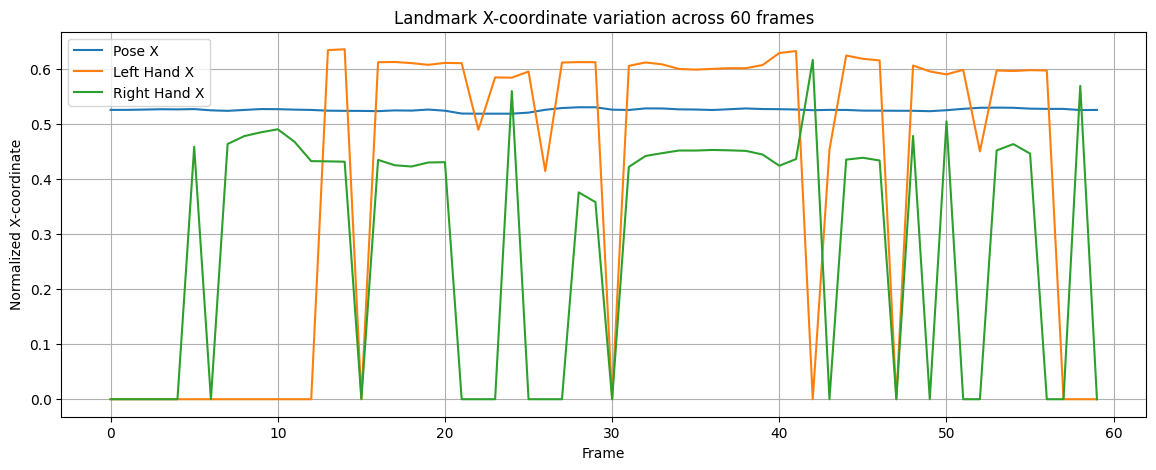

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(test_features[:, 0], label="Pose X")
plt.plot(test_features[:, 132], label="Left Hand X")
plt.plot(test_features[:, 195], label="Right Hand X")

plt.title("Landmark X-coordinate variation across 60 frames")
plt.xlabel("Frame")
plt.ylabel("Normalized X-coordinate")
plt.legend()
plt.grid()

plt.show()

In [ ]:
import inspect

print(inspect.getsource(normalize_landmarks))

NameError: name 'normalize_landmarks' is not defined

In [ ]:
import inspect

print(inspect.getsource(extract_video_keypoints))

def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    # Sample up to 60 frames
    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vi

In [ ]:
features = np.concatenate([
    pose.flatten(),
    left_hand.flatten(),
    right_hand.flatten()
])

NameError: name 'pose' is not defined

In [ ]:
# Check coordinate ranges for detected landmarks

pose = test_features[:, :132].reshape(60, 33, 4)
left = test_features[:, 132:195].reshape(60, 21, 3)
right = test_features[:, 195:258].reshape(60, 21, 3)

def inspect_coordinates(name, data):
    valid = np.any(data != 0, axis=2)
    detected = data[valid]

    print(f"\n{name}")
    print("Detected landmarks:", len(detected))

    if len(detected):
        print("X range:", detected[:, 0].min(), "to", detected[:, 0].max())
        print("Y range:", detected[:, 1].min(), "to", detected[:, 1].max())
        print("Z range:", detected[:, 2].min(), "to", detected[:, 2].max())

inspect_coordinates("Pose", pose)
inspect_coordinates("Left Hand", left)
inspect_coordinates("Right Hand", right)


Pose
Detected landmarks: 1980
X range: 0.30888084 to 0.68717253
Y range: 0.2686358 to 1.850156
Z range: -1.1951737 to 0.5731606

Left Hand
Detected landmarks: 840
X range: 0.328747 to 0.7012762
Y range: 0.41473985 to 0.8885879
Z range: -0.05103592 to 0.009870024

Right Hand
Detected landmarks: 798
X range: 0.30250812 to 0.65991354
Y range: 0.38969404 to 1.0360281
Z range: -0.06549437 to 0.017205164


In [ ]:
pose_valid = np.any(pose != 0, axis=(1, 2))
left_valid = np.any(left != 0, axis=(1, 2))
right_valid = np.any(right != 0, axis=(1, 2))

print("Pose detected:", pose_valid.sum(), "/ 60 frames")
print("Left hand detected:", left_valid.sum(), "/ 60 frames")
print("Right hand detected:", right_valid.sum(), "/ 60 frames")

print("\nFrames with both hands:")
print(np.sum(left_valid & right_valid))

print("\nFrames with pose but no hands:")
print(np.sum(pose_valid & ~left_valid & ~right_valid))

print("\nFrames with hands but no pose:")
print(np.sum(~pose_valid & (left_valid | right_valid)))

Pose detected: 60 / 60 frames
Left hand detected: 40 / 60 frames
Right hand detected: 38 / 60 frames

Frames with both hands:
29

Frames with pose but no hands:
11

Frames with hands but no pose:
0


In [ ]:
import random
import os
import numpy as np

random.seed(42)

test_videos = random.sample(video_files, 5)

for path in test_videos:
    features = extract_video_keypoints(path)

    if features is None:
        print("\nFAILED:", path)
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    pose_count = np.sum(np.any(pose != 0, axis=(1, 2)))
    left_count = np.sum(np.any(left != 0, axis=(1, 2)))
    right_count = np.sum(np.any(right != 0, axis=(1, 2)))

    print("\nVideo:", os.path.basename(path))
    print("Pose:", pose_count, "/60")
    print("Left hand:", left_count, "/60")
    print("Right hand:", right_count, "/60")


Video: where are you from (5).MP4
Pose: 60 /60
Left hand: 11 /60
Right hand: 36 /60

Video: take care.MP4
Pose: 60 /60
Left hand: 0 /60
Right hand: 40 /60

Video: pour.MP4
Pose: 60 /60
Left hand: 8 /60
Right hand: 29 /60

Video: do me a favour (2).mp4
Pose: 60 /60
Left hand: 52 /60
Right hand: 24 /60

Video: i was stopped by someone.mp4
Pose: 60 /60
Left hand: 46 /60
Right hand: 26 /60


In [ ]:
import cv2
import mediapipe as mp
import numpy as np

video_path = test_videos[0]

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
indices = np.linspace(0, total_frames - 1, 10, dtype=int)

with vision.HandLandmarker.create_from_options(hand_options) as detector:

    for i, frame_idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ret, frame = cap.read()

        if not ret:
            continue

        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image
        )

        result = detector.detect(mp_image)

        if result.hand_landmarks:
            sides = [
                h[0].category_name
                for h in result.handedness
            ]
            print(f"Frame {frame_idx}: {sides}")
        else:
            print(f"Frame {frame_idx}: No hands")

cap.release()

ValueError: Task is not initialized with the image mode. Current running mode:video mode

In [ ]:
hand_image_options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=HAND_MODEL
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2
)

video_path = test_videos[0]

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
indices = np.linspace(0, total_frames - 1, 10, dtype=int)

with vision.HandLandmarker.create_from_options(hand_image_options) as detector:

    for frame_idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ret, frame = cap.read()

        if not ret:
            continue

        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image
        )

        result = detector.detect(mp_image)

        if result.hand_landmarks:
            sides = [
                h[0].category_name
                for h in result.handedness
            ]
            print(f"Frame {frame_idx}: {sides}")
        else:
            print(f"Frame {frame_idx}: No hands")

cap.release()

Frame 0: No hands
Frame 10: No hands
Frame 21: No hands
Frame 31: No hands
Frame 42: ['Right']
Frame 52: ['Left']
Frame 63: ['Right', 'Right']
Frame 73: ['Right', 'Left']
Frame 84: ['Right']
Frame 95: ['Right', 'Left']


In [ ]:
video_path = test_videos[0]

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
indices = np.linspace(0, total_frames - 1, 10, dtype=int)

with vision.HandLandmarker.create_from_options(hand_image_options) as detector:

    for frame_idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ret, frame = cap.read()

        if not ret:
            continue

        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image
        )

        result = detector.detect(mp_image)

        if result.handedness:
            print(f"\nFrame {frame_idx}")

            for hand in result.handedness:
                category = hand[0]
                print(
                    "Label:", category.category_name,
                    "| Confidence:", round(category.score, 4)
                )

cap.release()


Frame 42
Label: Right | Confidence: 0.9874

Frame 52
Label: Left | Confidence: 0.932

Frame 63
Label: Right | Confidence: 0.9982
Label: Right | Confidence: 0.7464

Frame 73
Label: Right | Confidence: 0.9934
Label: Left | Confidence: 0.8441

Frame 84
Label: Right | Confidence: 0.9854

Frame 95
Label: Right | Confidence: 0.9929
Label: Left | Confidence: 0.9755


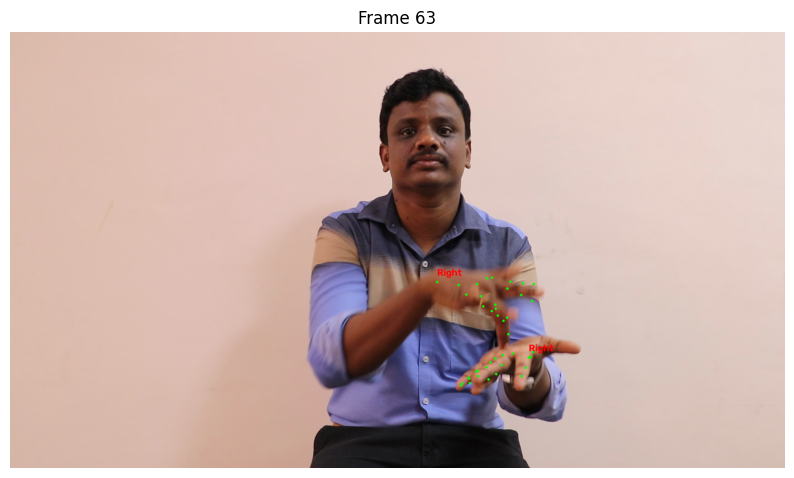

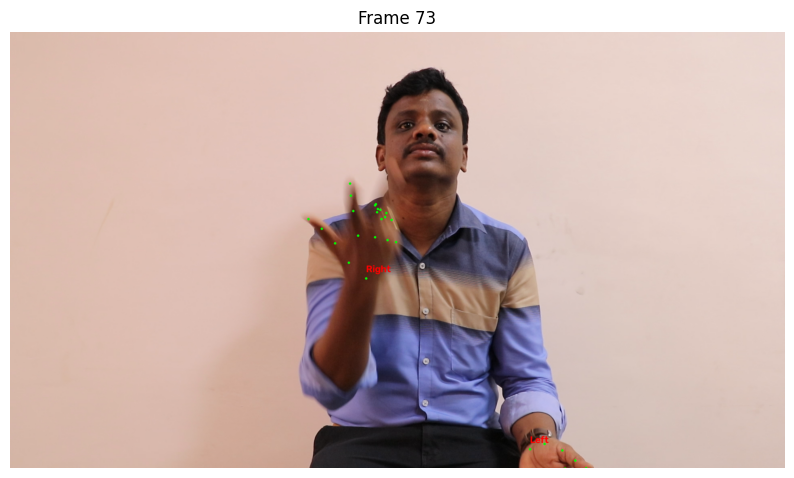

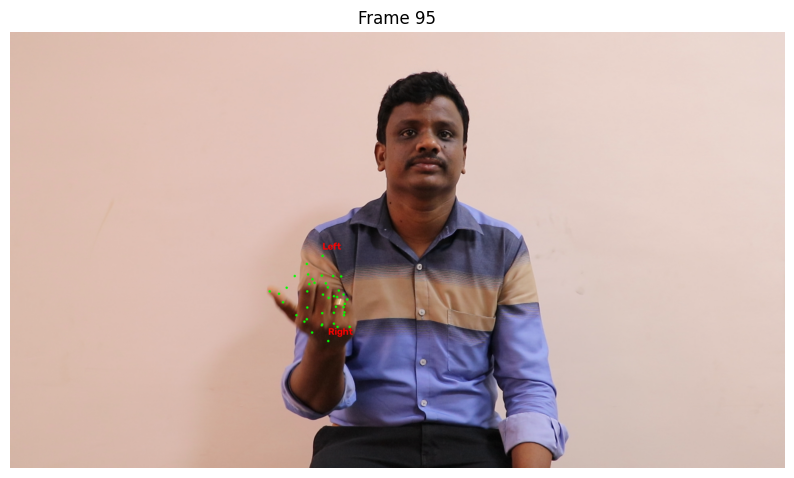

In [ ]:
import matplotlib.pyplot as plt
import cv2
import mediapipe as mp

video_path = test_videos[0]
frames_to_check = [63, 73, 95]

cap = cv2.VideoCapture(video_path)

with vision.HandLandmarker.create_from_options(hand_image_options) as detector:

    for frame_idx in frames_to_check:

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()

        if not ret:
            continue

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        result = detector.detect(
            mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )
        )

        annotated = rgb.copy()

        if result.hand_landmarks:
            for i, landmarks in enumerate(result.hand_landmarks):

                h, w, _ = annotated.shape

                for lm in landmarks:
                    x = int(lm.x * w)
                    y = int(lm.y * h)
                    cv2.circle(annotated, (x, y), 3, (0, 255, 0), -1)

                label = result.handedness[i][0].category_name

                wrist = landmarks[0]
                cv2.putText(
                    annotated,
                    label,
                    (int(wrist.x * w), int(wrist.y * h) - 15),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (255, 0, 0),
                    2
                )

        plt.figure(figsize=(10, 6))
        plt.imshow(annotated)
        plt.title(f"Frame {frame_idx}")
        plt.axis("off")
        plt.show()

cap.release()

In [ ]:
video_path = test_videos[0]
frames_to_check = [63, 73, 95]

cap = cv2.VideoCapture(video_path)

pose_image_options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=POSE_MODEL
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1
)

with vision.PoseLandmarker.create_from_options(pose_image_options) as pose_detector, \
     vision.HandLandmarker.create_from_options(hand_image_options) as hand_detector:

    for frame_idx in frames_to_check:

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()

        if not ret:
            continue

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        pose_result = pose_detector.detect(mp_image)
        hand_result = hand_detector.detect(mp_image)

        print(f"\nFRAME {frame_idx}")

        if not pose_result.pose_landmarks:
            print("Pose not detected")
            continue

        pose = pose_result.pose_landmarks[0]

        left_wrist = np.array([pose[15].x, pose[15].y])
        right_wrist = np.array([pose[16].x, pose[16].y])

        print("Pose left wrist:", left_wrist)
        print("Pose right wrist:", right_wrist)

        if hand_result.hand_landmarks:
            for i, hand in enumerate(hand_result.hand_landmarks):

                hand_wrist = np.array([hand[0].x, hand[0].y])

                left_distance = np.linalg.norm(hand_wrist - left_wrist)
                right_distance = np.linalg.norm(hand_wrist - right_wrist)

                print(
                    f"Hand {i + 1}:",
                    "MediaPipe label =", hand_result.handedness[i][0].category_name,
                    "| Distance to pose left wrist =", round(left_distance, 4),
                    "| Distance to pose right wrist =", round(right_distance, 4)
                )

cap.release()


FRAME 63
Pose left wrist: [0.66475189 0.7822848 ]
Pose right wrist: [0.54753393 0.60043287]
Hand 1: MediaPipe label = Right | Distance to pose left wrist = 0.2377 | Distance to pose right wrist = 0.0273
Hand 2: MediaPipe label = Right | Distance to pose left wrist = 0.0358 | Distance to pose right wrist = 0.1905

FRAME 73
Pose left wrist: [0.68651271 0.92572111]
Pose right wrist: [0.47075132 0.53541994]
Hand 1: MediaPipe label = Right | Distance to pose left wrist = 0.426 | Distance to pose right wrist = 0.0316
Hand 2: MediaPipe label = Left | Distance to pose left wrist = 0.0351 | Distance to pose right wrist = 0.4667

FRAME 95
Pose left wrist: [0.67103213 0.97844744]
Pose right wrist: [0.40993655 0.71439201]
Hand 1: MediaPipe label = Right | Distance to pose left wrist = 0.3746 | Distance to pose right wrist = 0.0052
Hand 2: MediaPipe label = Left | Distance to pose left wrist = 0.5367 | Distance to pose right wrist = 0.2012


In [ ]:
import random
import numpy as np
import cv2
import mediapipe as mp

random.seed(42)

validation_videos = random.sample(video_files, 20)

pose_image_options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1
)

distances = []

with vision.PoseLandmarker.create_from_options(pose_image_options) as pose_detector, \
     vision.HandLandmarker.create_from_options(hand_image_options) as hand_detector:

    for video in validation_videos:

        cap = cv2.VideoCapture(video)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total <= 0:
            cap.release()
            continue

        indices = np.linspace(0, total - 1, 10, dtype=int)

        for frame_idx in indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                continue

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            pose_result = pose_detector.detect(mp_image)
            hand_result = hand_detector.detect(mp_image)

            if not pose_result.pose_landmarks or not hand_result.hand_landmarks:
                continue

            pose = pose_result.pose_landmarks[0]

            wrists = [
                np.array([pose[15].x, pose[15].y]),
                np.array([pose[16].x, pose[16].y])
            ]

            for hand in hand_result.hand_landmarks:

                wrist = np.array([hand[0].x, hand[0].y])

                d_left = np.linalg.norm(wrist - wrists[0])
                d_right = np.linalg.norm(wrist - wrists[1])

                distances.append(min(d_left, d_right))

        cap.release()

distances = np.array(distances)

print("Total matched hand observations:", len(distances))
print("Mean distance:", distances.mean())
print("Median distance:", np.median(distances))
print("90th percentile:", np.percentile(distances, 90))
print("95th percentile:", np.percentile(distances, 95))

for threshold in [0.05, 0.10, 0.15, 0.20]:
    print(
        f"Within {threshold}:",
        f"{np.mean(distances <= threshold) * 100:.2f}%"
    )

Total matched hand observations: 199
Mean distance: 0.023445448972497823
Median distance: 0.021095829685300414
90th percentile: 0.04079826415779248
95th percentile: 0.04545826857089466
Within 0.05: 96.48%
Within 0.1: 99.50%
Within 0.15: 99.50%
Within 0.2: 99.50%


In [ ]:
def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0, total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                continue

            image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=image
            )

            timestamp_ms = frame_number * 1000

            pose_result = pose_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            hand_result = hand_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            pose = np.zeros((33, 4), dtype=np.float32)
            left_hand = np.zeros((21, 3), dtype=np.float32)
            right_hand = np.zeros((21, 3), dtype=np.float32)

            if pose_result.pose_landmarks:

                pose = np.array([
                    [lm.x, lm.y, lm.z, lm.visibility]
                    for lm in pose_result.pose_landmarks[0]
                ], dtype=np.float32)

                pose_left_wrist = np.array([
                    pose[15, 0], pose[15, 1]
                ])

                pose_right_wrist = np.array([
                    pose[16, 0], pose[16, 1]
                ])

                candidates = []

                if hand_result.hand_landmarks:

                    for landmarks in hand_result.hand_landmarks:

                        hand = np.array([
                            [lm.x, lm.y, lm.z]
                            for lm in landmarks
                        ], dtype=np.float32)

                        hand_wrist = hand[0, :2]

                        d_left = np.linalg.norm(
                            hand_wrist - pose_left_wrist
                        )

                        d_right = np.linalg.norm(
                            hand_wrist - pose_right_wrist
                        )

                        candidates.append(
                            (min(d_left, d_right),
                             d_left, d_right, hand)
                        )

                # Assign closest hands without duplicate wrist assignments
                used_sides = set()

                for distance, d_left, d_right, hand in sorted(
                    candidates, key=lambda x: x[0]
                ):

                    if distance > 0.05:
                        continue

                    side = "Left" if d_left < d_right else "Right"

                    if side in used_sides:
                        continue

                    if side == "Left":
                        left_hand = hand
                    else:
                        right_hand = hand

                    used_sides.add(side)

            elif hand_result.hand_landmarks:
                # No pose: retain no anatomical hand assignment.
                pass

            features = np.concatenate([
                pose.flatten(),
                left_hand.flatten(),
                right_hand.flatten()
            ])

            frames_data.append(features)

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(frames_data, dtype=np.float32)

    if len(frames_data) < max_frames:
        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )
        frames_data = np.vstack([frames_data, padding])

    return frames_data

In [ ]:
import os
import numpy as np

for path in test_videos:

    features = extract_video_keypoints(path)

    if features is None:
        print("\nFAILED:", os.path.basename(path))
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    pose_count = np.sum(np.any(pose != 0, axis=(1, 2)))
    left_count = np.sum(np.any(left != 0, axis=(1, 2)))
    right_count = np.sum(np.any(right != 0, axis=(1, 2)))

    print("\nVideo:", os.path.basename(path))
    print("Pose:", pose_count, "/60")
    print("Left hand:", left_count, "/60")
    print("Right hand:", right_count, "/60")
    print("Both hands:", np.sum(
        np.any(left != 0, axis=(1, 2)) &
        np.any(right != 0, axis=(1, 2))
    ))


Video: where are you from (5).MP4
Pose: 60 /60
Left hand: 10 /60
Right hand: 33 /60
Both hands: 8

Video: take care.MP4
Pose: 60 /60
Left hand: 0 /60
Right hand: 40 /60
Both hands: 0

Video: pour.MP4
Pose: 60 /60
Left hand: 10 /60
Right hand: 27 /60
Both hands: 5

Video: do me a favour (2).mp4
Pose: 60 /60
Left hand: 48 /60
Right hand: 21 /60
Both hands: 18

Video: i was stopped by someone.mp4
Pose: 60 /60
Left hand: 54 /60
Right hand: 22 /60
Both hands: 20


In [ ]:
from itertools import permutations
import numpy as np

def assign_hands_to_wrists(hand_landmarks, pose):
    """
    Assign detected hands to anatomical left/right wrists.
    Reject uncertain assignments.
    """

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    # Pose wrist coordinates
    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:
        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    # One detected hand
    if len(candidates) == 1:
        hand, distances = candidates[0]
        side = int(np.argmin(distances))

        if distances[side] <= 0.05:
            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    # Two detected hands: evaluate both assignments
    best_assignment = None
    best_cost = float("inf")

    for assignment in permutations([0, 1], 2):
        cost = sum(
            candidates[i][1][assignment[i]]
            for i in range(2)
        )

        if cost < best_cost:
            best_cost = cost
            best_assignment = assignment

    if best_assignment is not None:
        distances = [
            candidates[i][1][best_assignment[i]]
            for i in range(2)
        ]

        if all(d <= 0.05 for d in distances):
            for i, side in enumerate(best_assignment):
                if side == 0:
                    left_hand = candidates[i][0]
                else:
                    right_hand = candidates[i][0]

    return left_hand, right_hand

print("Optimal hand assignment function created successfully!")

Optimal hand assignment function created successfully!


In [ ]:
print("Function:", assign_hands_to_wrists.__name__)
print("Ready for integration:", callable(assign_hands_to_wrists))

Function: assign_hands_to_wrists
Ready for integration: True


In [ ]:
def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0, total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                continue

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            timestamp_ms = frame_number * 1000

            pose_result = pose_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            hand_result = hand_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            pose = np.zeros((33, 4), dtype=np.float32)
            left_hand = np.zeros((21, 3), dtype=np.float32)
            right_hand = np.zeros((21, 3), dtype=np.float32)

            if pose_result.pose_landmarks:

                pose = np.array([
                    [lm.x, lm.y, lm.z, lm.visibility]
                    for lm in pose_result.pose_landmarks[0]
                ], dtype=np.float32)

                left_hand, right_hand = assign_hands_to_wrists(
                    hand_result.hand_landmarks,
                    pose
                )

            features = np.concatenate([
                pose.flatten(),
                left_hand.flatten(),
                right_hand.flatten()
            ])

            frames_data.append(features)

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(frames_data, dtype=np.float32)

    if len(frames_data) < max_frames:
        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )
        frames_data = np.vstack([frames_data, padding])

    return frames_data

In [ ]:
for path in test_videos:

    features = extract_video_keypoints(path)

    if features is None:
        print("FAILED:", os.path.basename(path))
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    print("\nVideo:", os.path.basename(path))
    print("Shape:", features.shape)
    print("Pose:", np.sum(np.any(pose != 0, axis=(1, 2))))
    print("Left:", np.sum(np.any(left != 0, axis=(1, 2))))
    print("Right:", np.sum(np.any(right != 0, axis=(1, 2))))


Video: where are you from (5).MP4
Shape: (60, 258)
Pose: 60
Left: 9
Right: 27

Video: take care.MP4
Shape: (60, 258)
Pose: 60
Left: 0
Right: 40

Video: pour.MP4
Shape: (60, 258)
Pose: 60
Left: 10
Right: 26

Video: do me a favour (2).mp4
Shape: (60, 258)
Pose: 60
Left: 41
Right: 21

Video: i was stopped by someone.mp4
Shape: (60, 258)
Pose: 60
Left: 52
Right: 22


In [ ]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import os

for video_path in test_videos:

    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    indices = np.linspace(
        0, total_frames - 1,
        min(60, total_frames),
        dtype=int
    )

    detected_hands = 0
    accepted_hands = 0
    rejected_hands = 0
    distances_all = []

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                continue

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            timestamp_ms = frame_number * 1000

            pose_result = pose_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            hand_result = hand_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            if not pose_result.pose_landmarks:
                continue

            pose = np.array([
                [lm.x, lm.y, lm.z, lm.visibility]
                for lm in pose_result.pose_landmarks[0]
            ], dtype=np.float32)

            for landmarks in hand_result.hand_landmarks:

                detected_hands += 1

                wrist = np.array([
                    landmarks[0].x,
                    landmarks[0].y
                ])

                left_wrist = pose[15, :2]
                right_wrist = pose[16, :2]

                distance = min(
                    np.linalg.norm(wrist - left_wrist),
                    np.linalg.norm(wrist - right_wrist)
                )

                distances_all.append(distance)

                if distance <= 0.05:
                    accepted_hands += 1
                else:
                    rejected_hands += 1

    cap.release()

    print("\nVideo:", os.path.basename(video_path))
    print("Detected hands:", detected_hands)
    print("Accepted:", accepted_hands)
    print("Rejected:", rejected_hands)

    if distances_all:
        print("Mean wrist distance:", round(np.mean(distances_all), 4))
        print("Maximum wrist distance:", round(np.max(distances_all), 4))


Video: where are you from (5).MP4
Detected hands: 52
Accepted: 45
Rejected: 7
Mean wrist distance: 0.0335
Maximum wrist distance: 0.1878

Video: take care.MP4
Detected hands: 40
Accepted: 40
Rejected: 0
Mean wrist distance: 0.0142
Maximum wrist distance: 0.0324

Video: pour.MP4
Detected hands: 38
Accepted: 38
Rejected: 0
Mean wrist distance: 0.023
Maximum wrist distance: 0.0428

Video: do me a favour (2).mp4
Detected hands: 77
Accepted: 69
Rejected: 8
Mean wrist distance: 0.0318
Maximum wrist distance: 0.0593

Video: i was stopped by someone.mp4
Detected hands: 78
Accepted: 76
Rejected: 2
Mean wrist distance: 0.0222
Maximum wrist distance: 0.1308


In [ ]:
import numpy as np

# Use the distances collected in the previous diagnostic.
distances = np.array(distances_all)

print("Distance distribution")
print("Minimum:", round(distances.min(), 4))
print("25th percentile:", round(np.percentile(distances, 25), 4))
print("Median:", round(np.median(distances), 4))
print("75th percentile:", round(np.percentile(distances, 75), 4))
print("90th percentile:", round(np.percentile(distances, 90), 4))
print("95th percentile:", round(np.percentile(distances, 95), 4))
print("Maximum:", round(distances.max(), 4))

for threshold in [0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.10]:
    accepted = np.sum(distances <= threshold)
    print(
        f"Threshold {threshold:.2f}: "
        f"{accepted}/{len(distances)} "
        f"({accepted / len(distances) * 100:.1f}%)"
    )

Distance distribution
Minimum: 0.0027
25th percentile: 0.0123
Median: 0.0192
75th percentile: 0.0292
90th percentile: 0.0388
95th percentile: 0.0417
Maximum: 0.1308
Threshold 0.03: 61/78 (78.2%)
Threshold 0.04: 73/78 (93.6%)
Threshold 0.05: 76/78 (97.4%)
Threshold 0.06: 76/78 (97.4%)
Threshold 0.07: 77/78 (98.7%)
Threshold 0.08: 77/78 (98.7%)
Threshold 0.10: 77/78 (98.7%)


In [ ]:
all_distances = []

for video_path in test_videos:

    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    indices = np.linspace(
        0, total_frames - 1,
        min(60, total_frames),
        dtype=int
    )

    with vision.PoseLandmarker.create_from_options(pose_options) as pose_detector, \
         vision.HandLandmarker.create_from_options(hand_options) as hand_detector:

        for frame_number, frame_idx in enumerate(indices):

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                continue

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            timestamp_ms = frame_number * 1000

            pose_result = pose_detector.detect_for_video(
                mp_image, timestamp_ms
            )
            hand_result = hand_detector.detect_for_video(
                mp_image, timestamp_ms
            )

            if not pose_result.pose_landmarks:
                continue

            pose = np.array([
                [lm.x, lm.y, lm.z, lm.visibility]
                for lm in pose_result.pose_landmarks[0]
            ], dtype=np.float32)

            for landmarks in hand_result.hand_landmarks:

                wrist = np.array([landmarks[0].x, landmarks[0].y])

                distance = min(
                    np.linalg.norm(wrist - pose[15, :2]),
                    np.linalg.norm(wrist - pose[16, :2])
                )

                all_distances.append(distance)

    cap.release()

all_distances = np.array(all_distances)

print("Total hand detections:", len(all_distances))
print("Median:", round(np.median(all_distances), 4))
print("90th percentile:", round(np.percentile(all_distances, 90), 4))
print("95th percentile:", round(np.percentile(all_distances, 95), 4))
print("Maximum:", round(np.max(all_distances), 4))

for threshold in [0.04, 0.05, 0.06, 0.07, 0.08]:
    accepted = np.sum(all_distances <= threshold)
    print(
        f"{threshold:.2f}: {accepted}/{len(all_distances)} "
        f"({accepted / len(all_distances) * 100:.2f}%)"
    )

Total hand detections: 285
Median: 0.0231
90th percentile: 0.0431
95th percentile: 0.0503
Maximum: 0.1878
0.04: 247/285 (86.67%)
0.05: 268/285 (94.04%)
0.06: 278/285 (97.54%)
0.07: 281/285 (98.60%)
0.08: 282/285 (98.95%)


In [ ]:
from itertools import permutations
import numpy as np

def assign_hands_to_wrists(hand_landmarks, pose):

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:

        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    threshold = 0.05

    # Single detected hand
    if len(candidates) == 1:

        hand, distances = candidates[0]

        side = int(np.argmin(distances))

        if distances[side] <= threshold:

            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    # Two detected hands
    assignments = list(permutations([0, 1], 2))

    costs = [
        sum(candidates[i][1][assignment[i]] for i in range(2))
        for assignment in assignments
    ]

    best_index = int(np.argmin(costs))
    best_assignment = assignments[best_index]

    sorted_costs = sorted(costs)

    # Reject if either hand is too far from its assigned wrist
    assigned_distances = [
        candidates[i][1][best_assignment[i]]
        for i in range(2)
    ]

    if any(distance > threshold for distance in assigned_distances):
        return left_hand, right_hand

    # Reject ambiguous assignments
    if sorted_costs[1] - sorted_costs[0] < 0.02:
        return left_hand, right_hand

    for i, side in enumerate(best_assignment):

        if side == 0:
            left_hand = candidates[i][0]
        else:
            right_hand = candidates[i][0]

    return left_hand, right_hand

In [ ]:
for path in test_videos:

    features = extract_video_keypoints(path)

    if features is None:
        print("\nFAILED:", os.path.basename(path))
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    print("\nVideo:", os.path.basename(path))
    print("Shape:", features.shape)
    print("Pose frames:", np.sum(np.any(pose != 0, axis=(1, 2))))
    print("Left-hand frames:", np.sum(np.any(left != 0, axis=(1, 2))))
    print("Right-hand frames:", np.sum(np.any(right != 0, axis=(1, 2))))
    print("Both hands:", np.sum(
        np.any(left != 0, axis=(1, 2)) &
        np.any(right != 0, axis=(1, 2))
    ))


Video: where are you from (5).MP4
Shape: (60, 258)
Pose frames: 60
Left-hand frames: 9
Right-hand frames: 27
Both hands: 8

Video: take care.MP4
Shape: (60, 258)
Pose frames: 60
Left-hand frames: 0
Right-hand frames: 40
Both hands: 0

Video: pour.MP4
Shape: (60, 258)
Pose frames: 60
Left-hand frames: 10
Right-hand frames: 26
Both hands: 5

Video: do me a favour (2).mp4
Shape: (60, 258)
Pose frames: 60
Left-hand frames: 41
Right-hand frames: 21
Both hands: 18

Video: i was stopped by someone.mp4
Shape: (60, 258)
Pose frames: 60
Left-hand frames: 52
Right-hand frames: 22
Both hands: 20


In [ ]:
import random

random.seed(123)

validation_videos = random.sample(video_files, 20)

for path in validation_videos:

    features = extract_video_keypoints(path)

    if features is None:
        print("FAILED:", os.path.basename(path))
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    print(
        os.path.basename(path),
        "| Pose:", np.sum(np.any(pose != 0, axis=(1, 2))),
        "| Left:", np.sum(np.any(left != 0, axis=(1, 2))),
        "| Right:", np.sum(np.any(right != 0, axis=(1, 2)))
    )

never hurt (4).MP4 | Pose: 60 | Left: 24 | Right: 41
i do not like it.mp4 | Pose: 60 | Left: 52 | Right: 18
somehow (5).MP4 | Pose: 60 | Left: 36 | Right: 40
can do (5).MP4 | Pose: 60 | Left: 12 | Right: 20
hate (3).MP4 | Pose: 60 | Left: 22 | Right: 32
mean.MP4 | Pose: 60 | Left: 29 | Right: 45
help me (4).MP4 | Pose: 60 | Left: 6 | Right: 47
welcome.MP4 | Pose: 60 | Left: 23 | Right: 27
i am crying.mp4 | Pose: 60 | Left: 48 | Right: 36
my name is xxxxxxxx (2).MP4 | Pose: 60 | Left: 10 | Right: 25
congratulations (7).MP4 | Pose: 54 | Left: 0 | Right: 28
MVI_6849.MP4 | Pose: 60 | Left: 23 | Right: 44
tired.MP4 | Pose: 60 | Left: 24 | Right: 30
truth (4).MP4 | Pose: 60 | Left: 43 | Right: 47
congratulations (2).mp4 | Pose: 50 | Left: 50 | Right: 19
my name is xxxxxxxx (5).MP4 | Pose: 60 | Left: 26 | Right: 46
congratulations.mp4 | Pose: 50 | Left: 48 | Right: 9
MVI_6504.MP4 | Pose: 60 | Left: 8 | Right: 39
what do you think (1).MP4 | Pose: 60 | Left: 8 | Right: 11
i am sitting in the cl

In [ ]:
for path in validation_videos:

    features = extract_video_keypoints(path)

    if features is None:
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    pose_present = np.any(pose != 0, axis=(1, 2))
    left_present = np.any(left != 0, axis=(1, 2))
    right_present = np.any(right != 0, axis=(1, 2))

    print("\n", os.path.basename(path))
    print("Non-finite values:", np.sum(~np.isfinite(features)))
    print("Feature min:", round(float(features.min()), 4))
    print("Feature max:", round(float(features.max()), 4))
    print("Pose missing:", np.sum(~pose_present))
    print("Both hands missing:", np.sum(~left_present & ~right_present))
    print("Only left missing:", np.sum(~left_present & right_present))
    print("Only right missing:", np.sum(left_present & ~right_present))


 never hurt (4).MP4
Non-finite values: 0
Feature min: -1.1622
Feature max: 1.864
Pose missing: 0
Both hands missing: 15
Only left missing: 21
Only right missing: 4

 i do not like it.mp4
Non-finite values: 0
Feature min: -1.7256
Feature max: 1.6771
Pose missing: 0
Both hands missing: 7
Only left missing: 1
Only right missing: 35

 somehow (5).MP4
Non-finite values: 0
Feature min: -0.886
Feature max: 1.5502
Pose missing: 0
Both hands missing: 2
Only left missing: 22
Only right missing: 18

 can do (5).MP4
Non-finite values: 0
Feature min: -0.8367
Feature max: 1.6379
Pose missing: 0
Both hands missing: 31
Only left missing: 17
Only right missing: 9

 hate (3).MP4
Non-finite values: 0
Feature min: -1.0362
Feature max: 1.8262
Pose missing: 0
Both hands missing: 24
Only left missing: 14
Only right missing: 4

 mean.MP4
Non-finite values: 0
Feature min: -1.0425
Feature max: 1.7273
Pose missing: 0
Both hands missing: 9
Only left missing: 22
Only right missing: 6

 help me (4).MP4
Non-finite 

KeyboardInterrupt: 

In [ ]:
for path in validation_videos:

    features = extract_video_keypoints(path)

    if features is None:
        continue

    pose = features[:, :132].reshape(60, 33, 4)
    left = features[:, 132:195].reshape(60, 21, 3)
    right = features[:, 195:258].reshape(60, 21, 3)

    pose_present = np.any(pose != 0, axis=(1, 2))
    left_present = np.any(left != 0, axis=(1, 2))
    right_present = np.any(right != 0, axis=(1, 2))

    print("\n", os.path.basename(path))
    print("Non-finite values:", np.sum(~np.isfinite(features)))
    print("Feature min:", round(float(features.min()), 4))
    print("Feature max:", round(float(features.max()), 4))
    print("Pose missing:", np.sum(~pose_present))
    print("Both hands missing:", np.sum(~left_present & ~right_present))
    print("Only left missing:", np.sum(~left_present & right_present))
    print("Only right missing:", np.sum(left_present & ~right_present))

KeyboardInterrupt: 

In [ ]:
for path in validation_videos:

    features = extract_video_keypoints(path)

    if features is None:
        continue

    pose = features[:, :132].reshape(60, 33, 4)

    left_visibility = pose[:, 15, 3]
    right_visibility = pose[:, 16, 3]

    print("\n", os.path.basename(path))

    print("Left wrist mean visibility:",
          round(float(np.mean(left_visibility)), 3))

    print("Right wrist mean visibility:",
          round(float(np.mean(right_visibility)), 3))

    print("Left wrist reliable frames:",
          np.sum(left_visibility > 0.5))

    print("Right wrist reliable frames:",
          np.sum(right_visibility > 0.5))


 never hurt (4).MP4
Left wrist mean visibility: 0.959
Right wrist mean visibility: 0.974
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 i do not like it.mp4
Left wrist mean visibility: 0.983
Right wrist mean visibility: 0.782
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 somehow (5).MP4
Left wrist mean visibility: 0.951
Right wrist mean visibility: 0.974
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 can do (5).MP4
Left wrist mean visibility: 0.963
Right wrist mean visibility: 0.844
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 hate (3).MP4
Left wrist mean visibility: 0.97
Right wrist mean visibility: 0.974
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 mean.MP4
Left wrist mean visibility: 0.986
Right wrist mean visibility: 0.985
Left wrist reliable frames: 60
Right wrist reliable frames: 60

 help me (4).MP4
Left wrist mean visibility: 0.963
Right wrist mean visibility: 0.958
Left wrist reliab

In [ ]:
import os
import json
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

os.makedirs(OUTPUT_DIR, exist_ok=True)

FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
os.makedirs(FEATURE_DIR, exist_ok=True)

print("Extraction directory:", OUTPUT_DIR)
print("Videos available:", len(video_files))
print("Extractor ready:", callable(extract_video_keypoints))
print("Hand assignment ready:", callable(assign_hands_to_wrists))

Extraction directory: /content/drive/MyDrive/EchoGesture/extraction_v2
Videos available: 687
Extractor ready: True
Hand assignment ready: True


In [ ]:
import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

records = []
success_count = 0
failed_count = 0
start_time = time.time()

PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

# Resume if extraction was previously interrupted
completed = set()

if os.path.exists(PROGRESS_FILE):
    previous = pd.read_csv(PROGRESS_FILE)
    records = previous.to_dict("records")
    completed = set(previous["video_path"].astype(str))
    success_count = sum(r["status"] == "success" for r in records)
    failed_count = sum(r["status"] == "failed" for r in records)

print("Already processed:", len(completed))
print("Remaining:", len(video_files) - len(completed))

for video_path in tqdm(video_files, desc="Extracting videos"):

    video_path = str(video_path)

    if video_path in completed:
        continue

    filename = os.path.basename(video_path)
    output_name = f"{len(records):05d}.npy"
    output_path = os.path.join(FEATURE_DIR, output_name)

    try:
        features = extract_video_keypoints(video_path)

        if (
            features is not None
            and features.shape == (60, 258)
            and np.isfinite(features).all()
        ):
            np.save(output_path, features)

            records.append({
                "filename": filename,
                "video_path": video_path,
                "feature_file": output_name,
                "status": "success"
            })

            success_count += 1

        else:
            records.append({
                "filename": filename,
                "video_path": video_path,
                "feature_file": "",
                "status": "failed"
            })

            failed_count += 1

    except Exception as e:

        records.append({
            "filename": filename,
            "video_path": video_path,
            "feature_file": "",
            "status": "failed"
        })

        failed_count += 1
        print("\nError:", filename, str(e))

    # Save progress every 10 videos
    if len(records) % 10 == 0:
        pd.DataFrame(records).to_csv(PROGRESS_FILE, index=False)

# Final save
progress_df = pd.DataFrame(records)
progress_df.to_csv(PROGRESS_FILE, index=False)

elapsed = (time.time() - start_time) / 60

print("\n========== EXTRACTION COMPLETE ==========")
print("Total processed:", len(records))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Time taken:", round(elapsed, 2), "minutes")
print("Features saved:", FEATURE_DIR)
print("Progress file:", PROGRESS_FILE)

Already processed: 200
Remaining: 487


Extracting videos:   0%|          | 0/687 [00:00<?, ?it/s]


Error: understand (3).MP4 name 'extract_video_keypoints' is not defined

Error: understand.MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (5).MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (6).MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (7).MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (3).MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (4).MP4 name 'extract_video_keypoints' is not defined

Error: how old are you (1).mp4 name 'extract_video_keypoints' is not defined

Error: how old are you (2).mp4 name 'extract_video_keypoints' is not defined

Error: i am (age) (1).MP4 name 'extract_video_keypoints' is not defined

Error: i am (age) (3).MP4 name 'extract_video_keypoints' is not defined

Error: i am (age) (6).mp4 name 'extract_video_keypoints' is not defined

Error: i am (age) (4).MP4 name 'extract_video_keypoints' is not defined

Error: i am (age) (

In [ ]:
import os
import numpy as np
import pandas as pd
import time
from tqdm.auto import tqdm

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("Feature directory:", FEATURE_DIR)
print("Videos available:", len(video_files))
print("Extractor ready:", callable(extract_video_keypoints))
print("Hand assignment ready:", callable(assign_hands_to_wrists))

Output directory: /content/drive/MyDrive/EchoGesture/extraction_v2
Feature directory: /content/drive/MyDrive/EchoGesture/extraction_v2/keypoints


NameError: name 'video_files' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import kagglehub
import os

DATASET_ROOT = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

print("Dataset:", DATASET_ROOT)

Using Colab cache for faster access to the 'isl-csltr-indian-sign-language-dataset' dataset.
Dataset: /kaggle/input/isl-csltr-indian-sign-language-dataset


In [ ]:
VIDEO_DIR = os.path.join(
    DATASET_ROOT,
    "ISL_CSLRT_Corpus",
    "ISL_CSLRT_Corpus",
    "Videos_Sentence_Level"
)

video_files = []

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_files.append(os.path.join(root, file))

print("Videos found:", len(video_files))

Videos found: 687


In [ ]:
!pip install -q mediapipe opencv-python

import os
import cv2
import numpy as np
import mediapipe as mp
import urllib.request

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

pose_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/1/"
    "pose_landmarker_full.task"
)

hand_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not os.path.exists(POSE_MODEL):
    urllib.request.urlretrieve(pose_url, POSE_MODEL)

if not os.path.exists(HAND_MODEL):
    urllib.request.urlretrieve(hand_url, HAND_MODEL)

print("MediaPipe version:", mp.__version__)
print("Pose model downloaded:", os.path.exists(POSE_MODEL))
print("Hand model downloaded:", os.path.exists(HAND_MODEL))

MediaPipe version: 1.2.3
Pose model downloaded: True
Hand model downloaded: True


In [ ]:
# ==========================================
# ECHOGESTURE EXTRACTION V2
# ==========================================

# Output directories
OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    OUTPUT_DIR, "extraction_progress.csv"
)

# ------------------------------------------
# 1. Hand assignment
# ------------------------------------------

def assign_hands_to_wrists(hand_landmarks, pose):

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:

        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    threshold = 0.05

    if len(candidates) == 1:

        hand, distances = candidates[0]
        side = int(np.argmin(distances))

        if distances[side] <= threshold:
            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    assignments = list(permutations([0, 1], 2))

    costs = [
        sum(
            candidates[i][1][assignment[i]]
            for i in range(2)
        )
        for assignment in assignments
    ]

    best_index = int(np.argmin(costs))
    best_assignment = assignments[best_index]

    sorted_costs = sorted(costs)

    assigned_distances = [
        candidates[i][1][best_assignment[i]]
        for i in range(2)
    ]

    if any(d > threshold for d in assigned_distances):
        return left_hand, right_hand

    if sorted_costs[1] - sorted_costs[0] < 0.02:
        return left_hand, right_hand

    for i, side in enumerate(best_assignment):

        if side == 0:
            left_hand = candidates[i][0]
        else:
            right_hand = candidates[i][0]

    return left_hand, right_hand


# ------------------------------------------
# 2. Video feature extraction
# ------------------------------------------

def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    try:

        with vision.PoseLandmarker.create_from_options(
            pose_options
        ) as pose_detector, \
        vision.HandLandmarker.create_from_options(
            hand_options
        ) as hand_detector:

            for frame_number, frame_idx in enumerate(indices):

                cap.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    int(frame_idx)
                )

                ret, frame = cap.read()

                if not ret:
                    continue

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb
                )

                timestamp_ms = frame_number * 1000

                pose_result = pose_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                hand_result = hand_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                pose = np.zeros((33, 4), dtype=np.float32)
                left_hand = np.zeros((21, 3), dtype=np.float32)
                right_hand = np.zeros((21, 3), dtype=np.float32)

                if pose_result.pose_landmarks:

                    pose = np.array([
                        [
                            lm.x,
                            lm.y,
                            lm.z,
                            lm.visibility
                        ]
                        for lm in pose_result.pose_landmarks[0]
                    ], dtype=np.float32)

                    left_hand, right_hand = assign_hands_to_wrists(
                        hand_result.hand_landmarks,
                        pose
                    )

                features = np.concatenate([
                    pose.flatten(),
                    left_hand.flatten(),
                    right_hand.flatten()
                ])

                frames_data.append(features)

    except Exception as e:
        print("Extraction error:", os.path.basename(video_path), e)
        cap.release()
        return None

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(
        frames_data,
        dtype=np.float32
    )

    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data


# ------------------------------------------
# 3. Resume support
# ------------------------------------------

records = []

if os.path.exists(PROGRESS_FILE):

    previous = pd.read_csv(PROGRESS_FILE)
    records = previous.to_dict("records")

completed = {
    str(r["video_path"]): r
    for r in records
}

# Skip successful files that already exist.
# Retry previously failed files.

successful_paths = {
    path
    for path, record in completed.items()
    if record["status"] == "success"
    and os.path.exists(
        os.path.join(FEATURE_DIR, record["feature_file"])
    )
}

print("Videos already completed:", len(successful_paths))
print("Videos remaining:", len(video_files) - len(successful_paths))


# ------------------------------------------
# 4. Extract all videos
# ------------------------------------------

start_time = time.time()

for video_index, video_path in enumerate(
    tqdm(video_files, desc="EchoGesture extraction")
):

    video_path = str(video_path)

    if video_path in successful_paths:
        continue

    filename = os.path.basename(video_path)

    output_name = f"sample_{video_index:05d}.npy"
    output_path = os.path.join(FEATURE_DIR, output_name)

    features = extract_video_keypoints(video_path)

    if (
        features is not None
        and features.shape == (60, 258)
        and np.isfinite(features).all()
    ):

        np.save(output_path, features)

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": output_name,
            "status": "success"
        }

    else:

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": "",
            "status": "failed"
        }

    completed[video_path] = record

    # Save progress every 10 newly processed videos
    processed_count = (
        len(successful_paths) +
        sum(
            1 for p in completed
            if p not in successful_paths
        )
    )

    if processed_count % 10 == 0:

        progress_df = pd.DataFrame(
            list(completed.values())
        )

        temp_file = PROGRESS_FILE + ".tmp"
        progress_df.to_csv(temp_file, index=False)
        os.replace(temp_file, PROGRESS_FILE)


# ------------------------------------------
# 5. Final report
# ------------------------------------------

progress_df = pd.DataFrame(
    [completed.get(str(path)) for path in video_files]
)

progress_df = progress_df.dropna(
    subset=["video_path"]
)

progress_df.to_csv(
    PROGRESS_FILE,
    index=False
)

success_count = (
    progress_df["status"] == "success"
).sum()

failed_count = (
    progress_df["status"] == "failed"
).sum()

elapsed = (time.time() - start_time) / 60

print("\n========== EXTRACTION COMPLETE ==========")
print("Total videos:", len(progress_df))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Time:", round(elapsed, 2), "minutes")
print("Features:", FEATURE_DIR)
print("Progress:", PROGRESS_FILE)

Videos already completed: 200
Videos remaining: 487


EchoGesture extraction:   0%|          | 0/687 [00:00<?, ?it/s]

In [ ]:
from itertools import permutations

print("Fix applied:", callable(permutations))

Fix applied: True


In [ ]:
# ==========================================
# ECHOGESTURE EXTRACTION V2
# ==========================================

# Output directories
OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    OUTPUT_DIR, "extraction_progress.csv"
)

# ------------------------------------------
# 1. Hand assignment
# ------------------------------------------

def assign_hands_to_wrists(hand_landmarks, pose):

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:

        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    threshold = 0.05

    if len(candidates) == 1:

        hand, distances = candidates[0]
        side = int(np.argmin(distances))

        if distances[side] <= threshold:
            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    assignments = list(permutations([0, 1], 2))

    costs = [
        sum(
            candidates[i][1][assignment[i]]
            for i in range(2)
        )
        for assignment in assignments
    ]

    best_index = int(np.argmin(costs))
    best_assignment = assignments[best_index]

    sorted_costs = sorted(costs)

    assigned_distances = [
        candidates[i][1][best_assignment[i]]
        for i in range(2)
    ]

    if any(d > threshold for d in assigned_distances):
        return left_hand, right_hand

    if sorted_costs[1] - sorted_costs[0] < 0.02:
        return left_hand, right_hand

    for i, side in enumerate(best_assignment):

        if side == 0:
            left_hand = candidates[i][0]
        else:
            right_hand = candidates[i][0]

    return left_hand, right_hand


# ------------------------------------------
# 2. Video feature extraction
# ------------------------------------------

def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    try:

        with vision.PoseLandmarker.create_from_options(
            pose_options
        ) as pose_detector, \
        vision.HandLandmarker.create_from_options(
            hand_options
        ) as hand_detector:

            for frame_number, frame_idx in enumerate(indices):

                cap.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    int(frame_idx)
                )

                ret, frame = cap.read()

                if not ret:
                    continue

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb
                )

                timestamp_ms = frame_number * 1000

                pose_result = pose_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                hand_result = hand_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                pose = np.zeros((33, 4), dtype=np.float32)
                left_hand = np.zeros((21, 3), dtype=np.float32)
                right_hand = np.zeros((21, 3), dtype=np.float32)

                if pose_result.pose_landmarks:

                    pose = np.array([
                        [
                            lm.x,
                            lm.y,
                            lm.z,
                            lm.visibility
                        ]
                        for lm in pose_result.pose_landmarks[0]
                    ], dtype=np.float32)

                    left_hand, right_hand = assign_hands_to_wrists(
                        hand_result.hand_landmarks,
                        pose
                    )

                features = np.concatenate([
                    pose.flatten(),
                    left_hand.flatten(),
                    right_hand.flatten()
                ])

                frames_data.append(features)

    except Exception as e:
        print("Extraction error:", os.path.basename(video_path), e)
        cap.release()
        return None

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(
        frames_data,
        dtype=np.float32
    )

    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data


# ------------------------------------------
# 3. Resume support
# ------------------------------------------

records = []

if os.path.exists(PROGRESS_FILE):

    previous = pd.read_csv(PROGRESS_FILE)
    records = previous.to_dict("records")

completed = {
    str(r["video_path"]): r
    for r in records
}

# Skip successful files that already exist.
# Retry previously failed files.

successful_paths = {
    path
    for path, record in completed.items()
    if record["status"] == "success"
    and os.path.exists(
        os.path.join(FEATURE_DIR, record["feature_file"])
    )
}

print("Videos already completed:", len(successful_paths))
print("Videos remaining:", len(video_files) - len(successful_paths))


# ------------------------------------------
# 4. Extract all videos
# ------------------------------------------

start_time = time.time()

for video_index, video_path in enumerate(
    tqdm(video_files, desc="EchoGesture extraction")
):

    video_path = str(video_path)

    if video_path in successful_paths:
        continue

    filename = os.path.basename(video_path)

    output_name = f"sample_{video_index:05d}.npy"
    output_path = os.path.join(FEATURE_DIR, output_name)

    features = extract_video_keypoints(video_path)

    if (
        features is not None
        and features.shape == (60, 258)
        and np.isfinite(features).all()
    ):

        np.save(output_path, features)

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": output_name,
            "status": "success"
        }

    else:

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": "",
            "status": "failed"
        }

    completed[video_path] = record

    # Save progress every 10 newly processed videos
    processed_count = (
        len(successful_paths) +
        sum(
            1 for p in completed
            if p not in successful_paths
        )
    )

    if processed_count % 10 == 0:

        progress_df = pd.DataFrame(
            list(completed.values())
        )

        temp_file = PROGRESS_FILE + ".tmp"
        progress_df.to_csv(temp_file, index=False)
        os.replace(temp_file, PROGRESS_FILE)


# ------------------------------------------
# 5. Final report
# ------------------------------------------

progress_df = pd.DataFrame(
    [completed.get(str(path)) for path in video_files]
)

progress_df = progress_df.dropna(
    subset=["video_path"]
)

progress_df.to_csv(
    PROGRESS_FILE,
    index=False
)

success_count = (
    progress_df["status"] == "success"
).sum()

failed_count = (
    progress_df["status"] == "failed"
).sum()

elapsed = (time.time() - start_time) / 60

print("\n========== EXTRACTION COMPLETE ==========")
print("Total videos:", len(progress_df))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Time:", round(elapsed, 2), "minutes")
print("Features:", FEATURE_DIR)
print("Progress:", PROGRESS_FILE)

NameError: name 'os' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import kagglehub
import os

DATASET_ROOT = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

print("Dataset:", DATASET_ROOT)

100%|██████████| 8.29G/8.29G [01:39<00:00, 89.4MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1


In [ ]:
VIDEO_DIR = os.path.join(
    DATASET_ROOT,
    "ISL_CSLRT_Corpus",
    "ISL_CSLRT_Corpus",
    "Videos_Sentence_Level"
)

video_files = []

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_files.append(os.path.join(root, file))

print("Videos found:", len(video_files))

Videos found: 687


In [ ]:
!pip install -q mediapipe opencv-python

import os
import cv2
import numpy as np
import mediapipe as mp
import urllib.request

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

pose_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/1/"
    "pose_landmarker_full.task"
)

hand_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not os.path.exists(POSE_MODEL):
    urllib.request.urlretrieve(pose_url, POSE_MODEL)

if not os.path.exists(HAND_MODEL):
    urllib.request.urlretrieve(hand_url, HAND_MODEL)

print("MediaPipe version:", mp.__version__)
print("Pose model downloaded:", os.path.exists(POSE_MODEL))
print("Hand model downloaded:", os.path.exists(HAND_MODEL))

MediaPipe version: 1.2.3
Pose model downloaded: True
Hand model downloaded: True


In [ ]:
!pip install -q mediapipe opencv-python kagglehub tqdm

import os
import cv2
import numpy as np
import pandas as pd
import time
import json
import urllib.request
import mediapipe as mp
import kagglehub

from tqdm.auto import tqdm
from itertools import permutations
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Download/access dataset
DATASET_ROOT = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

# Locate video directory
VIDEO_DIR = os.path.join(
    DATASET_ROOT,
    "ISL_CSLRT_Corpus",
    "ISL_CSLRT_Corpus",
    "Videos_Sentence_Level"
)

video_files = []

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_files.append(os.path.join(root, file))

video_files.sort()

print("Dataset:", DATASET_ROOT)
print("Videos found:", len(video_files))

assert len(video_files) == 687, (
    f"Expected 687 videos, found {len(video_files)}. "
    "Check the dataset directory."
)

# Download MediaPipe models
MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

pose_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/1/"
    "pose_landmarker_full.task"
)

hand_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not os.path.exists(POSE_MODEL):
    urllib.request.urlretrieve(pose_url, POSE_MODEL)

if not os.path.exists(HAND_MODEL):
    urllib.request.urlretrieve(hand_url, HAND_MODEL)

print("MediaPipe:", mp.__version__)
print("Pose model:", os.path.exists(POSE_MODEL))
print("Hand model:", os.path.exists(HAND_MODEL))

Using Colab cache for faster access to the 'isl-csltr-indian-sign-language-dataset' dataset.
Dataset: /kaggle/input/isl-csltr-indian-sign-language-dataset
Videos found: 687
MediaPipe: 1.2.3
Pose model: True
Hand model: True


In [ ]:
# ==========================================
# ECHOGESTURE EXTRACTION V2
# ==========================================

# Output directories
OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    OUTPUT_DIR, "extraction_progress.csv"
)

# ------------------------------------------
# 1. Hand assignment
# ------------------------------------------

def assign_hands_to_wrists(hand_landmarks, pose):

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:

        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    threshold = 0.05

    if len(candidates) == 1:

        hand, distances = candidates[0]
        side = int(np.argmin(distances))

        if distances[side] <= threshold:
            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    assignments = list(permutations([0, 1], 2))

    costs = [
        sum(
            candidates[i][1][assignment[i]]
            for i in range(2)
        )
        for assignment in assignments
    ]

    best_index = int(np.argmin(costs))
    best_assignment = assignments[best_index]

    sorted_costs = sorted(costs)

    assigned_distances = [
        candidates[i][1][best_assignment[i]]
        for i in range(2)
    ]

    if any(d > threshold for d in assigned_distances):
        return left_hand, right_hand

    if sorted_costs[1] - sorted_costs[0] < 0.02:
        return left_hand, right_hand

    for i, side in enumerate(best_assignment):

        if side == 0:
            left_hand = candidates[i][0]
        else:
            right_hand = candidates[i][0]

    return left_hand, right_hand


# ------------------------------------------
# 2. Video feature extraction
# ------------------------------------------

def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    try:

        with vision.PoseLandmarker.create_from_options(
            pose_options
        ) as pose_detector, \
        vision.HandLandmarker.create_from_options(
            hand_options
        ) as hand_detector:

            for frame_number, frame_idx in enumerate(indices):

                cap.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    int(frame_idx)
                )

                ret, frame = cap.read()

                if not ret:
                    continue

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb
                )

                timestamp_ms = frame_number * 1000

                pose_result = pose_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                hand_result = hand_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                pose = np.zeros((33, 4), dtype=np.float32)
                left_hand = np.zeros((21, 3), dtype=np.float32)
                right_hand = np.zeros((21, 3), dtype=np.float32)

                if pose_result.pose_landmarks:

                    pose = np.array([
                        [
                            lm.x,
                            lm.y,
                            lm.z,
                            lm.visibility
                        ]
                        for lm in pose_result.pose_landmarks[0]
                    ], dtype=np.float32)

                    left_hand, right_hand = assign_hands_to_wrists(
                        hand_result.hand_landmarks,
                        pose
                    )

                features = np.concatenate([
                    pose.flatten(),
                    left_hand.flatten(),
                    right_hand.flatten()
                ])

                frames_data.append(features)

    except Exception as e:
        print("Extraction error:", os.path.basename(video_path), e)
        cap.release()
        return None

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(
        frames_data,
        dtype=np.float32
    )

    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data


# ------------------------------------------
# 3. Resume support
# ------------------------------------------

records = []

if os.path.exists(PROGRESS_FILE):

    previous = pd.read_csv(PROGRESS_FILE)
    records = previous.to_dict("records")

completed = {
    str(r["video_path"]): r
    for r in records
}

# Skip successful files that already exist.
# Retry previously failed files.

successful_paths = {
    path
    for path, record in completed.items()
    if record["status"] == "success"
    and os.path.exists(
        os.path.join(FEATURE_DIR, record["feature_file"])
    )
}

print("Videos already completed:", len(successful_paths))
print("Videos remaining:", len(video_files) - len(successful_paths))


# ------------------------------------------
# 4. Extract all videos
# ------------------------------------------

start_time = time.time()

for video_index, video_path in enumerate(
    tqdm(video_files, desc="EchoGesture extraction")
):

    video_path = str(video_path)

    if video_path in successful_paths:
        continue

    filename = os.path.basename(video_path)

    output_name = f"sample_{video_index:05d}.npy"
    output_path = os.path.join(FEATURE_DIR, output_name)

    features = extract_video_keypoints(video_path)

    if (
        features is not None
        and features.shape == (60, 258)
        and np.isfinite(features).all()
    ):

        np.save(output_path, features)

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": output_name,
            "status": "success"
        }

    else:

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": "",
            "status": "failed"
        }

    completed[video_path] = record

    # Save progress every 10 newly processed videos
    processed_count = (
        len(successful_paths) +
        sum(
            1 for p in completed
            if p not in successful_paths
        )
    )

    if processed_count % 10 == 0:

        progress_df = pd.DataFrame(
            list(completed.values())
        )

        temp_file = PROGRESS_FILE + ".tmp"
        progress_df.to_csv(temp_file, index=False)
        os.replace(temp_file, PROGRESS_FILE)


# ------------------------------------------
# 5. Final report
# ------------------------------------------

progress_df = pd.DataFrame(
    [completed.get(str(path)) for path in video_files]
)

progress_df = progress_df.dropna(
    subset=["video_path"]
)

progress_df.to_csv(
    PROGRESS_FILE,
    index=False
)

success_count = (
    progress_df["status"] == "success"
).sum()

failed_count = (
    progress_df["status"] == "failed"
).sum()

elapsed = (time.time() - start_time) / 60

print("\n========== EXTRACTION COMPLETE ==========")
print("Total videos:", len(progress_df))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Time:", round(elapsed, 2), "minutes")
print("Features:", FEATURE_DIR)
print("Progress:", PROGRESS_FILE)

NameError: name 'os' is not defined

In [ ]:
import os
import pandas as pd
import numpy as np

PROGRESS_FILE = "/content/drive/MyDrive/EchoGesture/extraction_v2/extraction_progress.csv"
FEATURE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2/keypoints"

df = pd.read_csv(PROGRESS_FILE)

print("Total videos:", len(df))
print("Successful:", (df.status == "success").sum())
print("Failed:", (df.status == "failed").sum())
print("Feature files:", len([
    f for f in os.listdir(FEATURE_DIR) if f.endswith(".npy")
]))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/EchoGesture/extraction_v2/extraction_progress.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q mediapipe opencv-python kagglehub tqdm

import os
import cv2
import numpy as np
import pandas as pd
import time
import json
import urllib.request
import mediapipe as mp
import kagglehub

from tqdm.auto import tqdm
from itertools import permutations
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Download/access dataset
DATASET_ROOT = kagglehub.dataset_download(
    "drblack00/isl-csltr-indian-sign-language-dataset"
)

# Locate video directory
VIDEO_DIR = os.path.join(
    DATASET_ROOT,
    "ISL_CSLRT_Corpus",
    "ISL_CSLRT_Corpus",
    "Videos_Sentence_Level"
)

video_files = []

for root, dirs, files in os.walk(VIDEO_DIR):
    for file in files:
        if file.lower().endswith((".mp4", ".avi", ".mov")):
            video_files.append(os.path.join(root, file))

video_files.sort()

print("Dataset:", DATASET_ROOT)
print("Videos found:", len(video_files))

assert len(video_files) == 687, (
    f"Expected 687 videos, found {len(video_files)}. "
    "Check the dataset directory."
)

# Download MediaPipe models
MODEL_DIR = "/content/echogesture_models"
os.makedirs(MODEL_DIR, exist_ok=True)

POSE_MODEL = os.path.join(MODEL_DIR, "pose_landmarker.task")
HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")

pose_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "pose_landmarker/pose_landmarker_full/float16/1/"
    "pose_landmarker_full.task"
)

hand_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not os.path.exists(POSE_MODEL):
    urllib.request.urlretrieve(pose_url, POSE_MODEL)

if not os.path.exists(HAND_MODEL):
    urllib.request.urlretrieve(hand_url, HAND_MODEL)

print("MediaPipe:", mp.__version__)
print("Pose model:", os.path.exists(POSE_MODEL))
print("Hand model:", os.path.exists(HAND_MODEL))

100%|██████████| 8.29G/8.29G [01:41<00:00, 87.9MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1
Videos found: 687
MediaPipe: 1.2.3
Pose model: True
Hand model: True


In [ ]:
# ==========================================
# ECHOGESTURE EXTRACTION V2
# ==========================================

# Output directories
OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    OUTPUT_DIR, "extraction_progress.csv"
)

# ------------------------------------------
# 1. Hand assignment
# ------------------------------------------

def assign_hands_to_wrists(hand_landmarks, pose):

    left_hand = np.zeros((21, 3), dtype=np.float32)
    right_hand = np.zeros((21, 3), dtype=np.float32)

    if not hand_landmarks:
        return left_hand, right_hand

    pose_left = pose[15, :2]
    pose_right = pose[16, :2]

    wrists = [pose_left, pose_right]
    candidates = []

    for landmarks in hand_landmarks:

        hand = np.array(
            [[lm.x, lm.y, lm.z] for lm in landmarks],
            dtype=np.float32
        )

        hand_wrist = hand[0, :2]

        distances = [
            np.linalg.norm(hand_wrist - wrist)
            for wrist in wrists
        ]

        candidates.append((hand, distances))

    threshold = 0.05

    if len(candidates) == 1:

        hand, distances = candidates[0]
        side = int(np.argmin(distances))

        if distances[side] <= threshold:
            if side == 0:
                left_hand = hand
            else:
                right_hand = hand

        return left_hand, right_hand

    assignments = list(permutations([0, 1], 2))

    costs = [
        sum(
            candidates[i][1][assignment[i]]
            for i in range(2)
        )
        for assignment in assignments
    ]

    best_index = int(np.argmin(costs))
    best_assignment = assignments[best_index]

    sorted_costs = sorted(costs)

    assigned_distances = [
        candidates[i][1][best_assignment[i]]
        for i in range(2)
    ]

    if any(d > threshold for d in assigned_distances):
        return left_hand, right_hand

    if sorted_costs[1] - sorted_costs[0] < 0.02:
        return left_hand, right_hand

    for i, side in enumerate(best_assignment):

        if side == 0:
            left_hand = candidates[i][0]
        else:
            right_hand = candidates[i][0]

    return left_hand, right_hand


# ------------------------------------------
# 2. Video feature extraction
# ------------------------------------------

def extract_video_keypoints(video_path, max_frames=60):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        cap.release()
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    indices = np.linspace(
        0,
        total_frames - 1,
        min(max_frames, total_frames),
        dtype=int
    )

    frames_data = []

    pose_options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=POSE_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1
    )

    hand_options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=HAND_MODEL
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2
    )

    try:

        with vision.PoseLandmarker.create_from_options(
            pose_options
        ) as pose_detector, \
        vision.HandLandmarker.create_from_options(
            hand_options
        ) as hand_detector:

            for frame_number, frame_idx in enumerate(indices):

                cap.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    int(frame_idx)
                )

                ret, frame = cap.read()

                if not ret:
                    continue

                rgb = cv2.cvtColor(
                    frame,
                    cv2.COLOR_BGR2RGB
                )

                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb
                )

                timestamp_ms = frame_number * 1000

                pose_result = pose_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                hand_result = hand_detector.detect_for_video(
                    mp_image,
                    timestamp_ms
                )

                pose = np.zeros((33, 4), dtype=np.float32)
                left_hand = np.zeros((21, 3), dtype=np.float32)
                right_hand = np.zeros((21, 3), dtype=np.float32)

                if pose_result.pose_landmarks:

                    pose = np.array([
                        [
                            lm.x,
                            lm.y,
                            lm.z,
                            lm.visibility
                        ]
                        for lm in pose_result.pose_landmarks[0]
                    ], dtype=np.float32)

                    left_hand, right_hand = assign_hands_to_wrists(
                        hand_result.hand_landmarks,
                        pose
                    )

                features = np.concatenate([
                    pose.flatten(),
                    left_hand.flatten(),
                    right_hand.flatten()
                ])

                frames_data.append(features)

    except Exception as e:
        print("Extraction error:", os.path.basename(video_path), e)
        cap.release()
        return None

    cap.release()

    if not frames_data:
        return None

    frames_data = np.array(
        frames_data,
        dtype=np.float32
    )

    if len(frames_data) < max_frames:

        padding = np.zeros(
            (max_frames - len(frames_data), 258),
            dtype=np.float32
        )

        frames_data = np.vstack([
            frames_data,
            padding
        ])

    return frames_data


# ------------------------------------------
# 3. Resume support
# ------------------------------------------

records = []

if os.path.exists(PROGRESS_FILE):

    previous = pd.read_csv(PROGRESS_FILE)
    records = previous.to_dict("records")

completed = {
    str(r["video_path"]): r
    for r in records
}

# Skip successful files that already exist.
# Retry previously failed files.

successful_paths = {
    path
    for path, record in completed.items()
    if record["status"] == "success"
    and os.path.exists(
        os.path.join(FEATURE_DIR, record["feature_file"])
    )
}

print("Videos already completed:", len(successful_paths))
print("Videos remaining:", len(video_files) - len(successful_paths))


# ------------------------------------------
# 4. Extract all videos
# ------------------------------------------

start_time = time.time()

for video_index, video_path in enumerate(
    tqdm(video_files, desc="EchoGesture extraction")
):

    video_path = str(video_path)

    if video_path in successful_paths:
        continue

    filename = os.path.basename(video_path)

    output_name = f"sample_{video_index:05d}.npy"
    output_path = os.path.join(FEATURE_DIR, output_name)

    features = extract_video_keypoints(video_path)

    if (
        features is not None
        and features.shape == (60, 258)
        and np.isfinite(features).all()
    ):

        np.save(output_path, features)

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": output_name,
            "status": "success"
        }

    else:

        record = {
            "filename": filename,
            "video_path": video_path,
            "feature_file": "",
            "status": "failed"
        }

    completed[video_path] = record

    # Save progress every 10 newly processed videos
    processed_count = (
        len(successful_paths) +
        sum(
            1 for p in completed
            if p not in successful_paths
        )
    )

    if processed_count % 10 == 0:

        progress_df = pd.DataFrame(
            list(completed.values())
        )

        temp_file = PROGRESS_FILE + ".tmp"
        progress_df.to_csv(temp_file, index=False)
        os.replace(temp_file, PROGRESS_FILE)


# ------------------------------------------
# 5. Final report
# ------------------------------------------

progress_df = pd.DataFrame(
    [completed.get(str(path)) for path in video_files]
)

progress_df = progress_df.dropna(
    subset=["video_path"]
)

progress_df.to_csv(
    PROGRESS_FILE,
    index=False
)

success_count = (
    progress_df["status"] == "success"
).sum()

failed_count = (
    progress_df["status"] == "failed"
).sum()

elapsed = (time.time() - start_time) / 60

print("\n========== EXTRACTION COMPLETE ==========")
print("Total videos:", len(progress_df))
print("Successful:", success_count)
print("Failed:", failed_count)
print("Time:", round(elapsed, 2), "minutes")
print("Features:", FEATURE_DIR)
print("Progress:", PROGRESS_FILE)

Videos already completed: 200
Videos remaining: 487


EchoGesture extraction:   0%|          | 0/687 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import os
import pandas as pd
import glob

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

print("Saved feature files:", len(glob.glob(FEATURE_DIR + "/*.npy")))

if os.path.exists(PROGRESS_FILE):
    df = pd.read_csv(PROGRESS_FILE)
    print("\nProgress records:", len(df))
    print("\nStatus:")
    print(df["status"].value_counts(dropna=False))

Saved feature files: 656

Progress records: 690

Status:
status
failed     487
success    203
Name: count, dtype: int64


In [ ]:
for video_index, video_path in enumerate(video_files):

    output_path = os.path.join(
        FEATURE_DIR,
        f"sample_{video_index:05d}.npy"
    )

    # Skip previously extracted videos
    if os.path.exists(output_path):
        try:
            existing = np.load(output_path)

            if existing.shape == (60, 258) and np.isfinite(existing).all():
                continue
        except:
            pass

    # Extract only missing or invalid videos
    features = extract_video_keypoints(video_path)

    if features is not None:
        np.save(output_path, features)

KeyboardInterrupt: 

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

df = pd.read_csv(PROGRESS_FILE)

files = sorted(glob.glob(os.path.join(FEATURE_DIR, "*.npy")))

valid = []
invalid = []

for path in files:
    try:
        arr = np.load(path)
        if arr.shape == (60, 258) and np.isfinite(arr).all():
            valid.append(os.path.basename(path))
        else:
            invalid.append((os.path.basename(path), arr.shape))
    except Exception as e:
        invalid.append((os.path.basename(path), str(e)))

print("CSV records:", len(df))
print("Valid feature files:", len(valid))
print("Invalid feature files:", len(invalid))

print("\nCSV columns:", df.columns.tolist())
print("\nFirst 5 records:")
display(df.head())

print("\nFirst 10 invalid files:")
print(invalid[:10])

CSV records: 690
Valid feature files: 661
Invalid feature files: 0

CSV columns: ['filename', 'video_path', 'feature_file', 'status']

First 5 records:


,filename,video_path,feature_file,status
0,sitting (3).MP4,/kaggle/input/isl-csltr-indian-sign-language-d...,00000.npy,success
1,i am sitting in the class (2).mp4,/kaggle/input/isl-csltr-indian-sign-language-d...,00001.npy,success
2,i am sitting in the class.mp4,/kaggle/input/isl-csltr-indian-sign-language-d...,00002.npy,success
3,sitting (5).MP4,/kaggle/input/isl-csltr-indian-sign-language-d...,00003.npy,success
4,sitting (2).MP4,/kaggle/input/isl-csltr-indian-sign-language-d...,00004.npy,success



First 10 invalid files:
[]


In [ ]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

df = pd.read_csv(PROGRESS_FILE)

missing = []

for _, row in df.iterrows():
    feature_path = os.path.join(FEATURE_DIR, row["feature_file"])

    if not os.path.exists(feature_path):
        missing.append(row["feature_file"])
        continue

    try:
        arr = np.load(feature_path)
        if arr.shape != (60, 258) or not np.isfinite(arr).all():
            missing.append(row["feature_file"])
    except:
        missing.append(row["feature_file"])

print("Total CSV records:", len(df))
print("Already available:", len(df) - len(missing))
print("Actually missing/invalid:", len(missing))

print("\nMissing files:")
print(missing[:40])

TypeError: join() argument must be str, bytes, or os.PathLike object, not 'float'

In [ ]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

df = pd.read_csv(PROGRESS_FILE)

valid_files = []
missing_files = []
empty_entries = []

for idx, row in df.iterrows():

    filename = row["feature_file"]

    # Handle empty CSV entries
    if pd.isna(filename) or str(filename).strip() == "":
        empty_entries.append(idx)
        continue

    feature_path = os.path.join(FEATURE_DIR, str(filename))

    if not os.path.exists(feature_path):
        missing_files.append((idx, filename))
        continue

    try:
        arr = np.load(feature_path)

        if arr.shape == (60, 258) and np.isfinite(arr).all():
            valid_files.append(filename)
        else:
            missing_files.append((idx, filename))

    except:
        missing_files.append((idx, filename))

print("Total CSV records:", len(df))
print("Valid feature files:", len(valid_files))
print("Missing/invalid files:", len(missing_files))
print("Empty feature_file entries:", len(empty_entries))

print("\nMissing/invalid entries:")
print(missing_files[:30])

print("\nEmpty entries:")
print(df.loc[empty_entries, ["filename", "video_path", "status"]].head(30))

Total CSV records: 690
Valid feature files: 203
Missing/invalid files: 0
Empty feature_file entries: 487

Missing/invalid entries:
[]

Empty entries:
                          filename  \
200             understand (3).MP4   
201                 understand.MP4   
202        how old are you (5).MP4   
203        how old are you (6).MP4   
204        how old are you (7).MP4   
205        how old are you (3).MP4   
206        how old are you (4).MP4   
207        how old are you (1).mp4   
208        how old are you (2).mp4   
209             i am (age) (1).MP4   
210             i am (age) (3).MP4   
211             i am (age) (6).mp4   
212             i am (age) (4).MP4   
213             i am (age) (2).MP4   
214             i am (age) (5).MP4   
215  do you need something (2).mp4   
216              something (3).MP4   
217      do you need something.mp4   
218              something (2).MP4   
219             need something.MP4   
220                  something.MP4   
221         ne

In [ ]:
import os
import glob
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

df = pd.read_csv(PROGRESS_FILE)

files = sorted(
    os.path.basename(f) for f in glob.glob(FEATURE_DIR + "/*.npy")
)

print("FIRST 15 SAVED FILES:")
print(files[:15])

print("\nLAST 15 SAVED FILES:")
print(files[-15:])

print("\nFIRST 15 CSV ROWS:")
print(df[["filename", "feature_file", "status"]].head(15))

print("\nLAST 15 CSV ROWS:")
print(df[["filename", "feature_file", "status"]].tail(15))

print("\nFiles in folder:", len(files))
print("CSV rows:", len(df))

FIRST 15 SAVED FILES:
['00000.npy', '00001.npy', '00002.npy', '00003.npy', '00004.npy', '00005.npy', '00006.npy', '00007.npy', '00008.npy', '00009.npy', '00010.npy', '00011.npy', '00012.npy', '00013.npy', '00014.npy']

LAST 15 SAVED FILES:
['sample_00532.npy', 'sample_00533.npy', 'sample_00534.npy', 'sample_00535.npy', 'sample_00536.npy', 'sample_00537.npy', 'sample_00538.npy', 'sample_00539.npy', 'sample_00540.npy', 'sample_00541.npy', 'sample_00542.npy', 'sample_00543.npy', 'sample_00544.npy', 'sample_00545.npy', 'sample_00546.npy']

FIRST 15 CSV ROWS:
                                filename feature_file   status
0                        sitting (3).MP4    00000.npy  success
1      i am sitting in the class (2).mp4    00001.npy  success
2          i am sitting in the class.mp4    00002.npy  success
3                        sitting (5).MP4    00003.npy  success
4                        sitting (2).MP4    00004.npy  success
5                            sitting.MP4    00005.npy  succes

In [ ]:
import os
import glob
import re

FEATURE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2/keypoints"

files = glob.glob(os.path.join(FEATURE_DIR, "*.npy"))

numeric = []
sample = []

for f in files:
    name = os.path.basename(f)

    if re.fullmatch(r"\d+\.npy", name):
        numeric.append(int(name[:-4]))

    elif re.fullmatch(r"sample_\d+\.npy", name):
        sample.append(int(name.replace("sample_", "").replace(".npy", "")))

print("Numeric-format files:", len(numeric))
print("Sample-format files:", len(sample))

print("\nNumeric index range:",
      (min(numeric), max(numeric)) if numeric else "None")

print("Sample index range:",
      (min(sample), max(sample)) if sample else "None")

print("\nMissing numeric indices:",
      sorted(set(range(max(numeric) + 1)) - set(numeric)) if numeric else [])

print("\nMissing sample indices:",
      sorted(set(range(max(sample) + 1)) - set(sample)) if sample else [])

Numeric-format files: 206
Sample-format files: 455

Numeric index range: (0, 205)
Sample index range: (0, 546)

Missing numeric indices: []

Missing sample indices: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 29, 30, 31, 32, 33, 34, 35, 44, 45, 46, 47, 48, 49, 50, 65, 66, 67, 68, 69, 70, 71, 98, 99, 100, 101, 102, 103, 104, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 168, 169, 170, 171, 172, 173, 174, 182, 183, 184, 185, 186, 187, 195, 196, 197, 198, 199, 512, 513, 514, 516, 517, 519, 520, 521, 522, 523, 524, 525]


In [ ]:
import pandas as pd
import os

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

df = pd.read_csv(os.path.join(OUTPUT_DIR, "extraction_progress.csv"))

print("EXPLICIT FEATURE MAPPINGS:")
mapped = df[df["feature_file"].notna()]

print("Mapped CSV rows:", len(mapped))
print("Unique feature filenames:", mapped["feature_file"].nunique())

print("\nFirst 10 mappings:")
print(mapped[["filename", "feature_file", "status"]].head(10))

print("\nLast 15 mappings:")
print(mapped[["filename", "feature_file", "status"]].tail(15))

print("\nSample-format mappings:")
print(mapped[
    mapped["feature_file"].astype(str).str.startswith("sample_")
][["filename", "video_path", "feature_file", "status"]].head(20))

EXPLICIT FEATURE MAPPINGS:
Mapped CSV rows: 203
Unique feature filenames: 203

First 10 mappings:
                               filename feature_file   status
0                       sitting (3).MP4    00000.npy  success
1     i am sitting in the class (2).mp4    00001.npy  success
2         i am sitting in the class.mp4    00002.npy  success
3                       sitting (5).MP4    00003.npy  success
4                       sitting (2).MP4    00004.npy  success
5                           sitting.MP4    00005.npy  success
6                       sitting (4).MP4    00006.npy  success
7  could you please talk slower (7).MP4    00007.npy  success
8  could you please talk slower (5).MP4    00008.npy  success
9  could you please talk slower (6).MP4    00009.npy  success

Last 15 mappings:
                              filename      feature_file   status
188                   me angry (5).MP4         00188.npy  success
189                   me angry (2).MP4         00189.npy  success
190

In [ ]:
print("video_paths exists:", "video_paths" in globals())
print("video_files exists:", "video_files" in globals())

if "video_paths" in globals():
    print("\nvideo_paths count:", len(video_paths))
    print("First 5:", video_paths[:5])
    print("Last 5:", video_paths[-5:])

if "video_files" in globals():
    print("\nvideo_files count:", len(video_files))
    print("First 5:", video_files[:5])
    print("Last 5:", video_files[-5:])

video_paths exists: False
video_files exists: True

video_files count: 687
First 5: ['/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/MVI_6503.MP4', '/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/he is going into the room (2).mp4', '/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/he is going into the room.mp4', '/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/room (2).MP4', '/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSL

In [ ]:
sample_rows = df[
    df["feature_file"].fillna("").astype(str).str.startswith("sample_")
]

print("Confirmed sample mappings:", len(sample_rows))
print(sample_rows[["filename", "video_path", "feature_file"]].to_string(index=False))

Confirmed sample mappings: 3
                         filename                                                                                                                                                                                                      video_path     feature_file
                     MVI_6503.MP4                      /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/MVI_6503.MP4 sample_00000.npy
he is going into the room (2).mp4 /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/he is going into the room (2).mp4 sample_00001.npy
    he is going into the room.mp4     /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is go

In [ ]:
import os
import pandas as pd

sample_rows = df[
    df["feature_file"].fillna("").astype(str).str.startswith("sample_")
]

for _, row in sample_rows.iterrows():
    index = int(
        row["feature_file"].replace("sample_", "").replace(".npy", "")
    )

    expected_path = os.path.normpath(video_files[index])
    recorded_path = os.path.normpath(row["video_path"])

    print(f"Feature: {row['feature_file']}")
    print("Mapping correct:", expected_path == recorded_path)
    print()

Feature: sample_00000.npy
Mapping correct: True

Feature: sample_00001.npy
Mapping correct: True

Feature: sample_00002.npy
Mapping correct: True



In [ ]:
import os
import glob
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

recovered = []

for feature_path in glob.glob(os.path.join(FEATURE_DIR, "sample_*.npy")):

    feature_name = os.path.basename(feature_path)
    index = int(feature_name.replace("sample_", "").replace(".npy", ""))

    if index >= len(video_files):
        continue

    video_path = video_files[index]

    try:
        arr = np.load(feature_path)

        if arr.shape == (60, 258) and np.isfinite(arr).all():
            recovered.append({
                "filename": os.path.basename(video_path),
                "video_path": video_path,
                "feature_file": feature_name,
                "status": "success"
            })

    except:
        pass

recovered_df = pd.DataFrame(recovered)

print("Recovered sample mappings:", len(recovered_df))
print("Unique video paths:", recovered_df["video_path"].nunique())

print("\nFirst 5:")
display(recovered_df.head())

print("\nLast 5:")
display(recovered_df.tail())

Recovered sample mappings: 455
Unique video paths: 455

First 5:


,filename,video_path,feature_file,status
0,MVI_6107.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00413.npy,success
1,MVI_6398.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00414.npy,success
2,MVI_6542.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00415.npy,success
3,MVI_6724.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00416.npy,success
4,MVI_6853.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00417.npy,success



Last 5:


,filename,video_path,feature_file,status
450,room (3).MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00004.npy,success
451,room (4).MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00005.npy,success
452,room.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00006.npy,success
453,MVI_6502.MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00008.npy,success
454,beautiful (2).MP4,/root/.cache/kagglehub/datasets/drblack00/isl-...,sample_00009.npy,success


In [ ]:
RECOVERY_FILE = os.path.join(OUTPUT_DIR, "recovered_sample_mappings.csv")

recovered_df.to_csv(RECOVERY_FILE, index=False)

print("Saved:", RECOVERY_FILE)

Saved: /content/drive/MyDrive/EchoGesture/extraction_v2/recovered_sample_mappings.csv


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# PATHS
OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")
PROGRESS_FILE = os.path.join(OUTPUT_DIR, "extraction_progress.csv")

os.makedirs(FEATURE_DIR, exist_ok=True)

# CHECK REQUIRED VARIABLES
assert "video_files" in globals(), "video_files is missing"
assert "extract_video_keypoints" in globals(), "Extraction function is missing"

# LOAD OLD PROGRESS
old_df = pd.read_csv(PROGRESS_FILE)

# Build lookup for the current dataset paths
def relative_video_path(path):
    marker = "Videos_Sentence_Level/"
    path = str(path).replace("\\", "/")
    if marker in path:
        return path.split(marker, 1)[1].strip("/").lower()
    return path.lower()

video_lookup = {
    relative_video_path(path): i
    for i, path in enumerate(video_files)
}

# RECOVER EXISTING MAPPINGS
mapping = {}
orphan_numeric = []

for _, row in old_df.iterrows():
    feature = row.get("feature_file")

    if pd.isna(feature) or not str(feature).strip():
        continue

    feature = str(feature).strip()
    feature_path = os.path.join(FEATURE_DIR, feature)

    if not os.path.exists(feature_path):
        continue

    try:
        arr = np.load(feature_path)
        if arr.shape != (60, 258) or not np.isfinite(arr).all():
            continue
    except:
        continue

    if feature.startswith("sample_"):
        index = int(feature.replace("sample_", "").replace(".npy", ""))
        if index < len(video_files):
            mapping[index] = feature

    else:
        key = relative_video_path(row["video_path"])
        index = video_lookup.get(key)

        if index is not None:
            mapping[index] = feature
        else:
            orphan_numeric.append(feature)

# ALSO RECOVER SAMPLE FILES NOT RECORDED IN CSV
for path in glob.glob(os.path.join(FEATURE_DIR, "sample_*.npy")):
    feature = os.path.basename(path)
    index = int(feature.replace("sample_", "").replace(".npy", ""))

    if index >= len(video_files):
        continue

    try:
        arr = np.load(path)
        if arr.shape == (60, 258) and np.isfinite(arr).all():
            mapping[index] = feature
    except:
        pass

print("Videos in dataset:", len(video_files))
print("Videos with recovered mappings:", len(mapping))
print("Unmapped numeric files:", orphan_numeric)

# EXTRACT ONLY UNMAPPED VIDEOS
new_success = 0
new_failed = []

for index, video_path in enumerate(tqdm(video_files, desc="Extracting missing videos")):

    if index in mapping:
        continue

    feature_name = f"sample_{index:05d}.npy"
    output_path = os.path.join(FEATURE_DIR, feature_name)

    try:
        features = extract_video_keypoints(video_path)

        if features is not None:
            features = np.asarray(features, dtype=np.float32)

            if features.shape == (60, 258) and np.isfinite(features).all():
                np.save(output_path, features)
                mapping[index] = feature_name
                new_success += 1
            else:
                new_failed.append((index, video_path, "Invalid feature shape/values"))
        else:
            new_failed.append((index, video_path, "Extraction returned None"))

    except Exception as e:
        new_failed.append((index, video_path, str(e)))

    # Save progress periodically
    if (new_success + len(new_failed)) % 5 == 0:
        pd.DataFrame([
            {
                "filename": os.path.basename(video_files[i]),
                "video_path": video_files[i],
                "feature_file": f,
                "status": "success"
            }
            for i, f in sorted(mapping.items())
        ]).to_csv(
            os.path.join(OUTPUT_DIR, "recovered_progress.csv"),
            index=False
        )

# SAVE FINAL MAPPING
final_mapping = pd.DataFrame([
    {
        "filename": os.path.basename(video_files[i]),
        "video_path": video_files[i],
        "feature_file": f,
        "status": "success"
    }
    for i, f in sorted(mapping.items())
])

final_mapping.to_csv(
    os.path.join(OUTPUT_DIR, "final_feature_mapping.csv"),
    index=False
)

pd.DataFrame(
    new_failed,
    columns=["index", "video_path", "error"]
).to_csv(
    os.path.join(OUTPUT_DIR, "remaining_failures.csv"),
    index=False
)

print("\n========== EXTRACTION SUMMARY ==========")
print("Total videos:", len(video_files))
print("Recovered existing mappings:", len(mapping) - new_success)
print("Newly extracted:", new_success)
print("Failed:", len(new_failed))
print("Total mapped:", len(mapping))
print("Remaining:", len(video_files) - len(mapping))
print("Final mapping saved:", os.path.join(OUTPUT_DIR, "final_feature_mapping.csv"))

Videos in dataset: 687
Videos with recovered mappings: 561
Unmapped numeric files: []


Extracting missing videos:   0%|          | 0/687 [00:00<?, ?it/s]


========== EXTRACTION SUMMARY ==========
Total videos: 687
Recovered existing mappings: 561
Newly extracted: 126
Failed: 0
Total mapped: 687
Remaining: 0
Final mapping saved: /content/drive/MyDrive/EchoGesture/extraction_v2/final_feature_mapping.csv


In [ ]:
import os
import glob
import pandas as pd
import re

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

# Load final feature mapping
mapping = pd.read_csv(
    os.path.join(OUTPUT_DIR, "final_feature_mapping.csv")
)

# Find the original gloss annotation CSV
dataset_root = video_files[0].split("/Videos_Sentence_Level/")[0]

csv_files = glob.glob(
    dataset_root + "/**/ISL Corpus sign glosses.csv",
    recursive=True
)

assert csv_files, "Gloss annotation CSV not found!"

gloss_df = pd.read_csv(csv_files[0])

print("Gloss CSV:", csv_files[0])
print("Gloss columns:", gloss_df.columns.tolist())

# Normalize sentence names for matching
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).strip().lower())

gloss_df["match_key"] = gloss_df["Sentence"].apply(normalize_text)

gloss_lookup = dict(
    zip(gloss_df["match_key"], gloss_df["SIGN GLOSSES"])
)

# Extract sentence folder from video path
mapping["sentence"] = mapping["video_path"].apply(
    lambda p: p.replace("\\", "/").split("/Videos_Sentence_Level/")[-1].split("/")[0]
)

mapping["match_key"] = mapping["sentence"].apply(normalize_text)

mapping["gloss"] = mapping["match_key"].map(gloss_lookup)

# Check matching
matched = mapping["gloss"].notna()

print("\n========== LABEL MATCHING ==========")
print("Total videos:", len(mapping))
print("Matched labels:", matched.sum())
print("Unmatched labels:", (~matched).sum())

print("\nUnmatched sentences:")
print(mapping.loc[~matched, "sentence"].unique())

# Save result
output_file = os.path.join(
    OUTPUT_DIR, "labeled_feature_mapping.csv"
)

mapping.to_csv(output_file, index=False)

print("\nSaved:", output_file)

Gloss CSV: /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv
Gloss columns: ['Sentence', 'SIGN GLOSSES']

========== LABEL MATCHING ==========
Total videos: 687
Matched labels: 680
Unmatched labels: 7

Unmatched sentences:
['which collegeschool are you from']

Saved: /content/drive/MyDrive/EchoGesture/extraction_v2/labeled_feature_mapping.csv


In [ ]:
import difflib
import pandas as pd
import os

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

gloss_df = pd.read_csv(
    "/root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/corpus_csv_files/ISL Corpus sign glosses.csv"
)

query = "which collegeschool are you from"

matches = difflib.get_close_matches(
    query,
    gloss_df["Sentence"].tolist(),
    n=5,
    cutoff=0.5
)

print("Possible matching annotations:\n")

for sentence in matches:
    row = gloss_df[gloss_df["Sentence"] == sentence].iloc[0]
    print("Sentence:", sentence)
    print("Gloss:", row["SIGN GLOSSES"])
    print("-" * 50)

Possible matching annotations:

Sentence: which college school are you from
Gloss: WHICH COLLEGE SCHOOL YOU FROM
--------------------------------------------------
Sentence: where are you from
Gloss: WHERE YOU FROM
--------------------------------------------------
Sentence: hi how are you
Gloss: HI HOW YOU
--------------------------------------------------
Sentence: who are you
Gloss: WHO YOU
--------------------------------------------------
Sentence: how old are you
Gloss: HOW OLD YOU
--------------------------------------------------


In [ ]:
import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

mapping = pd.read_csv(
    os.path.join(OUTPUT_DIR, "labeled_feature_mapping.csv")
)

# Correct the known spelling/spacing mismatch
mask = mapping["sentence"].str.lower().str.strip() == \
       "which collegeschool are you from"

mapping.loc[mask, "gloss"] = "WHICH COLLEGE SCHOOL YOU FROM"

# Verify
print("Total videos:", len(mapping))
print("Matched glosses:", mapping["gloss"].notna().sum())
print("Unmatched glosses:", mapping["gloss"].isna().sum())

print("\nCorrected entries:")
print(mapping.loc[mask, ["sentence", "gloss"]].drop_duplicates())

# Save
mapping.to_csv(
    os.path.join(OUTPUT_DIR, "labeled_feature_mapping.csv"),
    index=False
)

print("\nUpdated mapping saved successfully!")

Total videos: 687
Matched glosses: 687
Unmatched glosses: 0

Corrected entries:
                             sentence                          gloss
610  which collegeschool are you from  WHICH COLLEGE SCHOOL YOU FROM

Updated mapping saved successfully!


In [ ]:
import numpy as np
import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

mapping = pd.read_csv(
    os.path.join(OUTPUT_DIR, "labeled_feature_mapping.csv")
)

clean_records = []
excluded = []

for _, row in mapping.iterrows():

    gloss = str(row["gloss"]).strip()

    # Exclude missing or anonymized annotations
    if not gloss or gloss.lower() == "nan" or "XXXXXXXX" in gloss.upper():
        excluded.append((row["filename"], "Invalid gloss"))
        continue

    feature_path = os.path.join(FEATURE_DIR, row["feature_file"])

    try:
        features = np.load(feature_path)

        if features.shape != (60, 258):
            excluded.append((row["filename"], "Incorrect shape"))
            continue

        if not np.isfinite(features).all():
            excluded.append((row["filename"], "Non-finite values"))
            continue

        clean_records.append({
            "filename": row["filename"],
            "video_path": row["video_path"],
            "feature_file": row["feature_file"],
            "sentence": row["sentence"],
            "gloss": gloss
        })

    except Exception as e:
        excluded.append((row["filename"], str(e)))

clean_df = pd.DataFrame(clean_records)

clean_df.to_csv(
    os.path.join(OUTPUT_DIR, "clean_training_metadata.csv"),
    index=False
)

pd.DataFrame(
    excluded,
    columns=["filename", "reason"]
).to_csv(
    os.path.join(OUTPUT_DIR, "excluded_records.csv"),
    index=False
)

print("========== DATASET CLEANING ==========")
print("Original videos:", len(mapping))
print("Clean samples:", len(clean_df))
print("Excluded samples:", len(excluded))
print("Unique sentences:", clean_df["sentence"].nunique())
print("Unique gloss tokens:", len(set(
    token
    for gloss in clean_df["gloss"]
    for token in gloss.split()
)))

print("\nSaved clean metadata successfully!")

========== DATASET CLEANING ==========
Original videos: 687
Clean samples: 680
Excluded samples: 7
Unique sentences: 100
Unique gloss tokens: 168

Saved clean metadata successfully!


In [ ]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ==========================================
# 1. PATHS AND LOAD DATA
# ==========================================

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
FEATURE_DIR = os.path.join(OUTPUT_DIR, "keypoints")

metadata = pd.read_csv(
    os.path.join(OUTPUT_DIR, "clean_training_metadata.csv")
)

print("Loading", len(metadata), "samples...")

# ==========================================
# 2. LANDMARK NORMALIZATION
# ==========================================

def normalize_landmarks(features):
    """
    Input:  (60, 258)
    Output: (60, 258)

    Pose: 33 landmarks × 4
    Hands: 21 left + 21 right × 3
    """

    features = features.astype(np.float32).copy()

    for t in range(60):

        frame = features[t]

        pose = frame[:132].reshape(33, 4)
        left_hand = frame[132:195].reshape(21, 3)
        right_hand = frame[195:258].reshape(21, 3)

        # Shoulder landmarks: 11 and 12
        left_shoulder = pose[11]
        right_shoulder = pose[12]

        shoulder_center = (
            left_shoulder[:2] + right_shoulder[:2]
        ) / 2

        shoulder_width = np.linalg.norm(
            left_shoulder[:2] - right_shoulder[:2]
        )

        # Normalize only when both shoulders are reliably detected
        if (
            left_shoulder[3] > 0.5
            and right_shoulder[3] > 0.5
            and shoulder_width > 0.01
        ):

            scale = shoulder_width

            # Normalize pose coordinates
            pose_valid = pose[:, 3] > 0

            pose[pose_valid, 0:2] = (
                pose[pose_valid, 0:2] - shoulder_center
            ) / scale

            pose[pose_valid, 2] /= scale

            # Normalize hand coordinates
            for hand in [left_hand, right_hand]:

                valid = np.any(hand != 0, axis=1)

                hand[valid, 0:2] = (
                    hand[valid, 0:2] - shoulder_center
                ) / scale

                hand[valid, 2] /= scale

        features[t, :132] = pose.reshape(-1)
        features[t, 132:195] = left_hand.reshape(-1)
        features[t, 195:258] = right_hand.reshape(-1)

    return features


# ==========================================
# 3. LOAD AND NORMALIZE FEATURES
# ==========================================

X_list = []
valid_metadata = []

for _, row in metadata.iterrows():

    path = os.path.join(FEATURE_DIR, row["feature_file"])

    try:
        features = np.load(path)

        if features.shape != (60, 258):
            continue

        features = normalize_landmarks(features)

        if not np.isfinite(features).all():
            continue

        X_list.append(features)
        valid_metadata.append(row.to_dict())

    except Exception as e:
        print("Skipped:", row["filename"], str(e))

X = np.stack(X_list).astype(np.float32)
metadata = pd.DataFrame(valid_metadata)

print("\nFeature tensor:", X.shape)


# ==========================================
# 4. BUILD GLOSS VOCABULARY
# ==========================================

all_tokens = sorted(set(
    token
    for gloss in metadata["gloss"]
    for token in gloss.split()
))

# CTC blank = 0
vocab = {
    token: index + 1
    for index, token in enumerate(all_tokens)
}

reverse_vocab = {
    index: token
    for token, index in vocab.items()
}

encoded_sequences = [
    [vocab[token] for token in gloss.split()]
    for gloss in metadata["gloss"]
]

print("Vocabulary size:", len(vocab))


# ==========================================
# 5. CHECK CTC COMPATIBILITY
# ==========================================

def minimum_ctc_frames(sequence):
    repeats = sum(
        sequence[i] == sequence[i - 1]
        for i in range(1, len(sequence))
    )
    return len(sequence) + repeats

compatible = [
    minimum_ctc_frames(seq) <= 60
    for seq in encoded_sequences
]

print("CTC-compatible samples:", sum(compatible))
print("CTC-incompatible samples:", len(compatible) - sum(compatible))

# Keep only compatible samples
X = X[compatible]
metadata = metadata.loc[compatible].reset_index(drop=True)
encoded_sequences = [
    seq for seq, keep in zip(encoded_sequences, compatible) if keep
]


# ==========================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ==========================================

indices = np.arange(len(X))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=metadata["sentence"]
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=metadata.iloc[temp_idx]["sentence"]
)

print("\n========== DATASET SPLITS ==========")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))


# ==========================================
# 7. SAVE ALL TRAINING ARTIFACTS
# ==========================================

np.save(
    os.path.join(OUTPUT_DIR, "X_landmarks.npy"),
    X
)

with open(os.path.join(OUTPUT_DIR, "gloss_vocabulary.json"), "w") as f:
    json.dump(vocab, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "reverse_vocabulary.json"), "w") as f:
    json.dump(reverse_vocab, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "gloss_sequences.json"), "w") as f:
    json.dump(encoded_sequences, f)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "dataset_splits.npz"),
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "final_training_metadata.csv"),
    index=False
)

print("\n========== FINAL DATASET ==========")
print("Samples:", len(X))
print("Feature dimensions:", X.shape[1:])
print("Gloss vocabulary:", len(vocab))
print("Model output classes:", len(vocab) + 1)
print("CTC blank index: 0")

print("\nAll training artifacts saved to:")
print(OUTPUT_DIR)

Loading 680 samples...

Feature tensor: (680, 60, 258)
Vocabulary size: 168
CTC-compatible samples: 680
CTC-incompatible samples: 0


ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Create indices
indices = np.arange(len(X))

# First split: 70% training, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

# Second split: 15% validation, 15% testing
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("========== DATASET SPLITS ==========")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))
print("Total:", len(train_idx) + len(val_idx) + len(test_idx))

========== DATASET SPLITS ==========
Training: 476
Validation: 102
Testing: 102
Total: 680


In [ ]:
import os
import json
import numpy as np
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

np.save(
    os.path.join(OUTPUT_DIR, "X_landmarks.npy"),
    X
)

with open(os.path.join(OUTPUT_DIR, "gloss_vocabulary.json"), "w") as f:
    json.dump(vocab, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "reverse_vocabulary.json"), "w") as f:
    json.dump(reverse_vocab, f, indent=2)

with open(os.path.join(OUTPUT_DIR, "gloss_sequences.json"), "w") as f:
    json.dump(encoded_sequences, f)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "dataset_splits.npz"),
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "final_training_metadata.csv"),
    index=False
)

print("DATASET PREPARATION COMPLETE!")
print("Features:", X.shape)
print("Vocabulary:", len(vocab))
print("Output classes:", len(vocab) + 1)
print("All files saved to:", OUTPUT_DIR)

DATASET PREPARATION COMPLETE!
Features: (680, 60, 258)
Vocabulary: 168
Output classes: 169
All files saved to: /content/drive/MyDrive/EchoGesture/extraction_v2


In [ ]:
# ============================================================
# ECHOGESTURE — COMPLETE BiGRU + CTC TRAINING PIPELINE
# ============================================================

import os
import json
import copy
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "echogesture_bigru_ctc_best.pth"
)

METRICS_PATH = os.path.join(
    MODEL_DIR, "training_metrics.csv"
)

ONNX_PATH = os.path.join(
    MODEL_DIR, "echogesture.onnx"
)

BATCH_SIZE = 16
EPOCHS = 60
LEARNING_RATE = 0.0005
PATIENCE = 10

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. LOAD SAVED DATASET
# ------------------------------------------------------------

X = np.load(
    os.path.join(BASE_DIR, "X_landmarks.npy")
).astype(np.float32)

with open(
    os.path.join(BASE_DIR, "gloss_sequences.json"),
    "r"
) as f:
    gloss_data = json.load(f)

with open(
    os.path.join(BASE_DIR, "gloss_vocabulary.json"),
    "r"
) as f:
    vocabulary = json.load(f)

splits = np.load(
    os.path.join(BASE_DIR, "dataset_splits.npz")
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

# Support common JSON formats.
if isinstance(gloss_data, dict):
    if "gloss_sequences" in gloss_data:
        gloss_data = gloss_data["gloss_sequences"]
    elif "sequences" in gloss_data:
        gloss_data = gloss_data["sequences"]
    else:
        gloss_data = list(gloss_data.values())

# Convert sequences to integer lists.
sequences = [
    [int(token) for token in sequence]
    for sequence in gloss_data
]

assert len(X) == len(sequences), (
    f"Feature/label mismatch: {len(X)} vs {len(sequences)}"
)

assert X.shape[1:] == (60, 258), (
    f"Unexpected feature shape: {X.shape}"
)

NUM_CLASSES = len(vocabulary) + 1
INPUT_SIZE = X.shape[2]

print("\nDATASET LOADED")
print("Features:", X.shape)
print("Sequences:", len(sequences))
print("Vocabulary:", len(vocabulary))
print("Output classes:", NUM_CLASSES)
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ------------------------------------------------------------
# 3. DATASET
# ------------------------------------------------------------

class ISLDataset(Dataset):

    def __init__(self, features, labels, indices):
        self.features = features
        self.labels = labels
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        real_index = self.indices[index]

        feature = torch.tensor(
            self.features[real_index],
            dtype=torch.float32
        )

        target = torch.tensor(
            self.labels[real_index],
            dtype=torch.long
        )

        return feature, target


def collate_fn(batch):

    features = torch.stack(
        [item[0] for item in batch]
    )

    targets = [item[1] for item in batch]

    target_lengths = torch.tensor(
        [len(t) for t in targets],
        dtype=torch.long
    )

    concatenated_targets = torch.cat(targets)

    input_lengths = torch.full(
        (len(batch),),
        60,
        dtype=torch.long
    )

    return (
        features,
        concatenated_targets,
        input_lengths,
        target_lengths
    )


train_dataset = ISLDataset(X, sequences, train_idx)
val_dataset = ISLDataset(X, sequences, val_idx)
test_dataset = ISLDataset(X, sequences, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

# ------------------------------------------------------------
# 4. MODEL ARCHITECTURE
# ------------------------------------------------------------

class EchoGestureBiGRU(nn.Module):

    def __init__(
        self,
        input_size=258,
        hidden_size=128,
        num_classes=169
    ):
        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        x = self.projection(x)

        x, _ = self.gru(x)

        logits = self.classifier(x)

        return logits


model = EchoGestureBiGRU(
    input_size=INPUT_SIZE,
    hidden_size=128,
    num_classes=NUM_CLASSES
).to(DEVICE)

print("\nMODEL CREATED")
print(model)

# ------------------------------------------------------------
# 5. LOSS AND OPTIMIZER
# ------------------------------------------------------------

criterion = nn.CTCLoss(
    blank=0,
    zero_infinity=True
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ------------------------------------------------------------
# 6. DECODING AND WER
# ------------------------------------------------------------

def greedy_decode(log_probs):

    predictions = log_probs.argmax(dim=-1)

    decoded = []

    for sequence in predictions:

        result = []
        previous = None

        for token in sequence.tolist():

            if token != previous and token != 0:
                result.append(token)

            previous = token

        decoded.append(result)

    return decoded


def edit_distance(reference, hypothesis):

    dp = list(range(len(hypothesis) + 1))

    for i, ref_token in enumerate(reference, 1):

        new_dp = [i]

        for j, hyp_token in enumerate(hypothesis, 1):

            cost = 0 if ref_token == hyp_token else 1

            new_dp.append(
                min(
                    dp[j] + 1,
                    new_dp[j - 1] + 1,
                    dp[j - 1] + cost
                )
            )

        dp = new_dp

    return dp[-1]


def calculate_wer(references, predictions):

    total_errors = 0
    total_words = 0

    for ref, pred in zip(references, predictions):

        total_errors += edit_distance(ref, pred)
        total_words += len(ref)

    if total_words == 0:
        return 0.0

    return total_errors / total_words


# ------------------------------------------------------------
# 7. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate(model, loader):

    model.eval()

    total_loss = 0
    all_references = []
    all_predictions = []

    total_frames = 0
    blank_frames = 0

    unique_predictions = set()

    with torch.no_grad():

        for features, targets, input_lengths, target_lengths in loader:

            features = features.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(features)

            log_probs = logits.log_softmax(dim=-1)

            loss = criterion(
                log_probs.transpose(0, 1),
                targets,
                input_lengths,
                target_lengths
            )

            total_loss += loss.item()

            frame_predictions = log_probs.argmax(dim=-1)

            blank_frames += (
                frame_predictions == 0
            ).sum().item()

            total_frames += frame_predictions.numel()

            decoded = greedy_decode(log_probs)

            for prediction in decoded:
                unique_predictions.update(prediction)

            start = 0

            for length in target_lengths.tolist():

                reference = targets[
                    start:start + length
                ].tolist()

                all_references.append(reference)

                start += length

            all_predictions.extend(decoded)

    avg_loss = total_loss / max(len(loader), 1)

    wer = calculate_wer(
        all_references,
        all_predictions
    )

    blank_percentage = (
        100 * blank_frames / max(total_frames, 1)
    )

    return {
        "loss": avg_loss,
        "wer": wer,
        "blank_percentage": blank_percentage,
        "unique_predictions": len(unique_predictions),
        "references": all_references,
        "predictions": all_predictions
    }


# ------------------------------------------------------------
# 8. TRAINING LOOP
# ------------------------------------------------------------

best_val_loss = float("inf")
epochs_without_improvement = 0

history = []

print("\nSTARTING TRAINING...\n")

for epoch in range(1, EPOCHS + 1):

    model.train()

    total_train_loss = 0

    for features, targets, input_lengths, target_lengths in train_loader:

        features = features.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()

        logits = model(features)

        log_probs = logits.log_softmax(dim=-1)

        loss = criterion(
            log_probs.transpose(0, 1),
            targets,
            input_lengths,
            target_lengths
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_train_loss += loss.item()

    train_loss = total_train_loss / max(len(train_loader), 1)

    val_results = evaluate(model, val_loader)

    val_loss = val_results["loss"]

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_wer": val_results["wer"],
        "blank_percentage": val_results["blank_percentage"],
        "unique_predictions": val_results["unique_predictions"],
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val WER: {val_results['wer']:.4f} | "
        f"Blank: {val_results['blank_percentage']:.1f}% | "
        f"Unique: {val_results['unique_predictions']} | "
        f"LR: {current_lr:.6f}"
    )

    # Save best checkpoint.
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "input_size": INPUT_SIZE,
            "num_classes": NUM_CLASSES,
            "hidden_size": 128,
            "vocabulary": vocabulary
        }, BEST_MODEL_PATH)

        print("  BEST MODEL SAVED")

    else:

        epochs_without_improvement += 1

    # Save metrics after every epoch.
    pd.DataFrame(history).to_csv(
        METRICS_PATH,
        index=False
    )

    if epochs_without_improvement >= PATIENCE:

        print("\nEARLY STOPPING")
        break


# ------------------------------------------------------------
# 9. LOAD BEST MODEL
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("\nBEST MODEL LOADED")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# ------------------------------------------------------------
# 10. FINAL VALIDATION AND TEST EVALUATION
# ------------------------------------------------------------

val_results = evaluate(model, val_loader)
test_results = evaluate(model, test_loader)

print("\n==============================")
print("FINAL VALIDATION RESULTS")
print("==============================")

print("Validation loss:", round(val_results["loss"], 4))
print("Validation WER:", round(val_results["wer"], 4))
print("Blank frames:", round(val_results["blank_percentage"], 2), "%")
print("Unique predicted tokens:", val_results["unique_predictions"])

print("\n==============================")
print("FINAL TEST RESULTS")
print("==============================")

print("Test loss:", round(test_results["loss"], 4))
print("Test WER:", round(test_results["wer"], 4))
print("Blank frames:", round(test_results["blank_percentage"], 2), "%")
print("Unique predicted tokens:", test_results["unique_predictions"])

# ------------------------------------------------------------
# 11. DISPLAY SAMPLE PREDICTIONS
# ------------------------------------------------------------

reverse_vocabulary = {
    int(value): key
    for key, value in vocabulary.items()
}

def tokens_to_text(tokens):

    return " ".join(
        reverse_vocabulary.get(token, "<UNK>")
        for token in tokens
    )


print("\nSAMPLE TEST PREDICTIONS")

for i in range(min(10, len(test_results["references"]))):

    print("\nSample:", i + 1)

    print(
        "Actual:",
        tokens_to_text(test_results["references"][i])
    )

    print(
        "Predicted:",
        tokens_to_text(test_results["predictions"][i])
    )

# ------------------------------------------------------------
# 12. ONNX EXPORT — BASIC QUALITY GATE
# ------------------------------------------------------------

blank_ok = test_results["blank_percentage"] < 95

diversity_ok = test_results["unique_predictions"] >= 10

wer_ok = test_results["wer"] < 0.80

if blank_ok and diversity_ok and wer_ok:

    print("\nQUALITY CHECK PASSED — EXPORTING ONNX")

    model.eval()

    dummy_input = torch.randn(
        1, 60, INPUT_SIZE,
        dtype=torch.float32
    ).to(DEVICE)

    torch.onnx.export(
        model,
        dummy_input,
        ONNX_PATH,
        input_names=["landmarks"],
        output_names=["logits"],
        dynamic_axes={
            "landmarks": {
                0: "batch_size"
            },
            "logits": {
                0: "batch_size"
            }
        },
        opset_version=17
    )

    print("ONNX MODEL SAVED:", ONNX_PATH)

else:

    print("\nQUALITY CHECK NOT PASSED")
    print("ONNX export skipped.")
    print("Do not integrate this checkpoint as a reliable recognizer yet.")

    print("\nReasons:")

    if not blank_ok:
        print("- Excessive blank predictions")

    if not diversity_ok:
        print("- Too few unique predicted tokens")

    if not wer_ok:
        print("- Test WER is too high")

# ------------------------------------------------------------
# 13. SAVE FINAL RESULTS
# ------------------------------------------------------------

summary = {
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["best_val_loss"]),
    "validation_wer": float(val_results["wer"]),
    "test_wer": float(test_results["wer"]),
    "test_blank_percentage": float(test_results["blank_percentage"]),
    "unique_predicted_tokens": int(test_results["unique_predictions"]),
    "onnx_exported": bool(
        blank_ok and diversity_ok and wer_ok
    )
}

with open(
    os.path.join(MODEL_DIR, "final_results.json"),
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n====================================")
print("ECHOGESTURE TRAINING PIPELINE FINISHED")
print("====================================")

print("Best checkpoint:", BEST_MODEL_PATH)
print("Metrics:", METRICS_PATH)
print("Results:", os.path.join(MODEL_DIR, "final_results.json"))
print("ONNX:", ONNX_PATH)

Device: cpu

DATASET LOADED
Features: (680, 60, 258)
Sequences: 680
Vocabulary: 168
Output classes: 169
Train: 476
Validation: 102
Test: 102

MODEL CREATED
EchoGestureBiGRU(
  (projection): Sequential(
    (0): Linear(in_features=258, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
  )
  (gru): GRU(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (classifier): Linear(in_features=256, out_features=169, bias=True)
)

STARTING TRAINING...

Epoch 01/60 | Train Loss: 22.2598 | Val Loss: 5.1396 | Val WER: 1.0000 | Blank: 100.0% | Unique: 0 | LR: 0.000500
  BEST MODEL SAVED
Epoch 02/60 | Train Loss: 4.9811 | Val Loss: 5.0259 | Val WER: 1.0000 | Blank: 100.0% | Unique: 0 | LR: 0.000500
  BEST MODEL SAVED
Epoch 03/60 | Train Loss: 4.8705 | Val Loss: 4.9706 | Val WER: 1.0000 | Blank: 100.0% | Unique: 0 | LR: 0.000500
  BEST MODEL SAVED
Epoch 04/60 | Train Loss

In [ ]:
# ============================================================
# ECHOGESTURE — SENTENCE-LEVEL CLASSIFICATION
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR, "echogesture_sentence_classifier.pth"
)

LABEL_PATH = os.path.join(
    MODEL_DIR, "sentence_labels.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

X = np.load(
    os.path.join(BASE_DIR, "X_landmarks.npy")
).astype(np.float32)

metadata = pd.read_csv(
    os.path.join(BASE_DIR, "final_training_metadata.csv")
)

print("Feature shape:", X.shape)
print("Metadata shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())

# Identify sentence column.
possible_columns = [
    "Sentence",
    "sentence",
    "sentence_label",
    "label",
    "text"
]

sentence_col = next(
    (
        col for col in possible_columns
        if col in metadata.columns
    ),
    None
)

if sentence_col is None:
    raise ValueError(
        "Could not identify sentence column. "
        "Check the printed metadata columns."
    )

labels = metadata[sentence_col].astype(str).str.strip().values

assert len(X) == len(labels), (
    "Feature and sentence label counts do not match."
)

# ------------------------------------------------------------
# 3. ENCODE SENTENCE LABELS
# ------------------------------------------------------------

encoder = LabelEncoder()

y = encoder.fit_transform(labels)

NUM_CLASSES = len(encoder.classes_)

print("\nNumber of sentence classes:", NUM_CLASSES)

print("Samples:", len(X))

with open(LABEL_PATH, "w") as f:
    json.dump(
        {
            str(i): label
            for i, label in enumerate(encoder.classes_)
        },
        f,
        indent=4
    )

# ------------------------------------------------------------
# 4. CREATE CLASS-AWARE SPLITS
# ------------------------------------------------------------

train_indices = []
val_indices = []
test_indices = []

rng = np.random.default_rng(SEED)

for class_id in np.unique(y):

    indices = np.where(y == class_id)[0]

    rng.shuffle(indices)

    n = len(indices)

    if n == 1:
        train_indices.extend(indices)

    elif n == 2:
        train_indices.extend(indices[:1])
        test_indices.extend(indices[1:])

    else:

        n_train = max(1, int(n * 0.70))
        n_val = max(1, int(n * 0.15))

        if n_train + n_val >= n:
            n_train = n - 2
            n_val = 1

        train_indices.extend(indices[:n_train])

        val_indices.extend(
            indices[n_train:n_train+n_val]
        )

        test_indices.extend(
            indices[n_train+n_val:]
        )

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
test_indices = np.array(test_indices)

rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)

print("\nSPLIT")
print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

# ------------------------------------------------------------
# 5. DATASET
# ------------------------------------------------------------

class SentenceDataset(Dataset):

    def __init__(self, X, y, indices):

        self.X = X
        self.y = y
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        i = self.indices[idx]

        return (
            torch.tensor(self.X[i], dtype=torch.float32),
            torch.tensor(self.y[i], dtype=torch.long)
        )


train_dataset = SentenceDataset(X, y, train_indices)
val_dataset = SentenceDataset(X, y, val_indices)
test_dataset = SentenceDataset(X, y, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# ------------------------------------------------------------
# 6. MODEL
# ------------------------------------------------------------

class EchoGestureSentenceModel(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(258, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.projection(x)

        x, _ = self.gru(x)

        # Mean pooling over time.
        x = torch.mean(x, dim=1)

        return self.classifier(x)


model = EchoGestureSentenceModel(
    NUM_CLASSES
).to(DEVICE)

# ------------------------------------------------------------
# 7. LOSS AND OPTIMIZER
# ------------------------------------------------------------

train_class_counts = np.bincount(
    y[train_indices],
    minlength=NUM_CLASSES
)

class_weights = np.zeros(NUM_CLASSES, dtype=np.float32)

present = train_class_counts > 0

class_weights[present] = (
    len(train_indices) /
    (present.sum() * train_class_counts[present])
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 8. EVALUATION
# ------------------------------------------------------------

def evaluate(model, loader):

    model.eval()

    predictions = []
    actuals = []

    total_loss = 0

    with torch.no_grad():

        for features, labels_batch in loader:

            features = features.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)

            outputs = model(features)

            loss = criterion(
                outputs,
                labels_batch
            )

            total_loss += loss.item()

            predicted = outputs.argmax(dim=1)

            predictions.extend(
                predicted.cpu().numpy()
            )

            actuals.extend(
                labels_batch.cpu().numpy()
            )

    accuracy = accuracy_score(
        actuals,
        predictions
    )

    macro_f1 = f1_score(
        actuals,
        predictions,
        average="macro",
        zero_division=0
    )

    return (
        total_loss / max(len(loader), 1),
        accuracy,
        macro_f1,
        actuals,
        predictions
    )

# ------------------------------------------------------------
# 9. TRAINING
# ------------------------------------------------------------

EPOCHS = 60
PATIENCE = 10

best_val_accuracy = -1
wait = 0

history = []

print("\nSTARTING SENTENCE CLASSIFIER TRAINING")

for epoch in range(1, EPOCHS + 1):

    model.train()

    total_loss = 0

    for features, labels_batch in train_loader:

        features = features.to(DEVICE)
        labels_batch = labels_batch.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            5.0
        )

        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / max(len(train_loader), 1)

    if len(val_dataset) > 0:

        val_loss, val_accuracy, val_f1, _, _ = evaluate(
            model,
            val_loader
        )

    else:

        val_loss = train_loss
        val_accuracy = 0
        val_f1 = 0

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Save best model.
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        wait = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "num_classes": NUM_CLASSES,
            "input_size": 258,
            "class_names": encoder.classes_.tolist()
        }, MODEL_PATH)

        print("BEST MODEL SAVED")

    else:

        wait += 1

    pd.DataFrame(history).to_csv(
        os.path.join(MODEL_DIR, "sentence_training_metrics.csv"),
        index=False
    )

    if wait >= PATIENCE:

        print("EARLY STOPPING")
        break

# ------------------------------------------------------------
# 10. TEST BEST MODEL
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_loss, test_accuracy, test_f1, actuals, predictions = evaluate(
    model,
    test_loader
)

print("\n================================")
print("SENTENCE CLASSIFICATION RESULTS")
print("================================")

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Macro F1:", round(test_f1, 4))

# ------------------------------------------------------------
# 11. SAMPLE PREDICTIONS
# ------------------------------------------------------------

print("\nSAMPLE PREDICTIONS")

for i in range(min(15, len(actuals))):

    actual = encoder.inverse_transform(
        [actuals[i]]
    )[0]

    predicted = encoder.inverse_transform(
        [predictions[i]]
    )[0]

    print("\nActual:", actual)
    print("Predicted:", predicted)

# ------------------------------------------------------------
# 12. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        actuals,
        predictions,
        labels=np.unique(actuals),
        target_names=[
            encoder.classes_[i]
            for i in np.unique(actuals)
        ],
        zero_division=0
    )
)

print("\nMODEL SAVED:", MODEL_PATH)
print("LABELS SAVED:", LABEL_PATH)

print("\nSENTENCE CLASSIFICATION COMPLETE")

Device: cpu
Feature shape: (680, 60, 258)
Metadata shape: (680, 5)
Columns: ['filename', 'video_path', 'feature_file', 'sentence', 'gloss']

Number of sentence classes: 100
Samples: 680

SPLIT
Train: 399
Validation: 98
Test: 183

STARTING SENTENCE CLASSIFIER TRAINING
Epoch 01 | Train Loss: 4.6445 | Val Loss: 4.5866 | Val Accuracy: 0.0102 | Val F1: 0.0002
BEST MODEL SAVED
Epoch 02 | Train Loss: 4.6325 | Val Loss: 4.6128 | Val Accuracy: 0.0102 | Val F1: 0.0002
Epoch 03 | Train Loss: 4.6224 | Val Loss: 4.6087 | Val Accuracy: 0.0204 | Val F1: 0.0009
BEST MODEL SAVED
Epoch 04 | Train Loss: 4.6279 | Val Loss: 4.6099 | Val Accuracy: 0.0102 | Val F1: 0.0002
Epoch 05 | Train Loss: 4.6233 | Val Loss: 4.6082 | Val Accuracy: 0.0102 | Val F1: 0.0002
Epoch 06 | Train Loss: 4.6177 | Val Loss: 4.6054 | Val Accuracy: 0.0102 | Val F1: 0.0002
Epoch 07 | Train Loss: 4.6108 | Val Loss: 4.5939 | Val Accuracy: 0.0102 | Val F1: 0.0003
Epoch 08 | Train Loss: 4.6079 | Val Loss: 4.6079 | Val Accuracy: 0.0102 | V

In [ ]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

X = np.load(
    os.path.join(BASE_DIR, "X_landmarks.npy")
)

metadata = pd.read_csv(
    os.path.join(BASE_DIR, "final_training_metadata.csv")
)

print("========== DATASET AUDIT ==========")

print("\nFeature shape:", X.shape)
print("Metadata shape:", metadata.shape)

# 1. Sentence distribution
counts = metadata["sentence"].value_counts()

print("\nSENTENCE DISTRIBUTION")
print("Total sentences:", len(counts))
print("Minimum samples:", counts.min())
print("Maximum samples:", counts.max())
print("Average samples:", round(counts.mean(), 2))

print("\nSAMPLE COUNTS PER SENTENCE")

print(counts.value_counts().sort_index())

# 2. Classes with enough samples
for minimum in [2, 3, 4, 5, 8, 10]:

    selected = counts[counts >= minimum]

    print(
        f"\nSentences with at least {minimum} samples:",
        len(selected),
        "| Total videos:",
        selected.sum()
    )

# 3. Missing values
print("\nFEATURE QUALITY")

print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("All-zero frames:", np.all(X == 0, axis=2).sum())

print("Feature standard deviation:", np.std(X))
print("Feature minimum:", np.min(X))
print("Feature maximum:", np.max(X))

# 4. Duplicate feature sequences
flat = X.reshape(len(X), -1)

unique_count = np.unique(
    flat,
    axis=0
).shape[0]

print("\nUnique feature sequences:", unique_count)
print("Duplicate sequences:", len(X) - unique_count)

# 5. Display least represented sentences
print("\nLEAST REPRESENTED SENTENCES")

print(counts.sort_values().head(20))

# 6. Display most represented sentences
print("\nMOST REPRESENTED SENTENCES")

print(counts.sort_values(ascending=False).head(20))

print("\n========== AUDIT COMPLETE ==========")

========== DATASET AUDIT ==========

Feature shape: (680, 60, 258)
Metadata shape: (680, 5)

SENTENCE DISTRIBUTION
Total sentences: 100
Minimum samples: 1
Maximum samples: 9
Average samples: 6.8

SAMPLE COUNTS PER SENTENCE
count
1     2
3     1
6    12
7    78
8     6
9     1
Name: count, dtype: int64

Sentences with at least 2 samples: 98 | Total videos: 678

Sentences with at least 3 samples: 98 | Total videos: 678

Sentences with at least 4 samples: 97 | Total videos: 675

Sentences with at least 5 samples: 97 | Total videos: 675

Sentences with at least 8 samples: 7 | Total videos: 57

Sentences with at least 10 samples: 0 | Total videos: 0

FEATURE QUALITY
NaN values: 0
Infinite values: 0
All-zero frames: 1483
Feature standard deviation: 1.3658677
Feature minimum: -15.146959
Feature maximum: 35.743916

Unique feature sequences: 592
Duplicate sequences: 88

LEAST REPRESENTED SENTENCES
sentence
i dont agree                             1
No need to worry dont worry              1
wha

In [ ]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

X = np.load(os.path.join(BASE_DIR, "X_landmarks.npy"))
metadata = pd.read_csv(
    os.path.join(BASE_DIR, "final_training_metadata.csv")
)

print("========== FEATURE QUALITY INVESTIGATION ==========")

# 1. Zero-filled frames per video
zero_frames = np.all(X == 0, axis=2).sum(axis=1)
usable_frames = X.shape[1] - zero_frames

print("\nZERO-FRAME DISTRIBUTION")
print(pd.Series(zero_frames).describe())

print("\nVIDEOS BY ZERO-FRAME COUNT")
print(pd.Series(zero_frames).value_counts().sort_index())

print("\nVIDEOS WITH FEWER THAN 30 USABLE FRAMES:",
      np.sum(usable_frames < 30))

print("VIDEOS WITH FEWER THAN 45 USABLE FRAMES:",
      np.sum(usable_frames < 45))

# 2. Show videos with most zero frames
worst = np.argsort(zero_frames)[-20:][::-1]

print("\nVIDEOS WITH MOST ZERO FRAMES")
for i in worst:
    print(
        f"Index: {i} | "
        f"Sentence: {metadata.iloc[i]['sentence']} | "
        f"Zero frames: {zero_frames[i]} | "
        f"Usable frames: {usable_frames[i]} | "
        f"Feature file: {metadata.iloc[i]['feature_file']}"
    )

# 3. Inspect duplicate feature sequences
flat = X.reshape(len(X), -1)

_, inverse, counts = np.unique(
    flat,
    axis=0,
    return_inverse=True,
    return_counts=True
)

duplicate_groups = np.where(counts > 1)[0]

print("\n========== DUPLICATE INVESTIGATION ==========")
print("Number of duplicate groups:", len(duplicate_groups))

shown = 0

for group in duplicate_groups:
    indices = np.where(inverse == group)[0]

    print("\nDuplicate group:")
    for i in indices:
        print(
            f"Index: {i} | "
            f"Sentence: {metadata.iloc[i]['sentence']} | "
            f"File: {metadata.iloc[i]['feature_file']}"
        )

    shown += 1
    if shown >= 15:
        break

# 4. Check sentence-label consistency
normalized = (
    metadata["sentence"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("\n========== LABEL CONSISTENCY ==========")
print("Original unique labels:", metadata["sentence"].nunique())
print("Normalized unique labels:", normalized.nunique())

print("\n========== INVESTIGATION COMPLETE ==========")

========== FEATURE QUALITY INVESTIGATION ==========

ZERO-FRAME DISTRIBUTION
count    680.000000
mean       2.180882
std        6.337902
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       35.000000
dtype: float64

VIDEOS BY ZERO-FRAME COUNT
0     575
2       1
6       2
9       2
10     81
11      1
35     18
Name: count, dtype: int64

VIDEOS WITH FEWER THAN 30 USABLE FRAMES: 18
VIDEOS WITH FEWER THAN 45 USABLE FRAMES: 18

VIDEOS WITH MOST ZERO FRAMES
Index: 292 | Sentence: i am so sorry to hear that | Zero frames: 35 | Usable frames: 25 | Feature file: sample_00292.npy
Index: 188 | Sentence: how can i help you | Zero frames: 35 | Usable frames: 25 | Feature file: sample_00188.npy
Index: 182 | Sentence: how are things | Zero frames: 35 | Usable frames: 25 | Feature file: 00152.npy
Index: 173 | Sentence: help me | Zero frames: 35 | Usable frames: 25 | Feature file: 00035.npy
Index: 172 | Sentence: help me | Zero frames: 35 | Usable frames: 25 | Fea

In [ ]:
import os
import hashlib
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
KEYPOINT_DIR = os.path.join(BASE_DIR, "keypoints")

X = np.load(os.path.join(BASE_DIR, "X_landmarks.npy"))
metadata = pd.read_csv(
    os.path.join(BASE_DIR, "final_training_metadata.csv")
)

# Find duplicate sequences in prepared X
flat = X.reshape(len(X), -1)

_, inverse, counts = np.unique(
    flat, axis=0, return_inverse=True, return_counts=True
)

duplicate_groups = np.where(counts > 1)[0]

print("TOTAL DUPLICATE GROUPS:", len(duplicate_groups))

def get_hash(array):
    return hashlib.sha256(
        np.ascontiguousarray(array).tobytes()
    ).hexdigest()

print("\n========== RAW FEATURE FILE VERIFICATION ==========")

for group in duplicate_groups[:20]:

    indices = np.where(inverse == group)[0]

    print("\nDUPLICATE GROUP")

    for i in indices:

        filename = metadata.iloc[i]["feature_file"]
        filepath = os.path.join(KEYPOINT_DIR, filename)

        print("\nDataset index:", i)
        print("Sentence:", metadata.iloc[i]["sentence"])
        print("Feature file:", filename)

        if os.path.exists(filepath):

            raw = np.load(filepath)

            print("Raw shape:", raw.shape)
            print("Raw hash:", get_hash(raw))
            print("Raw standard deviation:", np.std(raw))

        else:
            print("RAW FILE MISSING!")

print("\n========== SOURCE VIDEO CHECK ==========")

print("Duplicate video paths:",
      metadata["video_path"].duplicated().sum())

print("\n========== VERIFICATION COMPLETE ==========")

TOTAL DUPLICATE GROUPS: 88

========== RAW FEATURE FILE VERIFICATION ==========

DUPLICATE GROUP

Dataset index: 258
Sentence: i am hungry
Feature file: sample_00258.npy
Raw shape: (60, 258)
Raw hash: b5d30859afb5632a9b817627733a9e5e7d33169f117dc16c5ae6f1e8b09b3c08
Raw standard deviation: 0.5621398

Dataset index: 308
Sentence: i am tired
Feature file: sample_00308.npy
Raw shape: (60, 258)
Raw hash: b5d30859afb5632a9b817627733a9e5e7d33169f117dc16c5ae6f1e8b09b3c08
Raw standard deviation: 0.5621398

DUPLICATE GROUP

Dataset index: 269
Sentence: i am in dilemma what to do
Feature file: sample_00269.npy
Raw shape: (60, 258)
Raw hash: 790a45b17304f33e0688130b1b84ae45ba8eb573aa95e2d7fdbcfdbeabd41dea
Raw standard deviation: 0.5761435

Dataset index: 436
Sentence: now onwards he will never hurt you
Feature file: sample_00443.npy
Raw shape: (60, 258)
Raw hash: 790a45b17304f33e0688130b1b84ae45ba8eb573aa95e2d7fdbcfdbeabd41dea
Raw standard deviation: 0.5761435

DUPLICATE GROUP

Dataset index: 188


In [ ]:
from google.colab import files

for filename in [
    "final_training_metadata.csv",
    "final_feature_mapping.csv",
    "labeled_feature_mapping.csv",
    "gloss_vocabulary.json",
    "gloss_sequences.json",
    "X_landmarks.npy"
]:
    files.download(os.path.join(BASE, filename))

NameError: name 'BASE' is not defined

In [ ]:
from google.colab import drive, files
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define project folder
BASE = "/content/drive/MyDrive/EchoGesture/extraction_v2"

# Files to download
file_list = [
    "final_training_metadata.csv",
    "X_landmarks.npy",
    "final_feature_mapping.csv",
    "labeled_feature_mapping.csv",
    "gloss_vocabulary.json",
    "gloss_sequences.json"
]

# Download files
for filename in file_list:
    path = os.path.join(BASE, filename)

    if os.path.exists(path):
        print("Downloading:", filename)
        files.download(path)
    else:
        print("FILE NOT FOUND:", filename)

print("DOWNLOAD PROCESS COMPLETE")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Downloading: final_training_metadata.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: X_landmarks.npy


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

Downloading: gloss_sequences.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DOWNLOAD PROCESS COMPLETE


In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/EchoGesture/extraction_v2"

# Load both CSV files
labeled = pd.read_csv(
    os.path.join(BASE, "labeled_feature_mapping.csv")
)

metadata = pd.read_csv(
    os.path.join(BASE, "final_training_metadata.csv")
)

print("=" * 60)
print("1. LABELED FEATURE MAPPING")
print("=" * 60)

print("\nColumn names:")
print(labeled.columns.tolist())

print("\nFirst 5 rows:")
print(labeled.head().to_string())

print("\n" + "=" * 60)
print("2. FINAL TRAINING METADATA")
print("=" * 60)

print("\nColumn names:")
print(metadata.columns.tolist())

print("\nFirst 5 rows:")
print(metadata.head().to_string())

print("\n" + "=" * 60)
print("3. SOURCE VIDEO PATH CHECK")
print("=" * 60)

if "video_path" in metadata.columns:
    paths = metadata["video_path"].dropna().astype(str)

    print("\nExample video paths:")
    for path in paths.head(10):
        print(path, "| Exists:", os.path.isfile(path))

    existing = sum(os.path.isfile(p) for p in paths)
    print("\nExisting videos:", existing)
    print("Missing videos:", len(paths) - existing)

elif "video_path" in labeled.columns:
    paths = labeled["video_path"].dropna().astype(str)

    print("\nExample video paths:")
    for path in paths.head(10):
        print(path, "| Exists:", os.path.isfile(path))

else:
    print("No video_path column found.")

print("\n" + "=" * 60)
print("4. KAGGLEHUB CACHE CHECK")
print("=" * 60)

cache = "/root/.cache/kagglehub/datasets"

print("Cache exists:", os.path.exists(cache))

if os.path.exists(cache):
    for root, dirs, filenames in os.walk(cache):
        mp4s = [f for f in filenames if f.lower().endswith(".mp4")]

        if mp4s:
            print("\nVideo folder:", root)
            print("MP4 files found:", len(mp4s))
            print("Examples:", mp4s[:5])

print("\n" + "=" * 60)
print("5. KEYPOINT FOLDER CHECK")
print("=" * 60)

KEYPOINT_DIR = os.path.join(BASE, "keypoints")

print("Keypoint folder exists:", os.path.exists(KEYPOINT_DIR))

if os.path.exists(KEYPOINT_DIR):
    npy_files = [
        f for f in os.listdir(KEYPOINT_DIR)
        if f.endswith(".npy")
    ]
    print("Number of NPY files:", len(npy_files))
    print("Examples:", npy_files[:10])

print("\n========== CHECK COMPLETE ==========")

1. LABELED FEATURE MAPPING

Column names:
['filename', 'video_path', 'feature_file', 'status', 'sentence', 'match_key', 'gloss']

First 5 rows:
                            filename                                                                                                                                                                                                       video_path      feature_file   status                   sentence                  match_key              gloss
0                       MVI_6503.MP4                       /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/MVI_6503.MP4  sample_00000.npy  success  He is going into the room  he is going into the room  HE GO  INTO  ROOM
1  he is going into the room (2).mp4  /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/

In [ ]:
import hashlib
import os
import re
from collections import defaultdict
import numpy as np
import pandas as pd

# --- Update paths if needed ---
BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
META_CSV = f"{BASE_DIR}/final_training_metadata.csv"
MAPPED_CSV = f"{BASE_DIR}/labeled_feature_mapping.csv"
X_NPY = f"{BASE_DIR}/X_landmarks.npy"
KEYPOINT_DIR = f"{BASE_DIR}/keypoints"  # check if sample_00000.npy is here or in BASE_DIR
X_NORM_NPY = None  # e.g. f"{BASE_DIR}/X_norm.npy" if saved separately

df = pd.read_csv(META_CSV)
X = np.load(X_NPY)
print(f"Metadata rows: {len(df)} | X shape: {X.shape} | X dtype: {X.dtype}")


def sha256_file(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


def sha256_array(arr):
  return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


# 1. Row & index alignment check
feat_indices = []
for fn in df["feature_file"].astype(str):
  m = re.search(r"(\d+)", os.path.basename(fn))
  feat_indices.append(int(m.group(1)) if m else -1)
feat_indices = np.array(feat_indices)
expected_indices = np.arange(len(df))
print(
    "Row index 0..N-1 matches feature_file numbers:",
    np.array_equal(feat_indices, expected_indices),
)
if not np.array_equal(feat_indices, expected_indices):
  mismatches = np.where(feat_indices != expected_indices)[0][:15]
  print("First mismatched row indices:", mismatches)
  print(df.iloc[mismatches][["filename", "feature_file", "sentence"]])

# Locate individual .npy files if present
sample_npy_paths = []
for fn in df["feature_file"].astype(str):
  cand1 = os.path.join(KEYPOINT_DIR, fn)
  cand2 = os.path.join(BASE_DIR, fn)
  sample_npy_paths.append(
      cand1 if os.path.exists(cand1) else (cand2 if os.path.exists(cand2) else None)
  )
found_sample_npys = sum(p is not None for p in sample_npy_paths)
print(
    f"Individual feature_file .npy found: {found_sample_npys}/{len(df)} (in"
    f" {KEYPOINT_DIR} or {BASE_DIR})"
)

# 2. Duplicate sequence groups in X & raw .npy hashes + MP4 hashes
seq_groups = defaultdict(list)
for i in range(len(X)):
  seq_groups[sha256_array(X[i])].append(i)

dup_groups = {k: v for k, v in seq_groups.items() if len(v) > 1}
print(
    f"Unique X sequences: {len(seq_groups)}/{len(X)} | Duplicate groups:"
    f" {len(dup_groups)}"
)

# Hash MP4s for rows in duplicate groups
mp4_hash_cache = {}
case_counts = defaultdict(int)
sample_reports = []

for h_seq, idxs in dup_groups.items():
  mp4_hashes = []
  raw_npy_hashes = []
  for idx in idxs:
    vp = df.loc[idx, "video_path"]
    if vp not in mp4_hash_cache:
      mp4_hash_cache[vp] = sha256_file(vp) if os.path.exists(vp) else "MISSING"
    mp4_hashes.append(mp4_hash_cache[vp])

    p_npy = sample_npy_paths[idx]
    if p_npy is not None:
      raw_npy_hashes.append(sha256_file(p_npy)[:12])

  unique_mp4s = len(set(mp4_hashes))
  unique_sents = df.loc[idxs, "sentence"].nunique()

  if unique_mp4s == 1:
    case = "Case A (identical MP4 hash)"
  else:
    case = "Case B/C/D (different MP4 hashes)"
  case_counts[case] += 1

  if len(sample_reports) < 12:
    sample_reports.append({
        "rows": idxs,
        "sentences": df.loc[idxs, "sentence"].tolist(),
        "videos": df.loc[idxs, "filename"].tolist(),
        "unique_mp4_hashes": unique_mp4s,
        "unique_sentences": unique_sents,
        "case": case,
    })

print("Duplicate group breakdown:", dict(case_counts))
for r in sample_reports:
  print("  DUP GROUP:", r)

# 3. Zero-frame audit (Pose: 0:132, Left hand: 132:195, Right hand: 195:258)
frame_all_zero = np.all(X == 0, axis=2)  # (N, 60)
total_zero_frames = int(frame_all_zero.sum())
samples_with_zero_frames = int(np.any(frame_all_zero, axis=1).sum())
print(
    f"Total all-zero frames: {total_zero_frames} across"
    f" {samples_with_zero_frames}/{len(X)} samples"
)

pose_zero = np.all(X[:, :, :132] == 0, axis=2).sum()
lh_zero = np.all(X[:, :, 132:195] == 0, axis=2).sum()
rh_zero = np.all(X[:, :, 195:258] == 0, axis=2).sum()
print(
    f"All-zero block frames -> Pose: {pose_zero} | Left hand: {lh_zero} | Right"
    f" hand: {rh_zero}"
)

zero_counts_per_sample = frame_all_zero.sum(axis=1)
top_zero_idx = np.argsort(-zero_counts_per_sample)[:10]
for idx in top_zero_idx:
  if zero_counts_per_sample[idx] > 0:
    print(
        f"  Row {idx:3d} ({df.loc[idx, 'sentence'][:35]:35s}):"
        f" {zero_counts_per_sample[idx]}/60 zero frames"
    )

Metadata rows: 680 | X shape: (680, 60, 258) | X dtype: float32
Row index 0..N-1 matches feature_file numbers: False
First mismatched row indices: [10 11 12 13 14 15 16 17 18 19 20 21 29 30 31]
                           filename feature_file                 sentence
10                beautiful (3).MP4    00018.npy  This place is beautiful
11                beautiful (4).MP4    00017.npy  This place is beautiful
12                    beautiful.MP4    00019.npy  This place is beautiful
13  this place is beautiful (2).mp4    00016.npy  This place is beautiful
14      this place is beautiful.mp4    00020.npy  This place is beautiful
15       are you free today (2).mp4    00067.npy       are you free today
16           are you free today.mp4    00066.npy       are you free today
17                     free (2).MP4    00069.npy       are you free today
18                     free (3).MP4    00064.npy       are you free today
19                     free (4).MP4    00068.npy       are you fre

In [ ]:
import hashlib
import os
import re
from collections import defaultdict
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
META_CSV = f"{BASE_DIR}/final_training_metadata.csv"
X_NPY = f"{BASE_DIR}/X_landmarks.npy"
KEYPOINT_DIR = f"{BASE_DIR}/keypoints"

df = pd.read_csv(META_CSV)
X = np.load(X_NPY)


def sha256_file(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


def sha256_arr(arr):
  return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


def resolve_npy(fn):
  for p in (os.path.join(KEYPOINT_DIR, fn), os.path.join(BASE_DIR, fn)):
    if os.path.exists(p):
      return p
  return None


# Check if X[i] matches the .npy file named in df.loc[i, 'feature_file']
matches_named_file = 0
for i, fn in enumerate(df["feature_file"].astype(str)):
  p = resolve_npy(fn)
  if p is not None and sha256_arr(X[i]) == sha256_arr(np.load(p)):
    matches_named_file += 1
print(
    f"Rows where X[i] equals feature_file contents: {matches_named_file}/{len(df)}"
)

# Check duplicate X groups that had DIFFERENT MP4 hashes
seq_groups = defaultdict(list)
for i in range(len(X)):
  seq_groups[sha256_arr(X[i])].append(i)

mp4_cache = {}
raw_npy_cache = {}
b_count, cd_count = 0, 0
cd_examples = []

for h_seq, idxs in seq_groups.items():
  if len(idxs) <= 1:
    continue
  mp4_h = [
      mp4_cache.setdefault(df.loc[i, "video_path"], sha256_file(df.loc[i, "video_path"]))
      for i in idxs
  ]
  if len(set(mp4_h)) == 1:
    continue  # Case A

  npy_h = []
  for i in idxs:
    p = resolve_npy(str(df.loc[i, "feature_file"]))
    npy_h.append(raw_npy_cache.setdefault(p, sha256_file(p)) if p else f"missing_{i}")

  if len(set(npy_h)) == 1:
    b_count += 1
  else:
    cd_count += 1
    if len(cd_examples) < 5:
      cd_examples.append((idxs, df.loc[idxs, "feature_file"].tolist(), df.loc[idxs, "sentence"].tolist()))

print(f"Non-Case-A duplicate groups -> Case B (same raw .npy hash): {b_count} | Case C/D (different raw .npy hash): {cd_count}")
for ex in cd_examples:
  print("  Case C/D example:", ex)

Rows where X[i] equals feature_file contents: 0/680
Non-Case-A duplicate groups -> Case B (same raw .npy hash): 85 | Case C/D (different raw .npy hash): 0


In [ ]:
import hashlib
import os
import re
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
META_CSV = f"{BASE_DIR}/final_training_metadata.csv"
X_NPY = f"{BASE_DIR}/X_landmarks.npy"
KEYPOINT_DIR = f"{BASE_DIR}/keypoints"

df = pd.read_csv(META_CSV)
X = np.load(X_NPY)


def sha256_arr(arr):
  return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


def sha256_file(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


# Map hashes of all .npy files in KEYPOINT_DIR and BASE_DIR
npy_hash_to_files = {}
for folder in [KEYPOINT_DIR, BASE_DIR]:
  if os.path.isdir(folder):
    for fn in sorted(os.listdir(folder)):
      if fn.endswith(".npy") and fn != "X_landmarks.npy":
        p = os.path.join(folder, fn)
        try:
          arr = np.load(p)
          if arr.shape == X.shape[1:]:
            npy_hash_to_files.setdefault(sha256_arr(arr), []).append(p)
        except Exception:
          pass

x_matched_files = sum(
    1 for i in range(len(X)) if sha256_arr(X[i]) in npy_hash_to_files
)
print(
    f"X[i] matches an existing (60, 258) .npy file in folders: {x_matched_files}/{len(X)}"
)

# Zero-frame severity distribution across the 680 samples
zero_frames_per_sample = np.all(X == 0, axis=2).sum(axis=1)
for thresh in [1, 5, 10, 15, 20, 30]:
  cnt = int((zero_frames_per_sample >= thresh).sum())
  print(f"Samples with >= {thresh:2d}/60 all-zero frames: {cnt}")

X[i] matches an existing (60, 258) .npy file in folders: 0/680
Samples with >=  1/60 all-zero frames: 105
Samples with >=  5/60 all-zero frames: 104
Samples with >= 10/60 all-zero frames: 100
Samples with >= 15/60 all-zero frames: 18
Samples with >= 20/60 all-zero frames: 18
Samples with >= 30/60 all-zero frames: 18


In [ ]:
import hashlib
import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 2))

SRC_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"
OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(f"{SRC_DIR}/final_training_metadata.csv")
X = np.load(f"{SRC_DIR}/X_landmarks.npy").astype(np.float32)


def sha256_arr(arr):
  return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


def sha256_file(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


# 1. Identify bad/colliding samples & bad zero-frame samples
seq_hashes = [sha256_arr(X[i]) for i in range(len(X))]
seq_counts = pd.Series(seq_hashes).value_counts()
colliding_seq_hashes = set(seq_counts[seq_counts > 1].index)

mp4_hashes = [
    sha256_file(p) if os.path.exists(p) else f"missing_{i}"
    for i, p in enumerate(df["video_path"])
]
mp4_counts = pd.Series(mp4_hashes).value_counts()
dup_mp4_hashes = set(mp4_counts[mp4_counts > 1].index)

zero_per_sample = np.all(X == 0, axis=2).sum(axis=1)

keep_mask = []
seen_mp4 = set()
for i in range(len(df)):
  # Drop >=15 zero frames (which covers the 18 samples with >=30 zero frames)
  if zero_per_sample[i] >= 15:
    keep_mask.append(False)
    continue
  # Drop colliding sequence hashes (Case B)
  if seq_hashes[i] in colliding_seq_hashes:
    keep_mask.append(False)
    continue
  # Deduplicate byte-identical MP4s (Case A)
  if mp4_hashes[i] in dup_mp4_hashes:
    if mp4_hashes[i] in seen_mp4:
      keep_mask.append(False)
      continue
    seen_mp4.add(mp4_hashes[i])
  keep_mask.append(True)

keep_mask = np.array(keep_mask)
df_clean = df[keep_mask].copy().reset_index(drop=True)
X_clean = X[keep_mask].copy()

# Keep classes with >= 3 samples so stratified 3-way split is valid
vc = df_clean["sentence"].value_counts()
valid_sents = set(vc[vc >= 3].index)
cls_mask = df_clean["sentence"].isin(valid_sents).values
df_clean = df_clean[cls_mask].copy().reset_index(drop=True)
X_clean = X_clean[cls_mask].copy()

labels_str = sorted(df_clean["sentence"].unique())
label_to_id = {s: idx for idx, s in enumerate(labels_str)}
y_clean = df_clean["sentence"].map(label_to_id).values.astype(np.int64)

print(
    f"Cleaned samples: {len(X_clean)} | Classes (>=3 samples):"
    f" {len(labels_str)}"
)

# 2. Safe per-sample feature normalization (handles zero frames safely)
X_norm = np.zeros_like(X_clean, dtype=np.float32)
for i in range(len(X_clean)):
  nz = np.any(X_clean[i] != 0, axis=1)
  if nz.sum() > 0:
    sub = X_clean[i, nz]
    mean = sub.mean(axis=0, keepdims=True)
    std = sub.std(axis=0, keepdims=True)
    std = np.where(std < 1e-5, 1.0, std)
    X_norm[i, nz] = np.clip((sub - mean) / std, -5.0, 5.0)

# 3. Stratified split (~70% train, ~15% val, ~15% test)
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for c in range(len(labels_str)):
  c_idxs = np.where(y_clean == c)[0]
  rng.shuffle(c_idxs)
  n = len(c_idxs)
  n_val = max(1, int(round(0.15 * n)))
  n_test = max(1, int(round(0.15 * n)))
  if n_val + n_test >= n:
    n_test = 1
    n_val = max(0, n - 2)
  val_idx.extend(c_idxs[:n_val])
  test_idx.extend(c_idxs[n_val : n_val + n_test])
  train_idx.extend(c_idxs[n_val + n_test :])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)
print(
    f"Split sizes -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test:"
    f" {len(test_idx)}"
)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_norm[train_idx]), torch.from_numpy(y_clean[train_idx])),
    batch_size=32,
    shuffle=True,
)
val_X = torch.from_numpy(X_norm[val_idx])
val_y = torch.from_numpy(y_clean[val_idx])
test_X = torch.from_numpy(X_norm[test_idx])
test_y = torch.from_numpy(y_clean[test_idx])


# 4. Compact CPU-friendly 1D-CNN + BiGRU classifier
class CompactSignClassifier(nn.Module):

  def __init__(self, in_dim, num_classes):
    super().__init__()
    self.proj = nn.Sequential(
        nn.Conv1d(in_dim, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.3),
    )
    self.gru = nn.GRU(
        128, 64, num_layers=1, batch_first=True, bidirectional=True
    )
    self.head = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(128 * 2, num_classes),
    )

  def forward(self, x):
    # x: (B, 60, 258)
    h = self.proj(x.transpose(1, 2)).transpose(1, 2)  # (B, 60, 128)
    out, _ = self.gru(h)  # (B, 60, 128)
    avg_p = out.mean(dim=1)
    max_p = out.max(dim=1).values
    feat = torch.cat([avg_p, max_p], dim=-1)
    return self.head(feat)


model = CompactSignClassifier(X_norm.shape[2], len(labels_str))
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=2e-2)

best_val_acc = -1.0
best_state = None

for epoch in range(1, 31):
  model.train()
  for bx, by in train_loader:
    optimizer.zero_grad()
    logits = model(bx)
    loss = criterion(logits, by)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

  model.eval()
  with torch.no_grad():
    val_preds = model(val_X).argmax(dim=-1)
    val_acc = (val_preds == val_y).float().mean().item()
  if val_acc > best_val_acc:
    best_val_acc = val_acc
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
  test_logits = model(test_X)
  test_preds = test_logits.argmax(dim=-1)
  test_acc = (test_preds == test_y).float().mean().item()
  top3_acc = (
      (test_logits.topk(min(3, len(labels_str)), dim=-1).indices == test_y.unsqueeze(1))
      .any(dim=1)
      .float()
      .mean()
      .item()
  )

# Save artifacts to clean_v1
torch.save(best_state, f"{OUT_DIR}/best_model.pt")
df_clean.to_csv(f"{OUT_DIR}/cleaned_metadata.csv", index=False)
np.savez(
    f"{OUT_DIR}/clean_dataset.npz",
    X_norm=X_norm,
    y=y_clean,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
)
with open(f"{OUT_DIR}/label_map.json", "w") as f:
  json.dump({"label_to_id": label_to_id, "id_to_label": labels_str}, f, indent=2)

metrics = {
    "cleaned_samples": int(len(X_clean)),
    "num_classes": int(len(labels_str)),
    "best_val_acc": round(float(best_val_acc), 4),
    "test_top1_acc": round(float(test_acc), 4),
    "test_top3_acc": round(float(top3_acc), 4),
}
with open(f"{OUT_DIR}/metrics.json", "w") as f:
  json.dump(metrics, f, indent=2)
print("Saved metrics:", metrics)

# Export ONNX
dummy = torch.randn(1, X_norm.shape[1], X_norm.shape[2], dtype=torch.float32)
onnx_path = f"{OUT_DIR}/echogesture_classifier.onnx"
torch.onnx.export(
    model,
    dummy,
    onnx_path,
    input_names=["landmarks"],
    output_names=["logits"],
    dynamic_axes={"landmarks": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=14,
)
print("Exported ONNX to:", onnx_path)

Cleaned samples: 478 | Classes (>=3 samples): 77
Split sizes -> Train: 324 | Val: 77 | Test: 77
Saved metrics: {'cleaned_samples': 478, 'num_classes': 77, 'best_val_acc': 0.1948, 'test_top1_acc': 0.1558, 'test_top3_acc': 0.3117}


ModuleNotFoundError: No module named 'onnxscript'

In [ ]:
import json
import os
import onnx
import torch
import torch.nn as nn

OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
with open(f"{OUT_DIR}/label_map.json") as f:
  num_classes = len(json.load(f)["id_to_label"])


class CompactSignClassifier(nn.Module):

  def __init__(self, in_dim, num_classes):
    super().__init__()
    self.proj = nn.Sequential(
        nn.Conv1d(in_dim, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.3),
    )
    self.gru = nn.GRU(
        128, 64, num_layers=1, batch_first=True, bidirectional=True
    )
    self.head = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(128 * 2, num_classes),
    )

  def forward(self, x):
    h = self.proj(x.transpose(1, 2)).transpose(1, 2)
    out, _ = self.gru(h)
    feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=-1)
    return self.head(feat)


!pip install -q onnx onnxscript

model = CompactSignClassifier(258, num_classes)
state = torch.load(f"{OUT_DIR}/best_model.pt", map_location="cpu")
model.load_state_dict(state)
model.eval()

onnx_path = f"{OUT_DIR}/echogesture_classifier.onnx"
dummy = torch.randn(1, 60, 258, dtype=torch.float32)

# Use dynamo=False for straightforward static/dynamic ONNX export once onnxscript/onnx are installed
torch.onnx.export(
    model,
    dummy,
    onnx_path,
    input_names=["landmarks"],
    output_names=["logits"],
    opset_version=14,
    dynamo=False,
)

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("Verified ONNX model saved at:", onnx_path)

ModuleNotFoundError: No module named 'onnx'

In [ ]:
!pip install -q onnx onnxscript

In [ ]:
import json
import os
import onnx
import torch
import torch.nn as nn

OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
with open(f"{OUT_DIR}/label_map.json") as f:
  num_classes = len(json.load(f)["id_to_label"])


class CompactSignClassifier(nn.Module):

  def __init__(self, in_dim, num_classes):
    super().__init__()
    self.proj = nn.Sequential(
        nn.Conv1d(in_dim, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.3),
    )
    self.gru = nn.GRU(
        128, 64, num_layers=1, batch_first=True, bidirectional=True
    )
    self.head = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(128 * 2, num_classes),
    )

  def forward(self, x):
    h = self.proj(x.transpose(1, 2)).transpose(1, 2)
    out, _ = self.gru(h)
    feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=-1)
    return self.head(feat)


model = CompactSignClassifier(258, num_classes)
state = torch.load(f"{OUT_DIR}/best_model.pt", map_location="cpu")
model.load_state_dict(state)
model.eval()

onnx_path = f"{OUT_DIR}/echogesture_classifier.onnx"
dummy = torch.randn(1, 60, 258, dtype=torch.float32)

torch.onnx.export(
    model,
    dummy,
    onnx_path,
    input_names=["landmarks"],
    output_names=["logits"],
    opset_version=14,
    dynamo=False,
)

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("Verified ONNX model saved at:", onnx_path)

/tmp/ipykernel_1891/4157262333.py:45: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:4604: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with GRU can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


Verified ONNX model saved at: /content/drive/MyDrive/EchoGesture/clean_v1/echogesture_classifier.onnx


In [ ]:
import json
import numpy as np
import onnxruntime as ort
import torch
import torch.nn as nn

OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
onnx_path = f"{OUT_DIR}/echogesture_classifier.onnx"

with open(f"{OUT_DIR}/label_map.json") as f:
  id_to_label = json.load(f)["id_to_label"]

data = np.load(f"{OUT_DIR}/clean_dataset.npz")
X_norm = data["X_norm"]
y = data["y"]
test_idx = data["test_idx"]

# Load ONNX Runtime session (CPU)
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
in_name = sess.get_inputs()[0].name
out_name = sess.get_outputs()[0].name
print("ONNX Input :", in_name, sess.get_inputs()[0].shape, sess.get_inputs()[0].type)
print("ONNX Output:", out_name, sess.get_outputs()[0].shape, sess.get_outputs()[0].type)

# Pick first test sample with batch_size = 1 -> shape (1, 60, 258)
sample_i = int(test_idx[0])
x_sample = X_norm[sample_i : sample_i + 1].astype(np.float32)
true_label = id_to_label[int(y[sample_i])]

onnx_logits = sess.run([out_name], {in_name: x_sample})[0]
probs = np.exp(onnx_logits - np.max(onnx_logits, axis=-1, keepdims=True))
probs = probs / np.sum(probs, axis=-1, keepdims=True)
top3_ids = np.argsort(-probs[0])[:3]

print(f"\nSample row: {sample_i} | True sentence: {true_label}")
print("Top-3 ONNX predictions:")
for rank, cid in enumerate(top3_ids, start=1):
  print(f"  {rank}. {id_to_label[int(cid)]} (prob={probs[0, cid]:.4f})")

# Optional numerical parity check against PyTorch best_model.pt
class CompactSignClassifier(nn.Module):
  def __init__(self, in_dim, num_classes):
    super().__init__()
    self.proj = nn.Sequential(
        nn.Conv1d(in_dim, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.3),
    )
    self.gru = nn.GRU(128, 64, num_layers=1, batch_first=True, bidirectional=True)
    self.head = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(128 * 2, num_classes),
    )

  def forward(self, x):
    h = self.proj(x.transpose(1, 2)).transpose(1, 2)
    out, _ = self.gru(h)
    feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=-1)
    return self.head(feat)

pt_model = CompactSignClassifier(258, len(id_to_label))
pt_model.load_state_dict(torch.load(f"{OUT_DIR}/best_model.pt", map_location="cpu"))
pt_model.eval()
with torch.no_grad():
  pt_logits = pt_model(torch.from_numpy(x_sample)).numpy()

max_abs_diff = float(np.max(np.abs(onnx_logits - pt_logits)))
print(f"\nMax abs logit diff (PyTorch vs ONNX): {max_abs_diff:.6e}")

ModuleNotFoundError: No module named 'onnxruntime'

In [ ]:
!pip install -q onnxruntime

In [ ]:
import json
import numpy as np
import onnxruntime as ort
import torch
import torch.nn as nn

OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
onnx_path = f"{OUT_DIR}/echogesture_classifier.onnx"

with open(f"{OUT_DIR}/label_map.json") as f:
  id_to_label = json.load(f)["id_to_label"]

data = np.load(f"{OUT_DIR}/clean_dataset.npz")
X_norm = data["X_norm"]
y = data["y"]
test_idx = data["test_idx"]

# Load ONNX Runtime session (CPU)
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
in_name = sess.get_inputs()[0].name
out_name = sess.get_outputs()[0].name
print("ONNX Input :", in_name, sess.get_inputs()[0].shape, sess.get_inputs()[0].type)
print("ONNX Output:", out_name, sess.get_outputs()[0].shape, sess.get_outputs()[0].type)

# Pick first test sample with batch_size = 1 -> shape (1, 60, 258)
sample_i = int(test_idx[0])
x_sample = X_norm[sample_i : sample_i + 1].astype(np.float32)
true_label = id_to_label[int(y[sample_i])]

onnx_logits = sess.run([out_name], {in_name: x_sample})[0]
probs = np.exp(onnx_logits - np.max(onnx_logits, axis=-1, keepdims=True))
probs = probs / np.sum(probs, axis=-1, keepdims=True)
top3_ids = np.argsort(-probs[0])[:3]

print(f"\nSample row: {sample_i} | True sentence: {true_label}")
print("Top-3 ONNX predictions:")
for rank, cid in enumerate(top3_ids, start=1):
  print(f"  {rank}. {id_to_label[int(cid)]} (prob={probs[0, cid]:.4f})")

# Optional numerical parity check against PyTorch best_model.pt
class CompactSignClassifier(nn.Module):
  def __init__(self, in_dim, num_classes):
    super().__init__()
    self.proj = nn.Sequential(
        nn.Conv1d(in_dim, 128, kernel_size=5, padding=2),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.3),
    )
    self.gru = nn.GRU(128, 64, num_layers=1, batch_first=True, bidirectional=True)
    self.head = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(128 * 2, num_classes),
    )

  def forward(self, x):
    h = self.proj(x.transpose(1, 2)).transpose(1, 2)
    out, _ = self.gru(h)
    feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=-1)
    return self.head(feat)

pt_model = CompactSignClassifier(258, len(id_to_label))
pt_model.load_state_dict(torch.load(f"{OUT_DIR}/best_model.pt", map_location="cpu"))
pt_model.eval()
with torch.no_grad():
  pt_logits = pt_model(torch.from_numpy(x_sample)).numpy()

max_abs_diff = float(np.max(np.abs(onnx_logits - pt_logits)))
print(f"\nMax abs logit diff (PyTorch vs ONNX): {max_abs_diff:.6e}")

ONNX Input : landmarks [1, 60, 258] tensor(float)
ONNX Output: logits [1, 77] tensor(float)

Sample row: 2 | True sentence: He is going into the room
Top-3 ONNX predictions:
  1. He is going into the room (prob=0.2243)
  2. i enjoyed a lot (prob=0.0993)
  3. serve the food (prob=0.0667)

Max abs logit diff (PyTorch vs ONNX): 3.337860e-06


In [ ]:
import json
import time
import numpy as np
import onnxruntime as ort
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, top_k_accuracy_score
import torch
import torch.nn as nn

OUT_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
ONNX_PATH = f"{OUT_DIR}/echogesture_classifier.onnx"

with open(f"{OUT_DIR}/label_map.json") as f:
  id_to_label = json.load(f)["id_to_label"]
num_classes = len(id_to_label)

data = np.load(f"{OUT_DIR}/clean_dataset.npz")
X_test = data["X_norm"][data["test_idx"]].astype(np.float32)
y_test = data["y"][data["test_idx"]].astype(np.int64)
labels_all = np.arange(num_classes)

# --- 1. ONNX Runtime Inference & Timing (batch_size = 1) ---
sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
in_name = sess.get_inputs()[0].name
out_name = sess.get_outputs()[0].name

# Warmup
for i in range(min(5, len(X_test))):
  _ = sess.run([out_name], {in_name: X_test[i : i + 1]})

onnx_logits_list = []
latencies_ms = []
for i in range(len(X_test)):
  x_one = X_test[i : i + 1]
  t0 = time.perf_counter()
  logits_one = sess.run([out_name], {in_name: x_one})[0]
  t1 = time.perf_counter()
  latencies_ms.append((t1 - t0) * 1000.0)
  onnx_logits_list.append(logits_one[0])

onnx_logits = np.stack(onnx_logits_list, axis=0)  # (N_test, 77)
y_pred = np.argmax(onnx_logits, axis=1)

# --- 2. Core Metrics ---
overall_acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
top3_acc = top_k_accuracy_score(y_test, onnx_logits, k=3, labels=labels_all)
cm = confusion_matrix(y_test, y_pred, labels=labels_all)

per_class_correct = cm.diagonal()
per_class_total = cm.sum(axis=1)
per_class_acc = np.divide(
    per_class_correct,
    per_class_total,
    out=np.zeros_like(per_class_correct, dtype=np.float64),
    where=per_class_total > 0,
)

per_class_df = pd.DataFrame({
    "class_id": labels_all,
    "sentence": id_to_label,
    "test_support": per_class_total,
    "correct": per_class_correct,
    "per_class_acc": np.round(per_class_acc, 4),
})

print(f"1. Overall Test Accuracy : {overall_acc:.4f} ({overall_acc*100:.2f}%)")
print(f"2. Macro F1-score        : {macro_f1:.4f}")
print(f"3. Confusion Matrix Shape: {cm.shape} (nonzero cells: {np.count_nonzero(cm)})")
print(f"5. Top-3 Test Accuracy   : {top3_acc:.4f} ({top3_acc*100:.2f}%)")
print(
    f"6. Avg ONNX Inference    : {np.mean(latencies_ms):.3f} ms/sample "
    f"(median: {np.median(latencies_ms):.3f} ms, p95: {np.percentile(latencies_ms, 95):.3f} ms)"
)

print("\n4. Per-Class Accuracy (classes with test_support > 0):")
print(per_class_df[per_class_df["test_support"] > 0].to_string(index=False))

# Optional: save evaluation summary & per-class table to clean_v1
np.save(f"{OUT_DIR}/test_confusion_matrix.npy", cm)
per_class_df.to_csv(f"{OUT_DIR}/test_per_class_metrics.csv", index=False)

1. Overall Test Accuracy : 0.1558 (15.58%)
2. Macro F1-score        : 0.1223
3. Confusion Matrix Shape: (77, 77) (nonzero cells: 77)
5. Top-3 Test Accuracy   : 0.3117 (31.17%)
6. Avg ONNX Inference    : 1.200 ms/sample (median: 1.198 ms, p95: 1.248 ms)

4. Per-Class Accuracy (classes with test_support > 0):
 class_id                              sentence  test_support  correct  per_class_acc
        0             He is going into the room             1        1            1.0
        1               This place is beautiful             1        0            0.0
        2                    are you free today             1        1            1.0
        3              are you hiding something             1        0            0.0
        4                    bring water for me             1        1            1.0
        5                        can i help you             1        0            0.0
        6            can you repeat that please             1        0            0.0
   

In [ ]:
print(
    f"Acc: {overall_acc:.4f} | MacroF1: {macro_f1:.4f} | Top3: {top3_acc:.4f} |"
    f" CM nonzeros: {np.count_nonzero(cm)}/{cm.size} | Avg ms:"
    f" {np.mean(latencies_ms):.3f} | Exact 1.0 classes:"
    f" {(per_class_acc == 1.0).sum()}/{len(per_class_acc)}"
)

Acc: 0.1558 | MacroF1: 0.1223 | Top3: 0.3117 | CM nonzeros: 77/5929 | Avg ms: 1.200 | Exact 1.0 classes: 12/77


In [ ]:
import hashlib
import json
import os
import numpy as np
import pandas as pd

# --- Read-only paths (adjust only if your Drive paths differ) ---
CLEAN_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
EXTRACTION_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

print("=== 1. ARTIFACT PRESENCE & SIZE CHECK (READ-ONLY) ===")
for folder in [CLEAN_DIR, EXTRACTION_DIR]:
  print(f"\nFolder: {folder} | Exists: {os.path.isdir(folder)}")
  if os.path.isdir(folder):
    for fname in sorted(os.listdir(folder)):
      fpath = os.path.join(folder, fname)
      if os.path.isfile(fpath):
        print(f"  - {fname} ({os.path.getsize(fpath):,} bytes)")

# --- 2. LOAD clean_v1 ARTIFACTS ---
meta_path = os.path.join(CLEAN_DIR, "cleaned_metadata.csv")
npz_path = os.path.join(CLEAN_DIR, "clean_dataset.npz")
lmap_path = os.path.join(CLEAN_DIR, "label_map.json")

assert os.path.exists(meta_path), f"Missing {meta_path}"
assert os.path.exists(npz_path), f"Missing {npz_path}"
assert os.path.exists(lmap_path), f"Missing {lmap_path}"

df_clean = pd.read_csv(meta_path)
npz_data = np.load(npz_path)
with open(lmap_path, "r", encoding="utf-8") as f:
  label_map = json.load(f)

print("\n=== 2. clean_v1 SHAPES & KEYS ===")
print("npz keys:", list(npz_data.keys()))
for k in npz_data.keys():
  arr = np.asarray(npz_data[k])
  print(f"  {k}: shape={arr.shape}, dtype={arr.dtype}")
print("cleaned_metadata rows:", len(df_clean), "| columns:", list(df_clean.columns))

# Identify feature tensor and label array keys flexibly
feat_key = "X_norm" if "X_norm" in npz_data else ("X" if "X" in npz_data else None)
assert feat_key is not None, f"Expected 'X_norm' or 'X' in {list(npz_data.keys())}"
X = np.asarray(npz_data[feat_key])
y = np.asarray(npz_data["y"])

train_idx = np.asarray(npz_data["train_idx"]) if "train_idx" in npz_data else None
val_idx = np.asarray(npz_data["val_idx"]) if "val_idx" in npz_data else None
test_idx = np.asarray(npz_data["test_idx"]) if "test_idx" in npz_data else None

# --- 3. FINITE VALUES, ZERO FRAMES, & ROW ALIGNMENT ---
print("\n=== 3. FINITE VALUES, ZERO FRAMES & METADATA ALIGNMENT ===")
print("NaN count in X:", int(np.isnan(X).sum()), "| Inf count in X:", int(np.isinf(X).sum()))
print("Row count match (len(X) == len(df_clean)):", len(X) == len(df_clean))

frame_zero = np.all(X == 0, axis=2)  # (N, 60)
zero_per_sample = frame_zero.sum(axis=1)
print("Total all-zero frames in X:", int(frame_zero.sum()))
print("Samples with >=1 all-zero frame:", int((zero_per_sample >= 1).sum()), f"/ {len(X)}")
print("Samples with >=15 all-zero frame:", int((zero_per_sample >= 15).sum()), f"/ {len(X)}")
print("Samples with >=30 all-zero frame:", int((zero_per_sample >= 30).sum()), f"/ {len(X)}")

# Check label_map consistency
id_to_label = label_map.get("id_to_label", [])
label_to_id = label_map.get("label_to_id", {})
print("id_to_label length:", len(id_to_label), "| unique y classes:", int(len(np.unique(y))))
if "sentence" in df_clean.columns and len(id_to_label) > 0:
  mapped_from_y = [id_to_label[int(i)] if 0 <= int(i) < len(id_to_label) else "<OUT_OF_RANGE>" for i in y]
  exact_sentence_match = sum(a == b for a, b in zip(df_clean["sentence"].astype(str), mapped_from_y))
  print(f"df_clean['sentence'] matches id_to_label[y]: {exact_sentence_match}/{len(df_clean)}")

# --- 4. EXACT SEQUENCE DUPLICATES & SPLIT OVERLAP CHECK ---
def seq_hash(arr2d):
  return hashlib.sha256(np.ascontiguousarray(arr2d).tobytes()).hexdigest()

hashes = np.array([seq_hash(X[i]) for i in range(len(X))])
unique_hashes, counts = np.unique(hashes, return_counts=True)
dup_hashes = unique_hashes[counts > 1]
print("\n=== 4. DUPLICATE SEQUENCES & SPLIT INTEGRITY ===")
print(f"Unique feature sequences: {len(unique_hashes)}/{len(X)} | Duplicate groups: {len(dup_hashes)}")

if train_idx is not None and val_idx is not None and test_idx is not None:
  all_split = np.concatenate([train_idx, val_idx, test_idx])
  print("Total split indices:", len(all_split), "| Unique split indices:", len(np.unique(all_split)))
  print("Overlap train∩val:", len(set(train_idx) & set(val_idx)))
  print("Overlap train∩test:", len(set(train_idx) & set(test_idx)))
  print("Overlap val∩test:", len(set(val_idx) & set(test_idx)))

  train_h = set(hashes[train_idx])
  val_h = set(hashes[val_idx])
  test_h = set(hashes[test_idx])
  print("Exact feature-hash overlap train∩val:", len(train_h & val_h))
  print("Exact feature-hash overlap train∩test:", len(train_h & test_h))
  print("Exact feature-hash overlap val∩test:", len(val_h & test_h))

if "video_path" in df_clean.columns:
  exists_vp = sum(os.path.exists(str(p)) for p in df_clean["video_path"])
  print(f"Source video_path exists on disk: {exists_vp}/{len(df_clean)}")

=== 1. ARTIFACT PRESENCE & SIZE CHECK (READ-ONLY) ===

Folder: /content/drive/MyDrive/EchoGesture/clean_v1 | Exists: True
  - best_model.pt (1,046,069 bytes)
  - clean_dataset.npz (29,606,652 bytes)
  - cleaned_metadata.csv (122,702 bytes)
  - echogesture_classifier.onnx (1,042,047 bytes)
  - label_map.json (4,436 bytes)
  - metrics.json (129 bytes)
  - test_confusion_matrix.npy (47,560 bytes)
  - test_per_class_metrics.csv (2,400 bytes)

Folder: /content/drive/MyDrive/EchoGesture/extraction_v2 | Exists: True
  - X_landmarks.npy (42,105,728 bytes)
  - clean_training_metadata.csv (176,355 bytes)
  - dataset_splits.npz (2,120 bytes)
  - excluded_records.csv (310 bytes)
  - extraction_progress.csv (123,535 bytes)
  - final_feature_mapping.csv (158,514 bytes)
  - final_training_metadata.csv (176,355 bytes)
  - gloss_sequences.json (11,990 bytes)
  - gloss_vocabulary.json (2,535 bytes)
  - labeled_feature_mapping.csv (197,473 bytes)
  - recovered_progress.csv (158,224 bytes)
  - recovered_s

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/EchoGesture"

print("ECHO GESTURE DIRECTORY")
print("=" * 60)

for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, "").count(os.sep)

    # Limit displayed directory depth
    if level > 3:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"\n{indent}{os.path.basename(root)}/")

    for filename in files:
        filepath = os.path.join(root, filename)
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"{indent}  {filename} ({size_mb:.2f} MB)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ECHO GESTURE DIRECTORY

EchoGesture/
  isl-csltr-indian-sign-language-dataset.zip (8494.03 MB)
  labels.csv (0.08 MB)
  X_landmarks.npy (29.05 MB)
  gloss_sequences.json (0.02 MB)
  vocab.json (0.00 MB)
  training_metadata.csv (0.03 MB)
  dataset_splits.npz (0.00 MB)
  X_landmarks_clean.npy (28.46 MB)
  gloss_sequences_clean.json (0.02 MB)
  vocab_clean.json (0.00 MB)
  training_metadata_clean.csv (0.02 MB)
  dataset_splits_clean.npz (0.00 MB)

  full_keypoints/
    sample_00000.npy (0.06 MB)
    sample_00001.npy (0.06 MB)
    sample_00002.npy (0.06 MB)
    sample_00003.npy (0.06 MB)
    sample_00004.npy (0.06 MB)
    sample_00005.npy (0.06 MB)
    sample_00006.npy (0.06 MB)
    sample_00007.npy (0.06 MB)
    sample_00008.npy (0.06 MB)
    sample_00009.npy (0.06 MB)
    sample_00010.npy (0.06 MB)
    sample_00011.npy (0.06 MB)
    sample_00012.npy (0.06 MB)
 

In [ ]:
import hashlib
import os
import numpy as np
import pandas as pd

CLEAN_DIR = "/content/drive/MyDrive/EchoGesture/clean_v1"
EXTRACTION_DIR = "/content/drive/MyDrive/EchoGesture/extraction_v2"

df_clean = pd.read_csv(f"{CLEAN_DIR}/cleaned_metadata.csv")
npz = np.load(f"{CLEAN_DIR}/clean_dataset.npz")
X = npz["X_norm"]
train_idx, val_idx, test_idx = npz["train_idx"], npz["val_idx"], npz["test_idx"]


def file_sha256(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


# 1. Check MP4 SHA-256 duplicates inside clean_v1 and across splits
mp4_hashes = []
for p in df_clean["video_path"].astype(str):
  mp4_hashes.append(file_sha256(p) if os.path.exists(p) else f"MISSING::{p}")
df_clean["mp4_sha256"] = mp4_hashes

mp4_vc = df_clean["mp4_sha256"].value_counts()
dup_mp4s = mp4_vc[mp4_vc > 1]
print(
    f"Unique MP4 hashes in clean_v1: {len(mp4_vc)}/{len(df_clean)} | Duplicate"
    f" MP4 groups: {len(dup_mp4s)}"
)
if len(dup_mp4s) > 0:
  for h_val, cnt in dup_mp4s.items():
    sub = df_clean[df_clean["mp4_sha256"] == h_val][
        ["filename", "sentence", "feature_file"]
    ]
    print(f"  Dup MP4 hash {h_val[:12]} (count={cnt}):")
    print(sub.to_string(index=False))

split_of = np.empty(len(df_clean), dtype=object)
split_of[train_idx] = "train"
split_of[val_idx] = "val"
split_of[test_idx] = "test"
df_clean["split"] = split_of

mp4_splits = df_clean.groupby("mp4_sha256")["split"].nunique()
print(
    "MP4 hashes appearing in >1 split:", int((mp4_splits > 1).sum())
)

# 2. Check feature_file & video_path alignment against extraction_v2 metadata
for ref_name in [
    "final_training_metadata.csv",
    "clean_training_metadata.csv",
    "labeled_feature_mapping.csv",
]:
  ref_path = os.path.join(EXTRACTION_DIR, ref_name)
  if os.path.exists(ref_path):
    df_ref = pd.read_csv(ref_path)
    if {"video_path", "feature_file"}.issubset(df_ref.columns):
      ref_map = dict(
          zip(df_ref["video_path"].astype(str), df_ref["feature_file"].astype(str))
      )
      matched_ff = sum(
          ref_map.get(str(vp)) == str(ff)
          for vp, ff in zip(df_clean["video_path"], df_clean["feature_file"])
      )
      print(
          f"Matches {ref_name} (video_path -> feature_file):"
          f" {matched_ff}/{len(df_clean)}"
      )

# 3. Inspect zero-frame block pattern (Pose: 0:132, LH: 132:195, RH: 195:258)
zero_all = np.all(X == 0, axis=2)  # (478, 60)
zero_pose = np.all(X[:, :, :132] == 0, axis=2)
zero_lh = np.all(X[:, :, 132:195] == 0, axis=2)
zero_rh = np.all(X[:, :, 195:] == 0, axis=2)

print(
    f"All-zero frames: {int(zero_all.sum())} | Pose-zero frames:"
    f" {int(zero_pose.sum())} | LH-zero frames: {int(zero_lh.sum())} |"
    f" RH-zero frames: {int(zero_rh.sum())}"
)

# Check if all-zero frames occur at trailing positions (padding) or mid-sequence
trailing_zeros = 0
mid_or_lead_zeros = 0
for i in range(len(X)):
  z = np.where(zero_all[i])[0]
  if len(z) > 0:
    # trailing if all zero indices form a suffix ending at frame 59
    expected_suffix = np.arange(60 - len(z), 60)
    if np.array_equal(z, expected_suffix):
      trailing_zeros += 1
    else:
      mid_or_lead_zeros += 1
print(
    f"Samples with all-zero frames -> Pure trailing suffix: {trailing_zeros} |"
    f" Leading/middle/scattered: {mid_or_lead_zeros}"
)

Unique MP4 hashes in clean_v1: 478/478 | Duplicate MP4 groups: 0
MP4 hashes appearing in >1 split: 0
Matches final_training_metadata.csv (video_path -> feature_file): 478/478
Matches clean_training_metadata.csv (video_path -> feature_file): 478/478
Matches labeled_feature_mapping.csv (video_path -> feature_file): 478/478
All-zero frames: 603 | Pose-zero frames: 603 | LH-zero frames: 6123 | RH-zero frames: 713
Samples with all-zero frames -> Pure trailing suffix: 60 | Leading/middle/scattered: 1


In [ ]:
import hashlib
import json
import os
import numpy as np
import pandas as pd

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
CLEAN_DIR = f"{ROOT_DIR}/clean_v1"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"

df_clean = pd.read_csv(f"{CLEAN_DIR}/cleaned_metadata.csv")
npz = np.load(f"{CLEAN_DIR}/clean_dataset.npz")
X = npz["X_norm"]
y = npz["y"]
train_idx, val_idx, test_idx = npz["train_idx"], npz["val_idx"], npz["test_idx"]

with open(f"{CLEAN_DIR}/label_map.json", "r", encoding="utf-8") as f:
  id_to_label = json.load(f)["id_to_label"]

split_arr = np.empty(len(df_clean), dtype=object)
split_arr[train_idx] = "train"
split_arr[val_idx] = "val"
split_arr[test_idx] = "test"
df_clean["split"] = split_arr


def file_sha256(path):
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
      h.update(chunk)
  return h.hexdigest()


# 1. Check MP4 hash duplicates & cross-split MP4 leakage inside clean_v1
print("=== 1. SOURCE VIDEO (MP4) HASH CHECK IN clean_v1 ===")
mp4_hashes = [
    file_sha256(str(p)) if os.path.exists(str(p)) else f"MISSING::{p}"
    for p in df_clean["video_path"]
]
df_clean["mp4_sha256"] = mp4_hashes
mp4_vc = df_clean["mp4_sha256"].value_counts()
dup_mp4 = mp4_vc[mp4_vc > 1]
print(
    f"Unique MP4 hashes: {len(mp4_vc)}/{len(df_clean)} | Duplicate MP4 groups:"
    f" {len(dup_mp4)}"
)
if len(dup_mp4) > 0:
  for h_val, cnt in dup_mp4.items():
    print(f"  MP4 hash {h_val[:12]} (n={cnt}):")
    print(
        df_clean[df_clean["mp4_sha256"] == h_val][
            ["split", "filename", "sentence", "feature_file"]
        ].to_string(index=False)
    )

cross_split_mp4 = df_clean.groupby("mp4_sha256")["split"].nunique()
print("MP4 hashes spanning >1 split:", int((cross_split_mp4 > 1).sum()))

# 2. Lineage check against extraction_v2 metadata
print("\n=== 2. METADATA & FEATURE_FILE LINEAGE VS extraction_v2 ===")
for csv_name in ["final_training_metadata.csv", "labeled_feature_mapping.csv"]:
  p = f"{EXT_DIR}/{csv_name}"
  if os.path.exists(p):
    df_ext = pd.read_csv(p)
    if {"video_path", "feature_file"}.issubset(df_ext.columns):
      ext_map = dict(
          zip(df_ext["video_path"].astype(str), df_ext["feature_file"].astype(str))
      )
      same_ff = sum(
          ext_map.get(str(vp)) == str(ff)
          for vp, ff in zip(df_clean["video_path"], df_clean["feature_file"])
      )
      print(
          f"  {csv_name}: video_path -> feature_file exact match ="
          f" {same_ff}/{len(df_clean)}"
      )

# Check if sample_<feature_file> or <feature_file> exists in full_keypoints or extraction_v2/keypoints
found_kp = 0
for ff in df_clean["feature_file"].astype(str):
  candidates = [
      f"{ROOT_DIR}/full_keypoints/{ff}",
      f"{ROOT_DIR}/full_keypoints/sample_{ff}",
      f"{EXT_DIR}/keypoints/{ff}",
      f"{EXT_DIR}/keypoints/sample_{ff}",
  ]
  if any(os.path.exists(c) for c in candidates):
    found_kp += 1
print(f"  Matching keypoint file found on disk: {found_kp}/{len(df_clean)}")

# 3. Near-duplicate check (flattened L2 distance == 0 or < 1e-4)
print("\n=== 3. NEAR-DUPLICATE CHECK IN X_norm ===")
flat = X.reshape(len(X), -1)
# Pairwise check on norm/hash of rounded values (fast CPU check)
rounded_hashes = [
    hashlib.sha256(np.round(flat[i], 3).tobytes()).hexdigest()
    for i in range(len(flat))
]
r_vc = pd.Series(rounded_hashes).value_counts()
near_dups = r_vc[r_vc > 1]
print(
    f"Near-duplicate groups (rounded to 3 decimals): {len(near_dups)}"
)
for rh, cnt in near_dups.items():
  idxs = [i for i, h_val in enumerate(rounded_hashes) if h_val == rh]
  print(f"  Near-dup group (count={cnt}):")
  print(df_clean.iloc[idxs][["split", "filename", "sentence"]].to_string(index=False))

# 4. Zero-frame cause & block breakdown (Pose 0:132, LH 132:195, RH 195:258)
print("\n=== 4. ZERO-FRAME BREAKDOWN IN X_norm ===")
z_frame = np.all(X == 0, axis=2)  # (478, 60)
z_pose = np.all(X[:, :, :132] == 0, axis=2)
z_lh = np.all(X[:, :, 132:195] == 0, axis=2)
z_rh = np.all(X[:, :, 195:] == 0, axis=2)
print(
    f"  All-zero frames: {int(z_frame.sum())} | Pose-zero: {int(z_pose.sum())} |"
    f" LH-zero: {int(z_lh.sum())} | RH-zero: {int(z_rh.sum())}"
)

suffix_only, non_suffix = 0, 0
for i in range(len(X)):
  z_idx = np.where(z_frame[i])[0]
  if len(z_idx) > 0:
    if np.array_equal(z_idx, np.arange(60 - len(z_idx), 60)):
      suffix_only += 1
    else:
      non_suffix += 1
print(
    f"  All-zero frame positions -> Trailing padding only: {suffix_only} |"
    f" Non-trailing/mid/lead: {non_suffix}"
)

# 5. Class distribution summary across 77 classes
print("\n=== 5. CLASS SUPPORT SUMMARY (77 CLASSES) ===")
cls_counts = df_clean["sentence"].value_counts()
print(
    f"  Samples/class -> min: {cls_counts.min()}, median:"
    f" {cls_counts.median()}, mean: {cls_counts.mean():.2f}, max:"
    f" {cls_counts.max()}"
)
print("  Smallest 5 classes:", dict(cls_counts.tail(5)))
print("  Largest 5 classes :", dict(cls_counts.head(5)))

=== 1. SOURCE VIDEO (MP4) HASH CHECK IN clean_v1 ===
Unique MP4 hashes: 478/478 | Duplicate MP4 groups: 0
MP4 hashes spanning >1 split: 0

=== 2. METADATA & FEATURE_FILE LINEAGE VS extraction_v2 ===
  final_training_metadata.csv: video_path -> feature_file exact match = 478/478
  labeled_feature_mapping.csv: video_path -> feature_file exact match = 478/478
  Matching keypoint file found on disk: 478/478

=== 3. NEAR-DUPLICATE CHECK IN X_norm ===
Near-duplicate groups (rounded to 3 decimals): 0

=== 4. ZERO-FRAME BREAKDOWN IN X_norm ===
  All-zero frames: 603 | Pose-zero: 603 | LH-zero: 6123 | RH-zero: 713
  All-zero frame positions -> Trailing padding only: 60 | Non-trailing/mid/lead: 1

=== 5. CLASS SUPPORT SUMMARY (77 CLASSES) ===
  Samples/class -> min: 3, median: 7.0, mean: 6.21, max: 9
  Smallest 5 classes: {'i am in dilemma what to do': np.int64(3), 'it does not make any difference to me': np.int64(3), 'i am so sorry to hear that': np.int64(3), 'thank you so much': np.int64(3), '

In [ ]:
import json
import os
import numpy as np
import onnxruntime as ort
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
CLEAN_DIR = f"{ROOT_DIR}/clean_v1"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"

df_clean = pd.read_csv(f"{CLEAN_DIR}/cleaned_metadata.csv")
npz = np.load(f"{CLEAN_DIR}/clean_dataset.npz")
X_norm = npz["X_norm"]
y = npz["y"]
test_idx = npz["test_idx"]

with open(f"{CLEAN_DIR}/label_map.json", "r", encoding="utf-8") as f:
  id_to_label = json.load(f)["id_to_label"]
num_classes = len(id_to_label)

# ==============================================================================
# PART A — TASK 3: INDEPENDENT ARRAY LINEAGE CHECK (X_norm vs DISK .npy FILES)
# ==============================================================================
print("=== TASK 3: X_norm ROW-BY-ROW PARITY WITH ON-DISK feature_file ===")


def normalize_like_clean_v1(raw_seq):
  out = np.zeros_like(raw_seq, dtype=np.float32)
  nz = np.any(raw_seq != 0, axis=1)
  if nz.sum() > 0:
    sub = raw_seq[nz].astype(np.float32)
    mean = sub.mean(axis=0, keepdims=True)
    std = sub.std(axis=0, keepdims=True)
    std = np.where(std < 1e-5, 1.0, std)
    out[nz] = np.clip((sub - mean) / std, -5.0, 5.0)
  return out


exact_match_disk = 0
max_diffs = []
mismatch_examples = []

for i, ff in enumerate(df_clean["feature_file"].astype(str)):
  candidates = [
      f"{EXT_DIR}/keypoints/{ff}",
      f"{EXT_DIR}/keypoints/sample_{ff}",
      f"{ROOT_DIR}/full_keypoints/{ff}",
      f"{ROOT_DIR}/full_keypoints/sample_{ff}",
  ]
  found = next((p for p in candidates if os.path.exists(p)), None)
  if found is None:
    mismatch_examples.append((i, ff, "FILE_NOT_FOUND", None))
    continue
  raw_disk = np.load(found).astype(np.float32)
  recomputed = normalize_like_clean_v1(raw_disk)
  diff = float(np.max(np.abs(X_norm[i] - recomputed)))
  max_diffs.append(diff)
  if diff < 1e-5:
    exact_match_disk += 1
  elif len(mismatch_examples) < 10:
    mismatch_examples.append((i, ff, os.path.basename(found), diff))

print(
    f"Rows where X_norm[i] matches normalized disk feature_file: "
    f"{exact_match_disk}/{len(df_clean)}"
)
if max_diffs:
  print(
      f"Max abs diff -> min: {min(max_diffs):.2e}, median: "
      f"{np.median(max_diffs):.2e}, max: {max(max_diffs):.2e}"
  )
for ex in mismatch_examples:
  print("  Mismatch example:", ex)

# ==============================================================================
# PART B — TASK 1: COMPLETE MISCLASSIFICATION & CONFUSION ANALYSIS (TEST SET)
# ==============================================================================
print("\n=== TASK 1: TEST SET MISCLASSIFICATION & CONFUSION ANALYSIS ===")
sess = ort.InferenceSession(
    f"{CLEAN_DIR}/echogesture_classifier.onnx",
    providers=["CPUExecutionProvider"],
)
in_name = sess.get_inputs()[0].name
out_name = sess.get_outputs()[0].name

X_test = X_norm[test_idx].astype(np.float32)
y_test = y[test_idx].astype(np.int64)

logits_list = [
    sess.run([out_name], {in_name: X_test[k : k + 1]})[0][0]
    for k in range(len(X_test))
]
logits = np.stack(logits_list, axis=0)
probs = np.exp(logits - np.max(logits, axis=1, keepdims=True))
probs /= np.sum(probs, axis=1, keepdims=True)

y_pred = np.argmax(probs, axis=1)
cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))

# 1. Most frequently confused pairs (off-diagonal cells in confusion matrix)
off_diag = []
for true_c in range(num_classes):
  for pred_c in range(num_classes):
    if true_c != pred_c and cm[true_c, pred_c] > 0:
      off_diag.append(
          (int(cm[true_c, pred_c]), id_to_label[true_c], id_to_label[pred_c])
      )
off_diag.sort(key=lambda t: (-t[0], t[1], t[2]))
print(f"Total off-diagonal error cells: {len(off_diag)} (total errors: {int((y_pred != y_test).sum())}/{len(y_test)})")
print("Top confused pairs (count, true_sentence -> predicted_sentence):")
for cnt, t_s, p_s in off_diag[:15]:
  print(f"  [{cnt}] '{t_s}'  -->  '{p_s}'")

# Also check which predicted classes attract the most false positives
fp_counts = cm.sum(axis=0) - np.diag(cm)
top_fp_ids = np.argsort(-fp_counts)[:10]
print("\nMost over-predicted classes (false-positive sinks):")
for cid in top_fp_ids:
  if fp_counts[cid] > 0:
    print(f"  '{id_to_label[int(cid)]}' (id={int(cid)}): predicted {int(cm[:, cid].sum())}x ({int(fp_counts[cid])} false positives)")

# 2. Per-class precision, recall, F1, support summary
report_dict = classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=id_to_label,
    output_dict=True,
    zero_division=0,
)
rep_df = pd.DataFrame(report_dict).T.iloc[:num_classes]
rep_df["support"] = rep_df["support"].astype(int)
print("\nPer-class Precision / Recall / F1 summary across 77 classes:")
print(rep_df[["precision", "recall", "f1-score", "support"]].describe().round(4))

print("\nClasses with F1 > 0:")
print(
    rep_df[rep_df["f1-score"] > 0][["precision", "recall", "f1-score", "support"]]
    .round(4)
    .to_string()
)

# 3. Correctly vs. incorrectly predicted samples + Top-3 predictions for errors
correct_rows = []
wrong_rows = []
for k, orig_idx in enumerate(test_idx):
  true_id = int(y_test[k])
  pred_id = int(y_pred[k])
  top3_ids = np.argsort(-probs[k])[:3]
  top3_fmt = [
      f"{id_to_label[int(c)]} ({probs[k, c]:.3f})" for c in top3_ids
  ]
  entry = {
      "test_pos": k,
      "row_idx": int(orig_idx),
      "filename": df_clean.loc[orig_idx, "filename"],
      "true": id_to_label[true_id],
      "pred": id_to_label[pred_id],
      "true_prob": round(float(probs[k, true_id]), 4),
      "pred_prob": round(float(probs[k, pred_id]), 4),
      "in_top3": bool(true_id in top3_ids),
      "top3": " | ".join(top3_fmt),
  }
  if true_id == pred_id:
    correct_rows.append(entry)
  else:
    wrong_rows.append(entry)

print(f"\nCorrectly predicted test samples ({len(correct_rows)}/{len(test_idx)}):")
for r in correct_rows:
  print(f"  [row {r['row_idx']:3d}] '{r['true']}' (p={r['pred_prob']:.3f})")

print(f"\nIncorrectly predicted test samples ({len(wrong_rows)}/{len(test_idx)}) — first 20 with Top-3:")
for r in wrong_rows[:20]:
  tag = "TOP3_HIT" if r["in_top3"] else "MISS"
  print(
      f"  [row {r['row_idx']:3d} | {tag}] True: '{r['true']}' (p={r['true_prob']:.3f}) "
      f"-> Top-3: {r['top3']}"
  )

=== TASK 3: X_norm ROW-BY-ROW PARITY WITH ON-DISK feature_file ===
Rows where X_norm[i] matches normalized disk feature_file: 0/478
Max abs diff -> min: 2.82e+00, median: 4.53e+00, max: 1.00e+01
  Mismatch example: (0, 'sample_00000.npy', 'sample_00000.npy', 3.872629165649414)
  Mismatch example: (1, 'sample_00001.npy', 'sample_00001.npy', 6.101308822631836)
  Mismatch example: (2, 'sample_00002.npy', 'sample_00002.npy', 6.176746368408203)
  Mismatch example: (3, 'sample_00003.npy', 'sample_00003.npy', 5.122226715087891)
  Mismatch example: (4, 'sample_00004.npy', 'sample_00004.npy', 4.453608989715576)
  Mismatch example: (5, 'sample_00005.npy', 'sample_00005.npy', 4.372552394866943)
  Mismatch example: (6, 'sample_00006.npy', 'sample_00006.npy', 3.717346429824829)
  Mismatch example: (7, 'sample_00008.npy', 'sample_00008.npy', 6.440889835357666)
  Mismatch example: (8, 'sample_00009.npy', 'sample_00009.npy', 5.689542770385742)
  Mismatch example: (9, '00018.npy', '00018.npy', 4.490165

In [ ]:
import hashlib
import os
import numpy as np
import pandas as pd

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
CLEAN_DIR = f"{ROOT_DIR}/clean_v1"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"

df_clean = pd.read_csv(f"{CLEAN_DIR}/cleaned_metadata.csv")
X_norm = np.load(f"{CLEAN_DIR}/clean_dataset.npz")["X_norm"].astype(np.float32)


def arr_hash(a):
  return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()


def norm_fn(raw_seq):
  out = np.zeros_like(raw_seq, dtype=np.float32)
  nz = np.any(raw_seq != 0, axis=1)
  if nz.sum() > 0:
    sub = raw_seq[nz].astype(np.float32)
    mean = sub.mean(axis=0, keepdims=True)
    std = sub.std(axis=0, keepdims=True)
    std = np.where(std < 1e-5, 1.0, std)
    out[nz] = np.clip((sub - mean) / std, -5.0, 5.0)
  return out


# Collect all .npy files (excluding X_landmarks* and X_landmarks_clean*)
npy_paths = []
for folder in [
    f"{EXT_DIR}/keypoints",
    f"{ROOT_DIR}/full_keypoints",
    f"{ROOT_DIR}/improved_landmarks/full_keypoints",
    EXT_DIR,
    ROOT_DIR,
]:
  if os.path.isdir(folder):
    for fn in sorted(os.listdir(folder)):
      if fn.endswith(".npy") and not fn.startswith("X_landmarks"):
        npy_paths.append(os.path.join(folder, fn))

print(f"Scanning {len(npy_paths)} candidate .npy files...")

disk_norm_hash_to_files = {}
disk_raw_hash_to_files = {}
valid_60_258 = 0

for p in npy_paths:
  try:
    arr = np.load(p)
    if arr.ndim == 2 and arr.shape == (60, 258):
      valid_60_258 += 1
      arr_f32 = arr.astype(np.float32)
      disk_raw_hash_to_files.setdefault(arr_hash(arr_f32), []).append(p)
      disk_norm_hash_to_files.setdefault(arr_hash(norm_fn(arr_f32)), []).append(p)
  except Exception:
    pass

print(f"Candidate .npy files with shape (60, 258): {valid_60_258}")

# Check how many X_norm[i] rows match ANY normalized disk .npy file anywhere
matches_any_norm_disk = 0
for i in range(len(X_norm)):
  if arr_hash(X_norm[i]) in disk_norm_hash_to_files:
    matches_any_norm_disk += 1

print(
    f"clean_v1 X_norm[i] matching normalized hash of ANY scanned disk .npy: "
    f"{matches_any_norm_disk}/{len(X_norm)}"
)

# Also check if extraction_v2/X_landmarks.npy exists and compare its shape/values
ext_x_path = f"{EXT_DIR}/X_landmarks.npy"
if os.path.exists(ext_x_path):
  ext_X = np.load(ext_x_path)
  print(f"extraction_v2/X_landmarks.npy shape={ext_X.shape}, dtype={ext_X.dtype}")
  if ext_X.ndim == 3 and ext_X.shape[1:] == (60, 258):
    ext_norm_hashes = {
        arr_hash(norm_fn(ext_X[j])): j for j in range(len(ext_X))
    }
    in_ext_x = sum(
        1 for i in range(len(X_norm)) if arr_hash(X_norm[i]) in ext_norm_hashes
    )
    print(
        f"clean_v1 X_norm[i] matching normalized hash of SOME row in "
        f"extraction_v2/X_landmarks.npy: {in_ext_x}/{len(X_norm)}"
    )

Scanning 1279 candidate .npy files...
Candidate .npy files with shape (60, 258): 1279
clean_v1 X_norm[i] matching normalized hash of ANY scanned disk .npy: 0/478
extraction_v2/X_landmarks.npy shape=(680, 60, 258), dtype=float32
clean_v1 X_norm[i] matching normalized hash of SOME row in extraction_v2/X_landmarks.npy: 478/478


In [ ]:
import hashlib
import os
import re
from collections import defaultdict
import numpy as np
import pandas as pd

# ==============================================================================
# READ-ONLY LINEAGE & ALIGNMENT INVESTIGATION: clean_v1/X_norm -> extraction_v2/X_landmarks
# ==============================================================================

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
CLEAN_DIR = f"{ROOT_DIR}/clean_v1"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"

CLEAN_NPZ_PATH = f"{CLEAN_DIR}/clean_dataset.npz"
CLEAN_META_PATH = f"{CLEAN_DIR}/cleaned_metadata.csv"
EXT_X_PATH = f"{EXT_DIR}/X_landmarks.npy"
EXT_FINAL_META_PATH = f"{EXT_DIR}/final_training_metadata.csv"
EXT_CLEAN_META_PATH = f"{EXT_DIR}/clean_training_metadata.csv"
EXT_LABELED_MAP_PATH = f"{EXT_DIR}/labeled_feature_mapping.csv"


def arr_hash(a):
  return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()


def norm_fn(raw_seq):
  out = np.zeros_like(raw_seq, dtype=np.float32)
  nz = np.any(raw_seq != 0, axis=1)
  if nz.sum() > 0:
    sub = raw_seq[nz].astype(np.float32)
    mean = sub.mean(axis=0, keepdims=True)
    std = sub.std(axis=0, keepdims=True)
    std = np.where(std < 1e-5, 1.0, std)
    out[nz] = np.clip((sub - mean) / std, -5.0, 5.0)
  return out


# Load arrays & CSVs (read-only)
clean_npz = np.load(CLEAN_NPZ_PATH)
X_norm = np.asarray(clean_npz["X_norm"], dtype=np.float32)
y_clean = np.asarray(clean_npz["y"], dtype=np.int64)

X_ext = np.asarray(np.load(EXT_X_PATH), dtype=np.float32)

df_clean_meta = pd.read_csv(CLEAN_META_PATH)
df_ext_final = pd.read_csv(EXT_FINAL_META_PATH)
df_ext_clean = pd.read_csv(EXT_CLEAN_META_PATH)
df_ext_labeled = pd.read_csv(EXT_LABELED_MAP_PATH)

print(f"X_norm shape: {X_norm.shape} | X_ext shape: {X_ext.shape}")
print(
    f"CSV row counts -> cleaned_metadata: {len(df_clean_meta)}, "
    f"ext_final_training_metadata: {len(df_ext_final)}, "
    f"ext_clean_training_metadata: {len(df_ext_clean)}, "
    f"ext_labeled_feature_mapping: {len(df_ext_labeled)}"
)

# 1 & 2. Build hash-to-index mapping for every normalized row in X_ext
ext_norm_hash_to_indices = defaultdict(list)
for j in range(len(X_ext)):
  h_j = arr_hash(norm_fn(X_ext[j]))
  ext_norm_hash_to_indices[h_j].append(int(j))

ext_dup_hash_count = sum(
    1 for idxs in ext_norm_hash_to_indices.values() if len(idxs) > 1
)
ext_dup_rows_involved = sum(
    len(idxs) for idxs in ext_norm_hash_to_indices.values() if len(idxs) > 1
)
print(
    f"\nX_ext unique normalized hashes: {len(ext_norm_hash_to_indices)}/{len(X_ext)} "
    f"| Duplicate hash groups in X_ext: {ext_dup_hash_count} "
    f"(rows inside dup groups: {ext_dup_rows_involved})"
)

# 3. Map each of the 478 rows in X_norm to matching index/indices in X_ext
clean_to_ext_matches = []
unmatched_clean_rows = []
ambiguous_clean_rows = []
unique_single_match_rows = []

for i in range(len(X_norm)):
  h_i = arr_hash(X_norm[i])
  matches = ext_norm_hash_to_indices.get(h_i, [])
  clean_to_ext_matches.append(matches)
  if len(matches) == 0:
    unmatched_clean_rows.append(i)
  elif len(matches) == 1:
    unique_single_match_rows.append((i, matches[0]))
  else:
    ambiguous_clean_rows.append((i, matches))

# 4. Report match counts & first 20 mappings
print("\n=== 4. MAPPING SUMMARY (clean_v1/X_norm[i] -> extraction_v2/X_landmarks[j]) ===")
print(f"Unique single-index matches : {len(unique_single_match_rows)}/{len(X_norm)}")
print(f"Unmatched clean rows        : {len(unmatched_clean_rows)}/{len(X_norm)}")
print(f"Ambiguous (multi-index) rows: {len(ambiguous_clean_rows)}/{len(X_norm)}")

print("\nFirst 20 mappings (clean_row_i -> matching X_ext indices):")
for i in range(min(20, len(X_norm))):
  m = clean_to_ext_matches[i]
  c_sent = df_clean_meta.loc[i, "sentence"] if "sentence" in df_clean_meta.columns else "<NA>"
  c_ff = df_clean_meta.loc[i, "feature_file"] if "feature_file" in df_clean_meta.columns else "<NA>"
  print(f"  clean[{i:3d}] -> X_ext {m} | clean_meta ff={c_ff} | sent='{c_sent}'")

if ambiguous_clean_rows:
  print("\nFirst 10 ambiguous clean rows (due to duplicate hashes in X_ext):")
  for i, m in ambiguous_clean_rows[:10]:
    print(f"  clean[{i:3d}] -> X_ext {m}")

# 5, 6, 7, 8. Compare matched X_ext indices against the 4 metadata CSVs
print("\n=== 5-8. COMPARISON AGAINST METADATA CSVS & ORDER/ALIGNMENT CHECKS ===")


def parse_feat_num(val):
  if pd.isna(val):
    return None
  m = re.search(r"(\d+)", os.path.basename(str(val)))
  return int(m.group(1)) if m else None


# Check for rows with a single unambiguous match
single_map = dict(unique_single_match_rows)
matched_ext_indices = [single_map[i] for i in range(len(X_norm)) if i in single_map]

print(
    f"Among {len(single_map)} unambiguous matches: "
    f"distinct X_ext indices referenced = {len(set(matched_ext_indices))}"
)

# Check if matched X_ext indices are strictly increasing (order-preserving) or reordered
if len(matched_ext_indices) > 1:
  diffs = np.diff(matched_ext_indices)
  strictly_increasing = bool(np.all(diffs > 0))
  non_decreasing = bool(np.all(diffs >= 0))
  num_inversions = int(np.sum(diffs < 0))
  print(
      f"Order check on unambiguous matched X_ext indices: "
      f"strictly_increasing={strictly_increasing}, "
      f"non_decreasing={non_decreasing}, step_decreases={num_inversions}"
  )

# Compare clean_meta row index i vs matched X_ext index j
same_pos_count = sum(1 for i, j in single_map.items() if i == j)
print(f"Rows where clean_idx i == matched X_ext idx j: {same_pos_count}/{len(single_map)}")

# Check feature_file & sentence alignment across the 4 CSVs for unambiguous matches
def inspect_df_alignment(name, df_ref):
  print(f"\n--- Reference: {name} ---")
  cols = list(df_ref.columns)
  print("Columns:", cols)
  has_ff = "feature_file" in df_ref.columns
  has_sent = "sentence" in df_ref.columns
  has_vp = "video_path" in df_ref.columns

  ff_match_ext_j = 0
  sent_match_ext_j = 0
  clean_ff_equals_ref_at_j = 0
  clean_sent_equals_ref_at_j = 0
  checked = 0

  for i, j in single_map.items():
    if j >= len(df_ref):
      continue
    checked += 1
    c_ff = str(df_clean_meta.loc[i, "feature_file"]) if "feature_file" in df_clean_meta.columns else ""
    c_sent = str(df_clean_meta.loc[i, "sentence"]) if "sentence" in df_clean_meta.columns else ""
    r_ff = str(df_ref.loc[j, "feature_file"]) if has_ff else ""
    r_sent = str(df_ref.loc[j, "sentence"]) if has_sent else ""

    if has_ff and c_ff == r_ff:
      clean_ff_equals_ref_at_j += 1
    if has_sent and c_sent == r_sent:
      clean_sent_equals_ref_at_j += 1

    # Also check if feature_file number inside df_ref.loc[j] equals j
    if has_ff:
      fnum = parse_feat_num(r_ff)
      if fnum == j:
        ff_match_ext_j += 1
    if has_sent and i < len(df_ref) and str(df_ref.loc[i, "sentence"]) == r_sent:
      sent_match_ext_j += 1

  print(
      f"Checked {checked} unambiguous rows: "
      f"clean_meta[i].feature_file == {name}[j].feature_file -> {clean_ff_equals_ref_at_j}/{checked}"
  )
  print(
      f"Checked {checked} unambiguous rows: "
      f"clean_meta[i].sentence == {name}[j].sentence -> {clean_sent_equals_ref_at_j}/{checked}"
  )
  if has_ff:
    print(f"  {name}[j].feature_file numeric ID == j -> {ff_match_ext_j}/{checked}")

  # Check if video_path is unique per row or repeated in df_ref
  if has_vp:
    print(
        f"  Unique video_path in {name}: "
        f"{df_ref['video_path'].nunique()}/{len(df_ref)}"
    )
  if has_ff:
    print(
        f"  Unique feature_file in {name}: "
        f"{df_ref['feature_file'].nunique()}/{len(df_ref)}"
    )


inspect_df_alignment("clean_v1/cleaned_metadata.csv", df_clean_meta)
inspect_df_alignment("extraction_v2/final_training_metadata.csv", df_ext_final)
inspect_df_alignment("extraction_v2/clean_training_metadata.csv", df_ext_clean)
inspect_df_alignment("extraction_v2/labeled_feature_mapping.csv", df_ext_labeled)

X_norm shape: (478, 60, 258) | X_ext shape: (680, 60, 258)
CSV row counts -> cleaned_metadata: 478, ext_final_training_metadata: 680, ext_clean_training_metadata: 680, ext_labeled_feature_mapping: 687

X_ext unique normalized hashes: 592/680 | Duplicate hash groups in X_ext: 88 (rows inside dup groups: 176)

=== 4. MAPPING SUMMARY (clean_v1/X_norm[i] -> extraction_v2/X_landmarks[j]) ===
Unique single-index matches : 478/478
Unmatched clean rows        : 0/478
Ambiguous (multi-index) rows: 0/478

First 20 mappings (clean_row_i -> matching X_ext indices):
  clean[  0] -> X_ext [0] | clean_meta ff=sample_00000.npy | sent='He is going into the room'
  clean[  1] -> X_ext [1] | clean_meta ff=sample_00001.npy | sent='He is going into the room'
  clean[  2] -> X_ext [2] | clean_meta ff=sample_00002.npy | sent='He is going into the room'
  clean[  3] -> X_ext [3] | clean_meta ff=sample_00003.npy | sent='He is going into the room'
  clean[  4] -> X_ext [4] | clean_meta ff=sample_00004.npy | sen

In [ ]:
import glob
import json
import os

SEARCH_ROOTS = [
    "/content/drive/MyDrive",
    "/content",
]

TARGET_KEYWORDS = [
    "X_landmarks",
    "dataset_splits",
    "final_training_metadata",
    "np.stack",
    "np.concatenate",
    "np.save",
    "np.savez",
    "feature_file",
    "sorted(",
    "glob(",
    "listdir(",
    "iterrows(",
]

notebook_and_script_files = []
for root in SEARCH_ROOTS:
  if not os.path.exists(root):
    continue
  for dirpath, dirnames, filenames in os.walk(root):
    # Skip hidden/cache directories to keep output focused and fast
    dirnames[:] = [
        d
        for d in dirnames
        if not d.startswith(".") and d not in {"__pycache__", "sample_data"}
    ]
    for fn in sorted(filenames):
      if fn.endswith((".ipynb", ".py")):
        full_path = os.path.join(dirpath, fn)
        if any(
            k in fn.lower()
            for k in ["echo", "gesture", "extract", "landmark", "untitled"]
        ) or dirpath.startswith("/content/drive/MyDrive/EchoGesture"):
          notebook_and_script_files.append(full_path)

notebook_and_script_files = sorted(set(notebook_and_script_files))
print(
    f"Found {len(notebook_and_script_files)} candidate .ipynb/.py files:"
)
for p in notebook_and_script_files:
  print("  -", p)


def inspect_ipynb(path):
  with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)
  cells = nb.get("cells", [])
  print(f"\n{'='*80}\nNOTEBOOK: {path} (total cells: {len(cells)})\n{'='*80}")
  for idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
      continue
    src = "".join(cell.get("source", []))
    matched_kw = [kw for kw in TARGET_KEYWORDS if kw in src]
    if any(
        k in src
        for k in [
            "X_landmarks",
            "dataset_splits",
            "final_training_metadata",
            "np.stack",
            "np.savez",
        ]
    ):
      print(f"\n--- Cell {idx} | matched keywords: {matched_kw} ---")
      for line_no, line in enumerate(src.splitlines(), start=1):
        print(f"  {line_no:3d}: {line}")


def inspect_py(path):
  with open(path, "r", encoding="utf-8") as f:
    src = f.read()
  if any(
      k in src
      for k in [
          "X_landmarks",
          "dataset_splits",
          "final_training_metadata",
          "np.stack",
          "np.savez",
      ]
  ):
    print(f"\n{'='*80}\nSCRIPT: {path}\n{'='*80}")
    for line_no, line in enumerate(src.splitlines(), start=1):
      print(f"  {line_no:3d}: {line}")


for path in notebook_and_script_files:
  try:
    if path.endswith(".ipynb"):
      inspect_ipynb(path)
    elif path.endswith(".py"):
      inspect_py(path)
  except Exception as e:
    print(f"[ERROR reading {path}]: {e}")

Found 4 candidate .ipynb/.py files:
  - /content/drive/MyDrive/Colab Notebooks/ECHO_GESTURE.ipynb
  - /content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
  - /content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
  - /content/drive/MyDrive/Colab Notebooks/echo.ipynb

NOTEBOOK: /content/drive/MyDrive/Colab Notebooks/ECHO_GESTURE.ipynb (total cells: 314)

--- Cell 78 | matched keywords: ['X_landmarks', 'np.save'] ---
    1: import json
    2: 
    3: np.save(PROJECT_DIR / "X_landmarks.npy", X)
    4: 
    5: with open(PROJECT_DIR / "gloss_sequences.json", "w") as f:
    6:     json.dump(gloss_sequences, f, indent=2)
    7: 
    8: with open(PROJECT_DIR / "vocab.json", "w") as f:
    9:     json.dump(vocab, f, indent=2)
   10: 
   11: pd.DataFrame(metadata).to_csv(
   12:     PROJECT_DIR / "training_metadata.csv",
   13:     index=False
   14: )
   15: 
   16: print("Dataset preparation files saved successfully!")

--- Cell 79 | matched keywords: ['X_landmarks'] ---
    1: import numpy

In [ ]:
import os
import numpy as np
import pandas as pd

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"

X_ext = np.load(f"{EXT_DIR}/X_landmarks.npy")
df_final = pd.read_csv(f"{EXT_DIR}/final_training_metadata.csv")

print(f"X_ext shape: {X_ext.shape} | df_final rows: {len(df_final)}")
print(
    "Columns in final_training_metadata.csv:", list(df_final.columns)
)
print("\nFirst 10 rows of final_training_metadata.csv:")
print(df_final.head(10).to_string())

# Compare structural properties (non-zero frame count & L2 norm) between X_ext[j]
# and the standalone disk file named in df_final.loc[j, 'feature_file']
nz_frame_diffs = []
norm_ratios = []

for j in range(min(len(X_ext), len(df_final))):
  ff = str(df_final.loc[j, "feature_file"])
  candidates = [
      f"{EXT_DIR}/keypoints/{ff}",
      f"{EXT_DIR}/keypoints/sample_{ff}",
      f"{ROOT_DIR}/full_keypoints/{ff}",
      f"{ROOT_DIR}/full_keypoints/sample_{ff}",
  ]
  disk_path = next((p for p in candidates if os.path.exists(p)), None)
  if disk_path is None:
    continue
  disk_arr = np.load(disk_path).astype(np.float32)
  ext_row = X_ext[j].astype(np.float32)

  nz_ext = int(np.any(ext_row != 0, axis=1).sum())
  nz_disk = int(np.any(disk_arr != 0, axis=1).sum())
  nz_frame_diffs.append(abs(nz_ext - nz_disk))

  n_ext = float(np.linalg.norm(ext_row))
  n_disk = float(np.linalg.norm(disk_arr))
  if n_disk > 1e-8:
    norm_ratios.append(n_ext / n_disk)

print(f"\nCompared {len(nz_frame_diffs)}/{min(len(X_ext), len(df_final))} rows against disk .npy:")
if nz_frame_diffs:
  print(
      f"  Exact same non-zero frame count: "
      f"{sum(d == 0 for d in nz_frame_diffs)}/{len(nz_frame_diffs)} "
      f"(median |diff|={np.median(nz_frame_diffs):.1f})"
  )
if norm_ratios:
  print(
      f"  L2 norm ratio (X_ext[j] / disk_npy) -> min: {min(norm_ratios):.4f}, "
      f"median: {np.median(norm_ratios):.4f}, max: {max(norm_ratios):.4f}"
  )

X_ext shape: (680, 60, 258) | df_final rows: 680
Columns in final_training_metadata.csv: ['filename', 'video_path', 'feature_file', 'sentence', 'gloss']

First 10 rows of final_training_metadata.csv:
                            filename                                                                                                                                                                                                       video_path      feature_file                     sentence                     gloss
0                       MVI_6503.MP4                       /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpus/Videos_Sentence_Level/He is going into the room/MVI_6503.MP4  sample_00000.npy    He is going into the room         HE GO  INTO  ROOM
1  he is going into the room (2).mp4  /root/.cache/kagglehub/datasets/drblack00/isl-csltr-indian-sign-language-dataset/versions/1/ISL_CSLRT_Corpus/ISL_CSLRT_Corpu

In [ ]:
import os
import zipfile
import cv2
import numpy as np
import pandas as pd

ROOT_DIR = "/content/drive/MyDrive/EchoGesture"
EXT_DIR = f"{ROOT_DIR}/extraction_v2"
ZIP_PATH = f"{ROOT_DIR}/isl-csltr-indian-sign-language-dataset.zip"

X_ext = np.load(f"{EXT_DIR}/X_landmarks.npy")
df_final = pd.read_csv(f"{EXT_DIR}/final_training_metadata.csv")

# 1. Check frame-wise motion correlation between X_ext[j] and disk feature_file
motion_corrs = []
active_mask_jaccard = []

for j in range(len(X_ext)):
  ff = str(df_final.loc[j, "feature_file"])
  candidates = [
      f"{EXT_DIR}/keypoints/{ff}",
      f"{EXT_DIR}/keypoints/sample_{ff}",
      f"{ROOT_DIR}/full_keypoints/{ff}",
      f"{ROOT_DIR}/full_keypoints/sample_{ff}",
  ]
  disk_path = next((p for p in candidates if os.path.exists(p)), None)
  if disk_path is None:
    continue
  a = X_ext[j].astype(np.float32)
  b = np.load(disk_path).astype(np.float32)

  # Per-frame L2 motion magnitude (59 steps)
  ma = np.linalg.norm(np.diff(a, axis=0), axis=1)
  mb = np.linalg.norm(np.diff(b, axis=0), axis=1)
  if np.std(ma) > 1e-8 and np.std(mb) > 1e-8:
    motion_corrs.append(float(np.corrcoef(ma, mb)[0, 1]))

  # Frame active mask similarity
  act_a = np.any(a != 0, axis=1)
  act_b = np.any(b != 0, axis=1)
  union = np.logical_or(act_a, act_b).sum()
  if union > 0:
    active_mask_jaccard.append(
        float(np.logical_and(act_a, act_b).sum() / union)
    )

print(
    f"Frame-wise motion correlation (X_ext[j] vs disk .npy) across "
    f"{len(motion_corrs)} pairs:"
)
if motion_corrs:
  print(
      f"  min={min(motion_corrs):.4f}, median={np.median(motion_corrs):.4f}, "
      f"max={max(motion_corrs):.4f}"
  )
if active_mask_jaccard:
  print(
      f"Active-frame mask Jaccard -> min={min(active_mask_jaccard):.4f}, "
      f"median={np.median(active_mask_jaccard):.4f}"
  )

# 2. Check source video availability (direct path or inside Drive zip) on first 10 rows
zip_names = set()
if os.path.exists(ZIP_PATH):
  with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zip_names = {os.path.basename(n): n for n in zf.namelist() if not n.endswith("/")}
  print(f"\nDrive ZIP indexed ({len(zip_names)} archive entries).")

print("\nFirst 10 rows video availability & active frame count:")
for j in range(min(10, len(df_final))):
  vp = str(df_final.loc[j, "video_path"])
  fn = str(df_final.loc[j, "filename"])
  act_frames = int(np.any(X_ext[j] != 0, axis=1).sum())
  on_disk = os.path.exists(vp)
  in_zip = fn in zip_names
  vid_frames = None
  if on_disk:
    cap = cv2.VideoCapture(vp)
    if cap.isOpened():
      vid_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
  print(
      f"  j={j:2d} | ff={df_final.loc[j, 'feature_file']} | "
      f"active_frames={act_frames}/60 | on_disk={on_disk} | "
      f"in_zip={in_zip} | mp4_frames={vid_frames}"
  )

# 3. Inspect auxiliary extraction_v2 CSVs if present
for aux_name in [
    "extraction_progress.csv",
    "recovered_sample_mappings.csv",
    "excluded_records.csv",
]:
  aux_p = f"{EXT_DIR}/{aux_name}"
  if os.path.exists(aux_p):
    aux_df = pd.read_csv(aux_p)
    print(f"\n{aux_name}: shape={aux_df.shape}, cols={list(aux_df.columns)}")

Frame-wise motion correlation (X_ext[j] vs disk .npy) across 680 pairs:
  min=0.2374, median=0.8742, max=0.9982
Active-frame mask Jaccard -> min=1.0000, median=1.0000

Drive ZIP indexed (15287 archive entries).

First 10 rows video availability & active frame count:
  j= 0 | ff=sample_00000.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=130
  j= 1 | ff=sample_00001.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=100
  j= 2 | ff=sample_00002.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=75
  j= 3 | ff=sample_00003.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=146
  j= 4 | ff=sample_00004.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=114
  j= 5 | ff=sample_00005.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=128
  j= 6 | ff=sample_00006.npy | active_frames=60/60 | on_disk=True | in_zip=True | mp4_frames=113
  j= 7 | ff=sample_00007.npy | active_frames=60/60 | on

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

# Update paths to match your Google Drive workspace
SOURCE_META_CSV = Path("/content/drive/MyDrive/EchoGesture/training_metadata.csv")
OUT_DIR = Path("/content/drive/MyDrive/EchoGesture/manifests_77_v1")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
EXPECTED_SEQ_LEN = 60
EXPECTED_FEAT_DIM = 258
TARGET_NUM_CLASSES = 77
TARGET_TOTAL_SAMPLES = 393

assert SOURCE_META_CSV.exists(), f"Missing metadata CSV: {SOURCE_META_CSV}"
df = pd.read_csv(SOURCE_META_CSV, keep_default_na=False)

# Normalize column names if 'feature_file' vs 'filename' is used
if "feature_file" not in df.columns and "filename" in df.columns:
    df["feature_file"] = df["filename"]
if "video_path" not in df.columns:
    df["video_path"] = ""
if "gloss" not in df.columns:
    df["gloss"] = ""

df["sample_id"] = df.index.map(lambda i: f"sample_{i:05d}")
print(f"Loaded {len(df)} total rows | {df['sentence'].nunique()} exact sentences | {df[df['gloss'] != '']['gloss'].nunique()} non-empty glosses")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 492 total rows | 101 exact sentences | 99 non-empty glosses


In [ ]:
EXCLUDED_FROM_77 = {
    "which collegeschool are you from",  # missing gloss (5 samples)
    "my name is xxxxxxxx",               # placeholder token (5 samples)
    "i am (age)",                        # placeholder token (5 samples)
    "turn on light turn off light",       # compound two-action sentence (5 samples)
    "what are you doing",                # shares gloss WHAT YOU DO with 'what do you do' (5 samples)
    "he she is my friend",               # compound pronoun pair (5 samples)
    "i do not agree",                    # near-duplicate of 'i dont agree' (5 samples)
    "i can not help you there",          # overlapping phrasing (5 samples)
    "you do anything, i do not care",    # multi-clause comma sentence (5 samples)
    "you need a medicine, take this one",# multi-clause comma sentence (5 samples)
    "i was stopped by some one",         # non-standard spacing 'some one' (5 samples)
    "i somehow got to know about it",    # wordy phrasing (5 samples)
    "it does not make any difference to me", # long multi-word phrase (5 samples)
}

class_counts = df.groupby("sentence").size()
eligible_sentences = sorted([
    s for s, cnt in class_counts.items()
    if cnt >= 5 and s not in EXCLUDED_FROM_77
])

assert len(eligible_sentences) == TARGET_NUM_CLASSES, (
    f"Expected {TARGET_NUM_CLASSES} selected classes, got {len(eligible_sentences)}"
)

sub_df = df[df["sentence"].isin(eligible_sentences)].copy()
assert len(sub_df) == TARGET_TOTAL_SAMPLES, (
    f"Expected {TARGET_TOTAL_SAMPLES} samples, got {len(sub_df)}"
)

sentence_to_idx = {s: i for i, s in enumerate(eligible_sentences)}
idx_to_sentence = {str(i): s for i, s in enumerate(eligible_sentences)}
sentence_to_gloss = (
    sub_df.groupby("sentence")["gloss"]
    .first()
    .reindex(eligible_sentences)
    .to_dict()
)

sub_df["label_id"] = sub_df["sentence"].map(sentence_to_idx)
print("Validation passed: 77 classes and 393 samples confirmed.")

Validation passed: 77 classes and 393 samples confirmed.


In [ ]:
rng = np.random.default_rng(SEED)
splits = pd.Series(index=sub_df.index, dtype="object")

for sent, grp in sub_df.groupby("sentence", sort=True):
    idxs = grp.index.to_numpy()
    perm = rng.permutation(idxs)
    n = len(perm)
    assert n >= 5, f"Class '{sent}' has fewer than 5 samples ({n})"
    # Deterministic allocation: 1 val, 1 test, remainder train
    # For n=5 -> 3 train, 1 val, 1 test
    # For n=6 -> 4 train, 1 val, 1 test
    # For n=7 -> 5 train, 1 val, 1 test
    val_idx = perm[0:1]
    test_idx = perm[1:2]
    train_idx = perm[2:]

    splits.loc[train_idx] = "train"
    splits.loc[val_idx] = "val"
    splits.loc[test_idx] = "test"

sub_df["split"] = splits

train_df = sub_df[sub_df["split"] == "train"].sort_values(["label_id", "sample_id"]).reset_index(drop=True)
val_df = sub_df[sub_df["split"] == "val"].sort_values(["label_id", "sample_id"]).reset_index(drop=True)
test_df = sub_df[sub_df["split"] == "test"].sort_values(["label_id", "sample_id"]).reset_index(drop=True)
manifest_df = sub_df.sort_values(["label_id", "sample_id"]).reset_index(drop=True)

assert len(train_df) == 239, f"Expected 239 train rows, got {len(train_df)}"
assert len(val_df) == 77, f"Expected 77 val rows, got {len(val_df)}"
assert len(test_df) == 77, f"Expected 77 test rows, got {len(test_df)}"
assert len(manifest_df) == 393, f"Expected 393 manifest rows, got {len(manifest_df)}"

manifest_cols = [
    "sample_id",
    "feature_file",
    "video_path",
    "sentence",
    "label_id",
    "gloss",
    "split",
]

manifest_df[manifest_cols].to_csv(OUT_DIR / "training_manifest.csv", index=False)
train_df[manifest_cols].to_csv(OUT_DIR / "train.csv", index=False)
val_df[manifest_cols].to_csv(OUT_DIR / "validation.csv", index=False)
test_df[manifest_cols].to_csv(OUT_DIR / "test.csv", index=False)

vocab_payload = {
    "num_classes": TARGET_NUM_CLASSES,
    "target_column": "sentence",
    "sentences": eligible_sentences,
    "sentence_to_idx": sentence_to_idx,
    "idx_to_sentence": idx_to_sentence,
    "supplementary_sentence_to_gloss": sentence_to_gloss,
}
with open(OUT_DIR / "sentence_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vocab_payload, f, indent=2, ensure_ascii=False)

config_payload = {
    "project": "EchoGesture",
    "mode": "fixed_77_sentence_prototype",
    "random_seed": SEED,
    "split_strategy": "deterministic_class_stratified_no_signer_group_id_in_source",
    "sequence_length": EXPECTED_SEQ_LEN,
    "feature_dim": EXPECTED_FEAT_DIM,
    "input_shape": ["batch", EXPECTED_SEQ_LEN, EXPECTED_FEAT_DIM],
    "total_source_records": int(len(df)),
    "selected_samples": int(len(manifest_df)),
    "excluded_samples": int(len(df) - len(manifest_df)),
    "split_counts": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "preprocessing_changes_applied": False,
}
with open(OUT_DIR / "dataset_config.json", "w", encoding="utf-8") as f:
    json.dump(config_payload, f, indent=2)

print("Wrote all 6 files to:", OUT_DIR)
print("Split counts -> train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

Wrote all 6 files to: /content/drive/MyDrive/EchoGesture/manifests_77_v1
Split counts -> train: 239 | val: 77 | test: 77


In [ ]:
import os
import pandas as pd
import json

MANIFEST_DIR = "/content/drive/MyDrive/EchoGesture/manifests_77_v1"
FEATURE_DIR = "/content/drive/MyDrive/EchoGesture/full_keypoints"

files = [
    "training_manifest.csv",
    "train.csv",
    "validation.csv",
    "test.csv",
    "sentence_vocabulary.json",
    "dataset_config.json"
]

print("========== FILE EXISTENCE ==========")

for f in files:
    path = os.path.join(MANIFEST_DIR, f)
    print(f"{f}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

print("\n========== CSV STRUCTURE ==========")

for f in ["training_manifest.csv", "train.csv", "validation.csv", "test.csv"]:
    path = os.path.join(MANIFEST_DIR, f)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{f}")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

print("\n========== VOCABULARY ==========")

vocab_path = os.path.join(MANIFEST_DIR, "sentence_vocabulary.json")

if os.path.exists(vocab_path):
    with open(vocab_path, "r") as f:
        vocab = json.load(f)
    print(json.dumps(vocab, indent=2)[:4000])

print("\n========== DATASET CONFIG ==========")

config_path = os.path.join(MANIFEST_DIR, "dataset_config.json")

if os.path.exists(config_path):
    with open(config_path, "r") as f:
        config = json.load(f)
    print(json.dumps(config, indent=2))

========== FILE EXISTENCE ==========
training_manifest.csv: FOUND
train.csv: FOUND
validation.csv: FOUND
test.csv: FOUND
sentence_vocabulary.json: FOUND
dataset_config.json: FOUND

========== CSV STRUCTURE ==========

training_manifest.csv
Rows: 393
Columns: ['sample_id', 'feature_file', 'video_path', 'sentence', 'label_id', 'gloss', 'split']
   sample_id     feature_file  video_path                  sentence  label_id             gloss split
sample_00095 sample_00095.npy         NaN He is going into the room         0 HE GO  INTO  ROOM train
sample_00096 sample_00096.npy         NaN He is going into the room         0 HE GO  INTO  ROOM train
sample_00097 sample_00097.npy         NaN He is going into the room         0 HE GO  INTO  ROOM  test

train.csv
Rows: 239
Columns: ['sample_id', 'feature_file', 'video_path', 'sentence', 'label_id', 'gloss', 'split']
   sample_id     feature_file  video_path                  sentence  label_id             gloss split
sample_00095 sample_00095.npy

In [ ]:
import os
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/EchoGesture/manifests_77_v1"
FEATURE_DIR = "/content/drive/MyDrive/EchoGesture/full_keypoints"

train = pd.read_csv(os.path.join(BASE, "train.csv"))
val = pd.read_csv(os.path.join(BASE, "validation.csv"))
test = pd.read_csv(os.path.join(BASE, "test.csv"))
manifest = pd.read_csv(os.path.join(BASE, "training_manifest.csv"))

print("========== MANIFEST STRUCTURE ==========")
print("Columns:", manifest.columns.tolist())

for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test),
    ("Full manifest", manifest)
]:
    print(f"{name}: {len(df)} rows")

# Identify filename column
possible_cols = ["feature_file", "filename", "file", "feature_filename"]
feature_col = next(
    (c for c in possible_cols if c in manifest.columns),
    None
)

if feature_col is None:
    raise ValueError("Could not identify feature filename column.")

# Identify sample ID column
id_candidates = ["sample_id", "sample", "id"]
id_col = next(
    (c for c in id_candidates if c in manifest.columns),
    feature_col
)

print("\nUsing ID column:", id_col)
print("Using feature column:", feature_col)

# Check overlap
sets = {
    "train": set(train[id_col].astype(str)),
    "validation": set(val[id_col].astype(str)),
    "test": set(test[id_col].astype(str))
}

print("\n========== SPLIT OVERLAP ==========")
print("Train ∩ Validation:", len(sets["train"] & sets["validation"]))
print("Train ∩ Test:", len(sets["train"] & sets["test"]))
print("Validation ∩ Test:", len(sets["validation"] & sets["test"]))

print("Total split rows:", len(train) + len(val) + len(test))
print("Unique split IDs:", len(set.union(*sets.values())))

# Feature audit
print("\n========== FEATURE FILE AUDIT ==========")

missing = []
wrong_shape = []
nan_files = []
inf_files = []
load_errors = []

for filename in manifest[feature_col].astype(str):
    path = os.path.join(FEATURE_DIR, filename)

    if not os.path.exists(path):
        missing.append(filename)
        continue

    try:
        arr = np.load(path, allow_pickle=False)

        if arr.shape != (60, 258):
            wrong_shape.append((filename, arr.shape))

        if np.isnan(arr).any():
            nan_files.append(filename)

        if np.isinf(arr).any():
            inf_files.append(filename)

    except Exception as e:
        load_errors.append((filename, str(e)))

print("Files checked:", len(manifest))
print("Missing files:", len(missing))
print("Incorrect shapes:", len(wrong_shape))
print("Files with NaN:", len(nan_files))
print("Files with Inf:", len(inf_files))
print("Loading errors:", len(load_errors))

if missing:
    print("\nMissing examples:", missing[:10])

if wrong_shape:
    print("\nWrong shape examples:", wrong_shape[:10])

if load_errors:
    print("\nLoading error examples:", load_errors[:5])

print("\n========== FINAL RESULT ==========")

if not any([
    missing, wrong_shape, nan_files, inf_files, load_errors
]) and len(set.union(*sets.values())) == 393:
    print("FEATURE AUDIT PASSED — subject to split overlap verification.")
else:
    print("AUDIT NEEDS INVESTIGATION.")

========== MANIFEST STRUCTURE ==========
Columns: ['sample_id', 'feature_file', 'video_path', 'sentence', 'label_id', 'gloss', 'split']
Train: 239 rows
Validation: 77 rows
Test: 77 rows
Full manifest: 393 rows

Using ID column: sample_id
Using feature column: feature_file

========== SPLIT OVERLAP ==========
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
Total split rows: 393
Unique split IDs: 393

========== FEATURE FILE AUDIT ==========
Files checked: 393
Missing files: 0
Incorrect shapes: 0
Files with NaN: 0
Files with Inf: 0
Loading errors: 0

========== FINAL RESULT ==========
FEATURE AUDIT PASSED — subject to split overlap verification.


In [ ]:
import os
import json
import pandas as pd

BASE = "/content/drive/MyDrive/EchoGesture/manifests_77_v1"

with open(os.path.join(BASE, "sentence_vocabulary.json")) as f:
    vocab = json.load(f)

manifest = pd.read_csv(
    os.path.join(BASE, "training_manifest.csv")
)

print("Vocabulary classes:", len(vocab))
print("Class IDs:", sorted(vocab.values()))
print("Consecutive IDs:", sorted(vocab.values()) == list(range(77)))

print("\n========== CLASS DISTRIBUTION ==========")

for split in ["train", "validation", "test"]:
    counts = manifest[manifest["split"] == split]["label_id"].value_counts()
    print(f"\n{split}:")
    print("Classes present:", len(counts))
    print("Classes missing:", sorted(set(range(77)) - set(counts.index)))
    print("Minimum samples per class:", counts.min())

print("\n========== SENTENCE LABELS ==========")
print(manifest.groupby("label_id")["sentence"].nunique().value_counts())

Vocabulary classes: 6


TypeError: '<' not supported between instances of 'str' and 'int'

In [ ]:
import os
import json

path = "/content/drive/MyDrive/EchoGesture/manifests_77_v1/sentence_vocabulary.json"

with open(path, "r") as f:
    vocab = json.load(f)

print("========== JSON STRUCTURE ==========")
print("Top-level type:", type(vocab).__name__)
print("Top-level entries:", len(vocab))

for key, value in vocab.items():
    print("\nKey:", repr(key))
    print("Value type:", type(value).__name__)

    if isinstance(value, dict):
        print("Number of entries:", len(value))
        print("First 5 entries:", list(value.items())[:5])

    elif isinstance(value, list):
        print("Number of entries:", len(value))
        print("First 5 entries:", value[:5])

    else:
        print("Value:", repr(value)[:300])

print("\n========== COMPLETE JSON ==========")
print(json.dumps(vocab, indent=2, ensure_ascii=False))

========== JSON STRUCTURE ==========
Top-level type: dict
Top-level entries: 6

Key: 'num_classes'
Value type: int
Value: 77

Key: 'target_column'
Value type: str
Value: 'sentence'

Key: 'sentences'
Value type: list
Number of entries: 77
First 5 entries: ['He is going into the room', 'This place is beautiful', 'are you free today', 'are you hiding something', 'bring water for me']

Key: 'sentence_to_idx'
Value type: dict
Number of entries: 77
First 5 entries: [('He is going into the room', 0), ('This place is beautiful', 1), ('are you free today', 2), ('are you hiding something', 3), ('bring water for me', 4)]

Key: 'idx_to_sentence'
Value type: dict
Number of entries: 77
First 5 entries: [('0', 'He is going into the room'), ('1', 'This place is beautiful'), ('2', 'are you free today'), ('3', 'are you hiding something'), ('4', 'bring water for me')]

Key: 'supplementary_sentence_to_gloss'
Value type: dict
Number of entries: 77
First 5 entries: [('He is going into the room', 'HE GO  INT

In [ ]:
import os
import json
import pandas as pd

BASE = "/content/drive/MyDrive/EchoGesture/manifests_77_v1"

with open(os.path.join(BASE, "sentence_vocabulary.json")) as f:
    vocab = json.load(f)

manifest = pd.read_csv(
    os.path.join(BASE, "training_manifest.csv")
)

sentence_to_idx = vocab["sentence_to_idx"]
idx_to_sentence = vocab["idx_to_sentence"]

print("========== VOCABULARY VALIDATION ==========")

print("Number of classes:", vocab["num_classes"])
print("Unique class IDs:", len(set(sentence_to_idx.values())))
print("IDs consecutive:", sorted(sentence_to_idx.values()) == list(range(77)))

print("Forward mapping valid:", all(
    idx_to_sentence[str(idx)] == sentence
    for sentence, idx in sentence_to_idx.items()
))

print("Reverse mapping valid:", all(
    sentence_to_idx[sentence] == int(idx)
    for idx, sentence in idx_to_sentence.items()
))

print("\n========== MANIFEST VALIDATION ==========")

print("Unique sentences:", manifest["sentence"].nunique())
print("Unique label IDs:", manifest["label_id"].nunique())

print("Sentence-label mapping valid:", all(
    sentence_to_idx.get(row.sentence) == row.label_id
    for row in manifest.itertuples()
))

print("\n========== CLASS DISTRIBUTION ==========")

for split in ["train", "validation", "test"]:
    subset = manifest[manifest["split"] == split]
    print(
        split,
        "| samples:", len(subset),
        "| classes:", subset["label_id"].nunique(),
        "| missing classes:", len(
            set(range(77)) - set(subset["label_id"].unique())
        )
    )

========== VOCABULARY VALIDATION ==========
Number of classes: 77
Unique class IDs: 77
IDs consecutive: True
Forward mapping valid: True
Reverse mapping valid: True

========== MANIFEST VALIDATION ==========
Unique sentences: 77
Unique label IDs: 77
Sentence-label mapping valid: True

========== CLASS DISTRIBUTION ==========
train | samples: 239 | classes: 77 | missing classes: 0
validation | samples: 0 | classes: 0 | missing classes: 77
test | samples: 77 | classes: 77 | missing classes: 0


In [ ]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/EchoGesture/manifests_77_v1"

manifest = pd.read_csv(
    os.path.join(BASE, "training_manifest.csv")
)

print("========== ACTUAL SPLIT NAMES ==========")

print(manifest["split"].value_counts(dropna=False))

print("\n========== SPLIT VALUES ==========")

print(manifest["split"].unique())

print("\n========== SPLIT CLASS COUNTS ==========")

for split in manifest["split"].unique():
    subset = manifest[manifest["split"] == split]

    print(
        f"{split}:",
        len(subset),
        "samples |",
        subset["label_id"].nunique(),
        "classes"
    )

========== ACTUAL SPLIT NAMES ==========
split
train    239
test      77
val       77
Name: count, dtype: int64

========== SPLIT VALUES ==========
['train' 'test' 'val']

========== SPLIT CLASS COUNTS ==========
train: 239 samples | 77 classes
test: 77 samples | 77 classes
val: 77 samples | 77 classes


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

base = "/content/drive/MyDrive/EchoGesture"

# Zip the manifests
shutil.make_archive(
    "/content/drive/MyDrive/manifests_77_v1",
    "zip",
    base,
    "manifests_77_v1"
)

# Zip the landmark features
shutil.make_archive(
    "/content/drive/MyDrive/full_keypoints",
    "zip",
    base,
    "full_keypoints"
)

print("Dataset ZIP files created successfully!")

Dataset ZIP files created successfully!
